In [197]:
from pathlib import Path
import hashlib
import json
import platform
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
import xgboost
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    auc, balanced_accuracy_score, brier_score_loss,
    confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve,
)
from sklearn.model_selection import train_test_split
from tensorflow import keras

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_PATH = Path("data.csv")
MODEL_DIR = Path("output") / "model"
AUDIT_DIR = Path("output") / "fairness"
FIGURE_DIR = AUDIT_DIR / "figures"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

REQUIRED_ARTIFACTS = [
    DATA_PATH,
    MODEL_DIR / "xgboost_model.pkl",
    MODEL_DIR / "mlp_model.keras",
    MODEL_DIR / "preprocessor.pkl",
    MODEL_DIR / "feature_names.pkl",
    MODEL_DIR / "test_metrics.csv",
]
missing_artifacts = [str(path) for path in REQUIRED_ARTIFACTS if not path.exists()]
if missing_artifacts:
    raise FileNotFoundError(f"Missing required audit artifacts: {missing_artifacts}")

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
print("Audit environment ready — no model fitting is performed in this notebook.")

Audit environment ready — no model fitting is performed in this notebook.


## 1. Reconstruct Validation & Test Data

In [198]:
source_df = pd.read_csv(DATA_PATH)
source_n = len(source_df)
excluded_gender = source_df["CODE_GENDER"].eq("XNA")
excluded_family = source_df["NAME_FAMILY_STATUS"].eq("Unknown")
retained_mask = ~excluded_gender & ~excluded_family
raw_df = source_df.loc[retained_mask].reset_index(drop=True).copy()

audit_raw = raw_df.copy()
model_df = raw_df.copy()
model_df["DAYS_EMPLOYED_ANOM"] = (model_df["DAYS_EMPLOYED"] == 365243).astype(int)
model_df["DAYS_EMPLOYED"] = model_df["DAYS_EMPLOYED"].replace(365243, np.nan)
model_df["age_years"] = -model_df["DAYS_BIRTH"] / 365.25
for col in ["DAYS_REGISTRATION", "DAYS_ID_PUBLISH", "DAYS_LAST_PHONE_CHANGE"]:
    model_df[col] = -model_df[col]
model_df["DAYS_EMPLOYED"] = model_df["DAYS_EMPLOYED"].apply(
    lambda value: -value if pd.notna(value) and value < 0 else value
)

model_df["CREDIT_INCOME_RATIO"] = model_df["AMT_CREDIT"] / model_df["AMT_INCOME_TOTAL"]
model_df["ANNUITY_INCOME_RATIO"] = model_df["AMT_ANNUITY"] / model_df["AMT_INCOME_TOTAL"]
model_df["CREDIT_TERM"] = model_df["AMT_CREDIT"] / model_df["AMT_ANNUITY"]
model_df["CREDIT_GOODS_RATIO"] = model_df["AMT_CREDIT"] / model_df["AMT_GOODS_PRICE"]
ratio_cols = ["CREDIT_INCOME_RATIO", "ANNUITY_INCOME_RATIO", "CREDIT_TERM", "CREDIT_GOODS_RATIO"]
model_df[ratio_cols] = model_df[ratio_cols].replace([np.inf, -np.inf], np.nan)

COLS_TO_DROP = [
    "SK_ID_CURR", "DAYS_BIRTH", "FLAG_MOBIL", "FLAG_CONT_MOBILE",
    "REGION_RATING_CLIENT_W_CITY", "OWN_CAR_AGE",
    "APARTMENTS_AVG", "APARTMENTS_MEDI", "APARTMENTS_MODE",
    "BASEMENTAREA_AVG", "BASEMENTAREA_MEDI", "BASEMENTAREA_MODE",
    "YEARS_BEGINEXPLUATATION_AVG", "YEARS_BEGINEXPLUATATION_MEDI", "YEARS_BEGINEXPLUATATION_MODE",
    "YEARS_BUILD_AVG", "YEARS_BUILD_MEDI", "YEARS_BUILD_MODE",
    "COMMONAREA_AVG", "COMMONAREA_MEDI", "COMMONAREA_MODE",
    "ELEVATORS_AVG", "ELEVATORS_MEDI", "ELEVATORS_MODE",
    "ENTRANCES_AVG", "ENTRANCES_MEDI", "ENTRANCES_MODE",
    "FLOORSMAX_AVG", "FLOORSMAX_MEDI", "FLOORSMAX_MODE",
    "FLOORSMIN_AVG", "FLOORSMIN_MEDI", "FLOORSMIN_MODE",
    "LANDAREA_AVG", "LANDAREA_MEDI", "LANDAREA_MODE",
    "LIVINGAPARTMENTS_AVG", "LIVINGAPARTMENTS_MEDI", "LIVINGAPARTMENTS_MODE",
    "LIVINGAREA_AVG", "LIVINGAREA_MEDI", "LIVINGAREA_MODE",
    "NONLIVINGAPARTMENTS_AVG", "NONLIVINGAPARTMENTS_MEDI", "NONLIVINGAPARTMENTS_MODE",
    "NONLIVINGAREA_AVG", "NONLIVINGAREA_MEDI", "NONLIVINGAREA_MODE",
    "FONDKAPREMONT_MODE", "HOUSETYPE_MODE", "TOTALAREA_MODE", "WALLSMATERIAL_MODE", "EMERGENCYSTATE_MODE",
    "FLAG_DOCUMENT_2", "FLAG_DOCUMENT_4", "FLAG_DOCUMENT_7", "FLAG_DOCUMENT_9", "FLAG_DOCUMENT_10",
    "FLAG_DOCUMENT_12", "FLAG_DOCUMENT_13", "FLAG_DOCUMENT_14", "FLAG_DOCUMENT_15",
    "FLAG_DOCUMENT_17", "FLAG_DOCUMENT_19", "FLAG_DOCUMENT_20", "FLAG_DOCUMENT_21",
]
model_df = model_df.drop(columns=[col for col in COLS_TO_DROP if col in model_df], errors="ignore")

for col, cap in {
    "CNT_CHILDREN": 10,
    "CNT_FAM_MEMBERS": 10,
    "OBS_30_CNT_SOCIAL_CIRCLE": 30,
    "OBS_60_CNT_SOCIAL_CIRCLE": 30,
    "AMT_REQ_CREDIT_BUREAU_QRT": 20,
}.items():
    if col in model_df:
        model_df[col] = model_df[col].clip(upper=cap)

X_all = model_df.drop(columns="TARGET")
y_all = model_df["TARGET"]
all_positions = np.arange(len(model_df))
train_pos, temp_pos = train_test_split(
    all_positions, test_size=0.30, stratify=y_all, random_state=SEED
)
val_pos, test_pos = train_test_split(
    temp_pos, test_size=0.50, stratify=y_all.iloc[temp_pos], random_state=SEED
)

X_train_raw = X_all.iloc[train_pos].copy()
X_val_raw = X_all.iloc[val_pos].copy()
X_test_raw = X_all.iloc[test_pos].copy()
y_train = y_all.iloc[train_pos].copy()
y_val = y_all.iloc[val_pos].copy()
y_test = y_all.iloc[test_pos].copy()

assert source_n == 307_511 and len(raw_df) == 307_505
assert len(set(train_pos) & set(val_pos)) == len(set(train_pos) & set(test_pos)) == len(set(val_pos) & set(test_pos)) == 0
assert len(train_pos) + len(val_pos) + len(test_pos) == len(raw_df)
print(f"Source rows: {source_n:,}; retained: {len(raw_df):,}; excluded: {(~retained_mask).sum():,}")
print(f"Train/validation/test: {len(train_pos):,} / {len(val_pos):,} / {len(test_pos):,}")

Source rows: 307,511; retained: 307,505; excluded: 6
Train/validation/test: 215,253 / 46,126 / 46,126


In [199]:
ordinal_cols = [col for col in ["NAME_EDUCATION_TYPE"] if col in X_train_raw]
onehot_cols = [col for col in [
    "NAME_CONTRACT_TYPE", "CODE_GENDER", "FLAG_OWN_CAR", "FLAG_OWN_REALTY",
    "NAME_TYPE_SUITE", "NAME_INCOME_TYPE", "NAME_FAMILY_STATUS",
    "NAME_HOUSING_TYPE", "WEEKDAY_APPR_PROCESS_START", "ORGANIZATION_TYPE",
    "OCCUPATION_TYPE",
] if col in X_train_raw]
monetary_cols = [col for col in ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE"] if col in X_train_raw]
ext_source_cols = [col for col in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"] if col in X_train_raw]

for part in (X_train_raw, X_val_raw, X_test_raw):
    for col in ext_source_cols:
        part[f"{col}_MISSING"] = part[col].isna().astype(int)
    for col in ["OCCUPATION_TYPE", "NAME_TYPE_SUITE"]:
        if col in part:
            part[col] = part[col].fillna("Missing")

rare_categories = {}
for col in ["ORGANIZATION_TYPE", "NAME_INCOME_TYPE", "OCCUPATION_TYPE"]:
    if col not in X_train_raw:
        continue
    frequencies = X_train_raw[col].value_counts(normalize=True)
    protected = {"NAME_INCOME_TYPE": ["Maternity leave", "Unemployed"]}.get(col, [])
    rare = frequencies[(frequencies < 0.01) & (~frequencies.index.isin(protected))].index.tolist()
    rare_categories[col] = rare
    for part in (X_train_raw, X_val_raw, X_test_raw):
        part[col] = part[col].apply(lambda value: "Other" if value in rare else value)

# These exact function names/defaults are required by the serialized FunctionTransformer.
winsor_caps = {col: X_train_raw[col].quantile(0.99) for col in monetary_cols}
def winsorize_monetary(X, caps=winsor_caps, cols=monetary_cols):
    X = X.copy()
    for index, col in enumerate(cols):
        X[:, index] = np.clip(X[:, index], a_min=None, a_max=caps[col])
    return X

def log1p_transform(X):
    return np.log1p(np.abs(X))

preprocessor = joblib.load(MODEL_DIR / "preprocessor.pkl")
feature_names = joblib.load(MODEL_DIR / "feature_names.pkl")
xgb_model = joblib.load(MODEL_DIR / "xgboost_model.pkl")
mlp_model = keras.models.load_model(MODEL_DIR / "mlp_model.keras", compile=False)

X_val = pd.DataFrame(preprocessor.transform(X_val_raw), columns=feature_names)
X_test = pd.DataFrame(preprocessor.transform(X_test_raw), columns=feature_names)
assert X_val.shape == X_test.shape == (46_126, 113)
assert not X_test.isna().any().any() and np.isfinite(X_test.to_numpy()).all()

val_scores = {
    "XGBoost": xgb_model.predict_proba(X_val)[:, 1],
    "MLP": mlp_model.predict(X_val.to_numpy(dtype=np.float32), verbose=0).ravel(),
}
test_scores = {
    "XGBoost": xgb_model.predict_proba(X_test)[:, 1],
    "MLP": mlp_model.predict(X_test.to_numpy(dtype=np.float32), verbose=0).ravel(),
}

GROUP_SOURCE_COLS = [
    "SK_ID_CURR", "CODE_GENDER", "DAYS_BIRTH", "AMT_INCOME_TOTAL",
    "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS", "NAME_INCOME_TYPE",
    "OCCUPATION_TYPE", "NAME_HOUSING_TYPE", "FLAG_OWN_CAR", "FLAG_OWN_REALTY",
]
audit_val = audit_raw.iloc[val_pos][GROUP_SOURCE_COLS].reset_index(drop=True).copy()
audit_test = audit_raw.iloc[test_pos][GROUP_SOURCE_COLS].reset_index(drop=True).copy()
audit_val["TARGET"] = y_val.to_numpy()
audit_test["TARGET"] = y_test.to_numpy()
for model_name in test_scores:
    audit_val[f"{model_name}_score"] = val_scores[model_name]
    audit_test[f"{model_name}_score"] = test_scores[model_name]

assert audit_test["SK_ID_CURR"].is_unique and len(audit_test) == 46_126
assert audit_test["TARGET"].value_counts().to_dict() == {0: 42_402, 1: 3_724}
observed_auc = {name: roc_auc_score(audit_test["TARGET"], scores) for name, scores in test_scores.items()}
expected = pd.read_csv(MODEL_DIR / "test_metrics.csv").set_index("model")["roc_auc"]
assert abs(observed_auc["XGBoost"] - expected["XGBoost test"]) < 1e-10
assert abs(observed_auc["MLP"] - expected["MLP test"]) < 1e-6
print("Integrity checks passed. Test ROC-AUC:", {key: round(value, 6) for key, value in observed_auc.items()})

Integrity checks passed. Test ROC-AUC: {'XGBoost': 0.76893, 'MLP': 0.756598}


## 2. Overall Model Performance

In [200]:
def validation_threshold(y_true, scores):
    false_positive_rate, true_positive_rate, candidates = roc_curve(y_true, scores)
    finite = np.isfinite(candidates)
    best = np.flatnonzero(finite)[np.argmax((true_positive_rate - false_positive_rate)[finite])]
    return float(candidates[best])


def precision_recall_auc(y_true, scores):
    precision_points, recall_points, _ = precision_recall_curve(y_true, scores)
    return auc(recall_points, precision_points)


def overall_performance(model_name, split_name, y_true, scores, threshold):
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores, dtype=float)
    predicted_default = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predicted_default, labels=[0, 1]).ravel()
    return {
        "model": model_name,
        "split": split_name,
        "threshold": threshold,
        "accuracy": (tp + tn) / len(y_true),
        "prevalence": (tp + fn) / len(y_true),
        "balanced_accuracy": balanced_accuracy_score(y_true, predicted_default),
        "roc_auc": roc_auc_score(y_true, scores),
        "pr_auc": precision_recall_auc(y_true, scores),
        "precision_default": tp / (tp + fp) if (tp + fp) else np.nan,
        "recall_default": tp / (tp + fn) if (tp + fn) else np.nan,
        "specificity_nondefault": tn / (tn + fp) if (tn + fp) else np.nan,
        "reassurance": tn / (tn + fn) if (tn + fn) else np.nan,
        "f1_default": (2 * tp) / (2 * tp + fp + fn) if (2 * tp + fp + fn) else np.nan,
        "fpr": fp / (fp + tn) if (fp + tn) else np.nan,
        "fnr": fn / (fn + tp) if (fn + tp) else np.nan,
        "brier": brier_score_loss(y_true, scores),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }


overall_rows = []
for model_name in ["XGBoost", "MLP"]:
    threshold = validation_threshold(audit_val["TARGET"], audit_val[f"{model_name}_score"])
    print(f"{model_name} threshold selected on validation: {threshold:.6f}")
    for split_name, frame in [("validation", audit_val), ("test", audit_test)]:
        overall_rows.append(overall_performance(
            model_name, split_name, frame["TARGET"], frame[f"{model_name}_score"], threshold
        ))

overall_metrics = pd.DataFrame(overall_rows).set_index(["model", "split"])
print("OVERALL PERFORMANCE AT THE VALIDATION-CHOSEN THRESHOLD")
display(overall_metrics)
overall_metrics.to_csv(AUDIT_DIR / "overall_metrics.csv")

XGBoost threshold selected on validation: 0.470434
MLP threshold selected on validation: 0.092110
OVERALL PERFORMANCE AT THE VALIDATION-CHOSEN THRESHOLD


threshold  accuracy  prevalence  balanced_accuracy  \
model   split                                                            
XGBoost validation     0.4704    0.6898      0.0807             0.6974   
        test           0.4704    0.6894      0.0807             0.6982   
MLP     validation     0.0921    0.6885      0.0807             0.6917   
        test           0.0921    0.6896      0.0807             0.6904   

                    roc_auc  pr_auc  precision_default  recall_default  \
model   split                                                            
XGBoost validation   0.7664  0.2526             0.1660          0.7065   
        test         0.7689  0.2583             0.1662          0.7086   
MLP     validation   0.7578  0.2318             0.1637          0.6955   
        test         0.7566  0.2404             0.1635          0.6915   

                    specificity_nondefault  reassurance  f1_default    fpr  \
model   split                                                                
XGBoost validation                  0.6884       0.9639      0.2689 0.3116   
        test                        0.6877       0.9641      0.2692 0.3123   
MLP     validation                  0.6878       0.9626      0.2650 0.3122   
        test                        0.6894       0.9622      0.2645 0.3106   

                      fnr  brier     tn     fp    fn    tp  
model   split                                               
XGBoost validation 0.2935 0.1848  29188  13214  1093  2631  
        test       0.2914 0.1851  29160  13242  1085  2639  
MLP     validation 0.3045 0.0684  29166  13236  1134  2590  
        test       0.3085 0.0682  29232  13170  1149  2575

## 3. Audit Population, Protected Group & Data Quality


In [201]:
exclusion_summary = pd.DataFrame({
    "rule": ["CODE_GENDER == XNA", "NAME_FAMILY_STATUS == Unknown", "Either exclusion", "Retained"],
    "rows": [int(excluded_gender.sum()), int(excluded_family.sum()), int((~retained_mask).sum()), int(retained_mask.sum())],
})
key_missing_cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "OCCUPATION_TYPE", "NAME_TYPE_SUITE"]
missingness_by_gender = (
    source_df.assign(gender=source_df["CODE_GENDER"].map({"F": "Female", "M": "Male"}).fillna("Unknown"))
    .groupby("gender")[key_missing_cols]
    .agg(lambda series: series.isna().mean())
    .rename_axis(index="gender", columns="feature")
)

print("ROWS REMOVED BEFORE MODELING")
display(exclusion_summary)
print("NOTICABLE FIELD N/A VALUES BY GENDER")
display(missingness_by_gender)
exclusion_summary.to_csv(AUDIT_DIR / "exclusion_summary.csv", index=False)
missingness_by_gender.reset_index().to_csv(AUDIT_DIR / "missingness_by_gender.csv", index=False)


ROWS REMOVED BEFORE MODELING


,rule,rows
0,CODE_GENDER == XNA,4
1,NAME_FAMILY_STATUS == Unknown,2
2,Either exclusion,6
3,Retained,307505


NOTICABLE FIELD N/A VALUES BY GENDER


feature,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,OCCUPATION_TYPE,NAME_TYPE_SUITE
gender,,,,,
Female,0.5473,0.0025,0.1907,0.3614,0.0040
Male,0.5956,0.0015,0.2128,0.2210,0.0046
Unknown,0.5000,0.0000,0.0000,0.5000,0.0000


In [202]:
from itertools import combinations

BASE_GROUPS = ["gender", "age_band", "income_band", "education", "family_status"]
income_quartiles = audit_raw.iloc[train_pos]["AMT_INCOME_TOTAL"].quantile([0.25, 0.50, 0.75]).to_numpy()


def add_audit_groups(frame):
    frame = frame.copy()
    frame["gender"] = frame["CODE_GENDER"].map({"F": "Female", "M": "Male"}).fillna("Unknown")
    frame["age_years"] = -frame["DAYS_BIRTH"] / 365.25
    frame["age_band"] = pd.cut(
        frame["age_years"], bins=[0, 25, 35, 45, 55, 65, np.inf],
        labels=["<25", "25–34", "35–44", "45–54", "55–64", "65+"], right=False,
    ).astype("string").fillna("Unknown")
    frame["income_band"] = pd.cut(
        frame["AMT_INCOME_TOTAL"], bins=[-np.inf, *income_quartiles, np.inf],
        labels=["Q1 low", "Q2", "Q3", "Q4 high"], include_lowest=True,
    ).astype("string").fillna("Unknown")
    frame["education"] = frame["NAME_EDUCATION_TYPE"].fillna("Missing")
    frame["family_status"] = frame["NAME_FAMILY_STATUS"].fillna("Missing")
    for width in range(2, len(BASE_GROUPS) + 1):
        for fields in combinations(BASE_GROUPS, width):
            column = " × ".join(fields)
            frame[column] = frame[list(fields)].astype("string").agg(" | ".join, axis=1)
    return frame


audit_val = add_audit_groups(audit_val)
audit_test = add_audit_groups(audit_test)
GROUP_VARS = BASE_GROUPS + [
    " × ".join(fields)
    for width in range(2, len(BASE_GROUPS) + 1)
    for fields in combinations(BASE_GROUPS, width)
]

population_rows = []
for group_var in GROUP_VARS:
    for group, part in audit_test.groupby(group_var, observed=True, dropna=False):
        defaults = int(part["TARGET"].sum())
        nondefaults = len(part) - defaults
        population_rows.append({
            "grouping_variable": group_var,
            "intersection_width": group_var.count("×") + 1,
            "subgroup": str(group),
            "count": len(part),
            "nondefaults": nondefaults,
            "defaults": defaults,
            "default_rate": part["TARGET"].mean(),
            "support_flag": "low_support" if len(part) < 500 or defaults < 50 or nondefaults < 50 else "ok",
        })
population_summary = pd.DataFrame(population_rows)

print("TEST-SET SIZE AND DEFAULT RATE FOR EACH SINGLE GROUPING")
display(population_summary[population_summary["intersection_width"].eq(1)])
population_summary.to_csv(AUDIT_DIR / "population_summary.csv", index=False)


TEST-SET SIZE AND DEFAULT RATE FOR EACH SINGLE GROUPING


,grouping_variable,intersection_width,subgroup,count,nondefaults,defaults,default_rate,support_flag
0,gender,1,Female,30410,28274,2136,0.0702,ok
1,gender,1,Male,15716,14128,1588,0.1010,ok
2,age_band,1,25–34,10763,9632,1131,0.1051,ok
3,age_band,1,35–44,12731,11682,1049,0.0824,ok
4,age_band,1,45–54,10579,9791,788,0.0745,ok
5,age_band,1,55–64,8995,8515,480,0.0534,ok
6,age_band,1,65+,1208,1161,47,0.0389,low_support
7,age_band,1,<25,1850,1621,229,0.1238,ok
8,income_band,1,Q1 low,15123,13882,1241,0.0821,ok
9,income_band,1,Q2,7879,7191,688,0.0873,ok


In [203]:
intersection_inventory = (
    population_summary.groupby(["intersection_width", "grouping_variable"], observed=True)
    .agg(subgroups=("subgroup", "size"), low_support=("support_flag", lambda values: int(values.eq("low_support").sum())))
    .reset_index()
)
intersection_inventory["support_rate"] = (intersection_inventory["subgroups"] - intersection_inventory["low_support"]) / intersection_inventory["subgroups"]

print("SUPPORT RATE OF EVERY SINGLE GROUPING & INTERSECTION")
display(intersection_inventory)
print(f"{population_summary['grouping_variable'].nunique()} groupings and {len(population_summary):,} populated test groups.")


SUPPORT RATE OF EVERY SINGLE GROUPING & INTERSECTION


,intersection_width,grouping_variable,subgroups,low_support,support_rate
0,1,age_band,6,1,0.8333
1,1,education,5,1,0.8000
2,1,family_status,5,0,1.0000
3,1,gender,2,0,1.0000
4,1,income_band,4,0,1.0000
5,2,age_band × education,28,18,0.3571
6,2,age_band × family_status,30,14,0.5333
7,2,age_band × income_band,24,7,0.7083
8,2,education × family_status,25,16,0.3600
9,2,gender × age_band,12,2,0.8333


31 groupings and 2,945 populated test groups.


## Grouping Selector

In [204]:
SELECTED_GROUPINGS = [
    "gender",
    "age_band",
    "income_band",
    "gender × age_band",
    "gender × income_band",
]
available_groupings = set(population_summary["grouping_variable"])
missing_groupings = [name for name in SELECTED_GROUPINGS if name not in available_groupings]
if missing_groupings:
    raise ValueError(f"Selected groupings are not in the population table: {missing_groupings}")
selected_groupings = list(SELECTED_GROUPINGS)


## 4. Fairness Metric


$$
Y = 1 \text{ is non-default}, \qquad \hat{Y} = 1 \text{ is approval.}
$$

For each subgroup $g$,

$$
\begin{aligned}
\mathrm{selection\ rate}_g &= \Pr(\hat{Y}=1 \mid A=g) \\
\mathrm{TPR}_g &= \Pr(\hat{Y}=1 \mid A=g,\ Y=1) \\
\mathrm{FPR}_g &= \Pr(\hat{Y}=1 \mid A=g,\ Y=0)
\end{aligned}
$$

$$
\begin{aligned}
\text{demographic parity difference}
  &= \max_g \mathrm{selection\ rate}_g - \min_g \mathrm{selection\ rate}_g \\
\text{demographic parity ratio}
  &= \dfrac{\min_g \mathrm{selection\ rate}_g}{\max_g \mathrm{selection\ rate}_g} \\
\text{equal opportunity difference}
  &= \max_g \mathrm{TPR}_g - \min_g \mathrm{TPR}_g \\
\text{equal opportunity ratio}
  &= \dfrac{\min_g \mathrm{TPR}_g}{\max_g \mathrm{TPR}_g} \\
\text{equalized odds difference}
  &= \max\{\max_g \mathrm{TPR}_g - \min_g \mathrm{TPR}_g,\ \max_g \mathrm{FPR}_g - \min_g \mathrm{FPR}_g\} \\
\text{equalized odds ratio}
  &= \min\left\{\dfrac{\min_g \mathrm{TPR}_g}{\max_g \mathrm{TPR}_g},\ \dfrac{\min_g \mathrm{FPR}_g}{\max_g \mathrm{FPR}_g}\right\}
\end{aligned}
$$




In [205]:
from fairlearn.metrics import (
    demographic_parity_difference,
    demographic_parity_ratio,
    equal_opportunity_difference,
    equal_opportunity_ratio,
    equalized_odds_difference,
    equalized_odds_ratio,
)

HEADLINE_FAIRNESS_METRICS = [
    ("demographic_parity_difference", demographic_parity_difference),
    ("demographic_parity_ratio", demographic_parity_ratio),
    ("equal_opportunity_difference", equal_opportunity_difference),
    ("equal_opportunity_ratio", equal_opportunity_ratio),
    ("equalized_odds_difference", equalized_odds_difference),
    ("equalized_odds_ratio", equalized_odds_ratio),
]

headline_rows = []
validation_thresholds = overall_metrics.xs("validation", level="split")["threshold"]
for model_name, threshold in validation_thresholds.items():
    favorable_label = (audit_test["TARGET"].to_numpy() == 0).astype(int)
    favorable_prediction = (audit_test[f"{model_name}_score"].to_numpy() < threshold).astype(int)
    for group_variable in selected_groupings:
        sensitive = audit_test[group_variable].astype(str)
        row = {"model": model_name, "grouping_variable": group_variable}
        for metric_name, metric in HEADLINE_FAIRNESS_METRICS:
            row[metric_name] = metric(
                favorable_label,
                favorable_prediction,
                sensitive_features=sensitive,
                method="between_groups",
            )
        headline_rows.append(row)

headline_fairness = pd.DataFrame(headline_rows)
metric_names = [name for name, _ in HEADLINE_FAIRNESS_METRICS]
headline_long = headline_fairness.melt(
    id_vars=["model", "grouping_variable"], var_name="metric", value_name="value"
)
headline_table = headline_long.pivot(index="grouping_variable", columns=["metric", "model"], values="value")
headline_table = headline_table.reindex(index=selected_groupings)
headline_table = headline_table.reindex(columns=pd.MultiIndex.from_product([metric_names, ["XGBoost", "MLP"]]))
headline_table.columns.names = ["metric", "model"]

print("OVERALL FAIRNESS METRIC")
display(headline_table.round(4))
headline_table.to_csv(AUDIT_DIR / "headline_fairness_metrics.csv")


OVERALL FAIRNESS METRIC


metric               demographic_parity_difference         \
model                                      XGBoost    MLP   
grouping_variable                                           
gender                                      0.1709 0.1785   
age_band                                    0.5230 0.5707   
income_band                                 0.1018 0.0761   
gender × age_band                           0.5961 0.6644   
gender × income_band                        0.3168 0.3084   

metric               demographic_parity_ratio         \
model                                 XGBoost    MLP   
grouping_variable                                      
gender                                 0.7606 0.7519   
age_band                               0.4256 0.3778   
income_band                            0.8591 0.8928   
gender × age_band                      0.3595 0.2930   
gender × income_band                   0.5972 0.6032   

metric               equal_opportunity_difference         \
model                                     XGBoost    MLP   
grouping_variable                                          
gender                                     0.1589 0.1686   
age_band                                   0.4919 0.5427   
income_band                                0.0975 0.0716   
gender × age_band                          0.5599 0.6386   
gender × income_band                       0.2995 0.2942   

metric               equal_opportunity_ratio        equalized_odds_difference  \
model                                XGBoost    MLP                   XGBoost   
grouping_variable                                                               
gender                                0.7855 0.7739                    0.1621   
age_band                              0.4643 0.4122                    0.6099   
income_band                           0.8701 0.9028                    0.0975   
gender × age_band                     0.4020 0.3241                    0.7119   
gender × income_band                  0.6305 0.6329                    0.2995   

metric                      equalized_odds_ratio         
model                   MLP              XGBoost    MLP  
grouping_variable                                        
gender               0.1686               0.5503 0.5892  
age_band             0.6612               0.1569 0.1368  
income_band          0.0716               0.8142 0.8315  
gender × age_band    0.7296               0.0983 0.1057  
gender × income_band 0.2942               0.3687 0.4313

In [206]:
from fairlearn.metrics import MetricFrame, false_positive_rate, selection_rate, true_positive_rate


def approval_rate(y_true, y_pred):
    return selection_rate(y_true, y_pred, pos_label=1)


def tpr_approval(y_true, y_pred):
    return true_positive_rate(y_true, y_pred, pos_label=1)


def fpr_approval(y_true, y_pred):
    return false_positive_rate(y_true, y_pred, pos_label=1)


group_level_rows = []
for model_name, threshold in validation_thresholds.items():
    favorable_label = (audit_test["TARGET"].to_numpy() == 0).astype(int)
    favorable_prediction = (audit_test[f"{model_name}_score"].to_numpy() < threshold).astype(int)
    for group_variable in selected_groupings:
        sensitive = audit_test[group_variable].astype(str)
        frame = MetricFrame(
            metrics={
                "selection_rate": approval_rate,
                "tpr_approval": tpr_approval,
                "fpr_approval": fpr_approval,
            },
            y_true=favorable_label,
            y_pred=favorable_prediction,
            sensitive_features=sensitive,
        )
        by_group = frame.by_group.reset_index(names="subgroup")
        counts = sensitive.value_counts()
        by_group.insert(1, "count", by_group["subgroup"].map(counts).astype(int))
        by_group.insert(0, "model", model_name)
        by_group.insert(1, "grouping_variable", group_variable)
        group_level_rows.append(by_group)

group_level_fairness = pd.concat(group_level_rows, ignore_index=True)
group_level_fairness["grouping_variable"] = pd.Categorical(
    group_level_fairness["grouping_variable"], selected_groupings, ordered=True
)
group_level_fairness["model"] = pd.Categorical(
    group_level_fairness["model"], ["XGBoost", "MLP"], ordered=True
)
group_level_fairness = group_level_fairness.sort_values(
    ["grouping_variable", "model", "subgroup"]
).reset_index(drop=True)

print("SUBGROUP FAIRNESS METRIC")
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(group_level_fairness.round(4))
group_level_fairness.to_csv(AUDIT_DIR / "group_level_fairness_metrics.csv", index=False)


SUBGROUP FAIRNESS METRIC


,model,grouping_variable,subgroup,count,selection_rate,tpr_approval,fpr_approval
0,XGBoost,gender,Female,30410,0.7139,0.7406,0.3605
1,XGBoost,gender,Male,15716,0.5430,0.5818,0.1984
2,MLP,gender,Female,30410,0.7195,0.7456,0.3741
3,MLP,gender,Male,15716,0.5410,0.5770,0.2204
4,XGBoost,age_band,25–34,10763,0.5144,0.5514,0.1998
5,XGBoost,age_band,35–44,12731,0.6476,0.6804,0.2822
6,XGBoost,age_band,45–54,10579,0.6996,0.7302,0.3198
7,XGBoost,age_band,55–64,8995,0.8056,0.8215,0.5229
8,XGBoost,age_band,65+,1208,0.9106,0.9182,0.7234
9,XGBoost,age_band,<25,1850,0.3876,0.4263,0.1135


## 5. Fairness Metric Statistical Uncertainty

In [207]:
N_BOOT = 1000
HEADLINE_METRIC_NAMES = [name for name, _ in HEADLINE_FAIRNESS_METRICS]


def between_groups_difference(values):
    finite = values[np.isfinite(values)]
    return float(finite.max() - finite.min()) if len(finite) else np.nan


def between_groups_ratio(values):
    finite = values[np.isfinite(values)]
    if len(finite) == 0 or finite.max() == 0:
        return np.nan
    return float(finite.min() / finite.max())


def headline_aggregates(y_true, y_pred, codes, n_groups):
    predicted = np.asarray(y_pred, dtype=float)
    label = np.asarray(y_true, dtype=float)
    count = np.bincount(codes, minlength=n_groups).astype(float)
    selected = np.bincount(codes, weights=predicted, minlength=n_groups)
    positives = np.bincount(codes, weights=label, minlength=n_groups)
    true_positives = np.bincount(codes, weights=predicted * label, minlength=n_groups)
    negatives = count - positives
    false_positives = selected - true_positives
    selection = np.divide(selected, count, out=np.full(n_groups, np.nan), where=count > 0)
    tpr = np.divide(true_positives, positives, out=np.full(n_groups, np.nan), where=positives > 0)
    fpr = np.divide(false_positives, negatives, out=np.full(n_groups, np.nan), where=negatives > 0)
    tpr_difference = between_groups_difference(tpr)
    fpr_difference = between_groups_difference(fpr)
    tpr_ratio = between_groups_ratio(tpr)
    fpr_ratio = between_groups_ratio(fpr)
    return {
        "demographic_parity_difference": between_groups_difference(selection),
        "demographic_parity_ratio": between_groups_ratio(selection),
        "equal_opportunity_difference": tpr_difference,
        "equal_opportunity_ratio": tpr_ratio,
        "equalized_odds_difference": float(np.nanmax([tpr_difference, fpr_difference])),
        "equalized_odds_ratio": float(np.nanmin([tpr_ratio, fpr_ratio])),
    }


def fairlearn_headline(y_true, y_pred, sensitive):
    return {
        name: metric(y_true, y_pred, sensitive_features=sensitive, method="between_groups")
        for name, metric in HEADLINE_FAIRNESS_METRICS
    }


def format_bound(value):
    return "" if pd.isna(value) else f"{100 * value:.2f}%"


bootstrap_rng = np.random.default_rng(42)
n_people = len(audit_test)
bootstrap_indices = bootstrap_rng.integers(0, n_people, size=(N_BOOT, n_people))
overall_ci_rows = []
for model_name, threshold in validation_thresholds.items():
    favorable_label = (audit_test["TARGET"].to_numpy() == 0).astype(int)
    favorable_prediction = (audit_test[f"{model_name}_score"].to_numpy() < threshold).astype(int)
    for group_variable in selected_groupings:
        sensitive = audit_test[group_variable].astype(str).to_numpy()
        codes, _ = pd.factorize(sensitive, sort=False)
        n_groups = int(codes.max()) + 1
        point = fairlearn_headline(favorable_label, favorable_prediction, sensitive)
        replicated = np.vstack([
            [headline_aggregates(favorable_label[draw], favorable_prediction[draw], codes[draw], n_groups)[name] for name in HEADLINE_METRIC_NAMES]
            for draw in bootstrap_indices
        ])
        lower = np.nanquantile(replicated, 0.025, axis=0)
        upper = np.nanquantile(replicated, 0.975, axis=0)
        for metric_index, metric_name in enumerate(HEADLINE_METRIC_NAMES):
            overall_ci_rows.append({
                "model": model_name,
                "grouping_variable": group_variable,
                "fairness_metric": metric_name,
                "point_estimate": point[metric_name],
                "ci_95_lower_bound": lower[metric_index],
                "ci_95_upper_bound": upper[metric_index],
            })

overall_fairness_intervals = pd.DataFrame(overall_ci_rows)
headline_long = headline_fairness.melt(
    id_vars=["model", "grouping_variable"], var_name="fairness_metric", value_name="headline"
)
headline_check = overall_fairness_intervals.merge(
    headline_long, on=["model", "grouping_variable", "fairness_metric"], how="left"
)
headline_error = np.nanmax(np.abs(headline_check["point_estimate"] - headline_check["headline"]))
if headline_error > 1e-8:
    raise AssertionError(f"Bootstrap point estimates differ from the headline metrics by {headline_error}.")

overall_fairness_intervals["grouping_variable"] = pd.Categorical(
    overall_fairness_intervals["grouping_variable"], selected_groupings, ordered=True
)
overall_fairness_intervals["model"] = pd.Categorical(
    overall_fairness_intervals["model"], ["XGBoost", "MLP"], ordered=True
)
overall_fairness_intervals["fairness_metric"] = pd.Categorical(
    overall_fairness_intervals["fairness_metric"], HEADLINE_METRIC_NAMES, ordered=True
)
overall_fairness_intervals = overall_fairness_intervals.sort_values(
    ["grouping_variable", "model", "fairness_metric"]
).reset_index(drop=True)
overall_ci_display = overall_fairness_intervals.copy()
for column in ["point_estimate", "ci_95_lower_bound", "ci_95_upper_bound"]:
    overall_ci_display[column] = overall_ci_display[column].map(format_bound)
overall_ci_display["ci_95"] = [
    f"{format_bound(lower)} to {format_bound(upper)}"
    for lower, upper in overall_fairness_intervals[["ci_95_lower_bound", "ci_95_upper_bound"]].to_numpy()
]
print("OVERALL FAIRNESS METRICS WITH 95% CIS")
display(overall_ci_display[["model", "grouping_variable", "fairness_metric", "point_estimate", "ci_95"]])
overall_fairness_intervals.to_csv(AUDIT_DIR / "overall_fairness_metrics_ci.csv", index=False)


OVERALL FAIRNESS METRICS WITH 95% CIS


,model,grouping_variable,fairness_metric,point_estimate,ci_95
0,XGBoost,gender,demographic_parity_difference,17.09%,16.15% to 18.00%
1,XGBoost,gender,demographic_parity_ratio,76.06%,74.89% to 77.28%
2,XGBoost,gender,equal_opportunity_difference,15.89%,14.89% to 16.87%
3,XGBoost,gender,equal_opportunity_ratio,78.55%,77.27% to 79.84%
4,XGBoost,gender,equalized_odds_difference,16.21%,15.23% to 18.86%
5,XGBoost,gender,equalized_odds_ratio,55.03%,49.13% to 61.36%
6,MLP,gender,demographic_parity_difference,17.85%,16.96% to 18.81%
7,MLP,gender,demographic_parity_ratio,75.19%,73.97% to 76.36%
8,MLP,gender,equal_opportunity_difference,16.86%,15.92% to 17.87%
9,MLP,gender,equal_opportunity_ratio,77.39%,76.11% to 78.59%


In [208]:
Z_95 = 1.959963984540054
RATE_METRICS = [
    "selection_rate",
    "tpr_approval",
    "fpr_approval",
]


def wilson_interval(successes, denominator, z=Z_95):
    """95% Wilson interval for successes out of denominator trials."""
    if denominator <= 0:
        return np.nan, np.nan
    probability = successes / denominator
    z_squared = z ** 2
    center_denominator = 1 + z_squared / denominator
    center = (probability + z_squared / (2 * denominator)) / center_denominator
    margin = z * np.sqrt(probability * (1 - probability) / denominator + z_squared / (4 * denominator ** 2)) / center_denominator
    return float(center - margin), float(center + margin)


def support_tier(observations, defaults, nondefaults):
    """OK when the 500 / 50 / 50 support rule is met; otherwise LOW SUPPORT."""
    if observations >= 500 and defaults >= 50 and nondefaults >= 50:
        return "ok"
    return "low_support"


def confusion_counts(labels, predictions):
    labels = np.asarray(labels).astype(int)
    predictions = np.asarray(predictions).astype(int)
    true_negative = int(((labels == 0) & (predictions == 0)).sum())
    false_positive = int(((labels == 0) & (predictions == 1)).sum())
    false_negative = int(((labels == 1) & (predictions == 0)).sum())
    true_positive = int(((labels == 1) & (predictions == 1)).sum())
    return true_negative, false_positive, false_negative, true_positive


def rate_components(true_negative, false_positive, false_negative, true_positive):
    """Successes and the metric-specific denominator for each rate."""
    observations = true_negative + false_positive + false_negative + true_positive
    return {
        "selection_rate": (true_negative + false_negative, observations),
        "tpr_approval": (true_negative, true_negative + false_positive),
        "fpr_approval": (false_negative, false_negative + true_positive),
    }


group_interval_rows = []
for model_name, threshold in validation_thresholds.items():
    predicted_default = (audit_test[f"{model_name}_score"].to_numpy() >= threshold).astype(int)
    for group_variable in selected_groupings:
        for subgroup, part in audit_test.groupby(group_variable, observed=True, dropna=False):
            subgroup = str(subgroup)
            labels = part["TARGET"].to_numpy()
            predictions = predicted_default[part.index.to_numpy()]
            counts = confusion_counts(labels, predictions)
            defaults = int((labels == 1).sum())
            nondefaults = int((labels == 0).sum())
            tier = support_tier(len(labels), defaults, nondefaults)
            for metric, (successes, denominator) in rate_components(*counts).items():
                if metric not in RATE_METRICS:
                    continue
                if denominator <= 0:
                    estimate = lower = upper = width = np.nan
                else:
                    estimate = successes / denominator
                    lower, upper = wilson_interval(successes, denominator)
                    width = upper - lower
                group_interval_rows.append({
                    "model": model_name,
                    "grouping_variable": group_variable,
                    "subgroup": subgroup,
                    "fairness_metric": metric,
                    "point_estimate": estimate,
                    "ci_95_lower_bound": lower,
                    "ci_95_upper_bound": upper,
                    "ci_width": width,
                    "relevant_denominator": int(denominator),
                    "support_flag": tier,
                })

group_confidence_intervals = pd.DataFrame(group_interval_rows)

finite_bounds = group_confidence_intervals[["ci_95_lower_bound", "ci_95_upper_bound"]].to_numpy()
finite_bounds = finite_bounds[np.isfinite(finite_bounds)]
if len(finite_bounds) and ((finite_bounds < 0).any() or (finite_bounds > 1).any()):
    raise AssertionError("A rate confidence interval falls outside 0 to 1.")


In [209]:
def format_percent(value):
    return "" if pd.isna(value) else f"{100 * value:.2f}%"


def interval_label(lower, upper):
    if pd.isna(lower) or pd.isna(upper):
        return ""
    return f"{format_percent(lower)} to {format_percent(upper)}"


def formatted_interval_table(frame):
    display_frame = frame.copy()
    for column in ["point_estimate", "ci_95_lower_bound", "ci_95_upper_bound", "ci_width"]:
        if column in display_frame.columns:
            display_frame[column] = display_frame[column].map(format_percent)
    display_frame["ci_95"] = [
        interval_label(lower, upper)
        for lower, upper in frame[["ci_95_lower_bound", "ci_95_upper_bound"]].to_numpy()
    ]
    columns = ["model", "grouping_variable", "subgroup", "fairness_metric", "point_estimate", "ci_95", "support_flag"]
    return display_frame[columns]

print("SUBGROUP FAIRNESS METRICS WITH 95% CIS")
with pd.option_context("display.max_rows", 20, "display.max_columns", None):
    display(formatted_interval_table(group_confidence_intervals))
group_confidence_intervals.to_csv(AUDIT_DIR / "group_confidence_intervals.csv", index=False)


SUBGROUP FAIRNESS METRICS WITH 95% CIS


,model,grouping_variable,subgroup,fairness_metric,point_estimate,ci_95,support_flag
0,XGBoost,gender,Female,selection_rate,71.39%,70.88% to 71.90%,ok
1,XGBoost,gender,Female,tpr_approval,74.06%,73.55% to 74.57%,ok
2,XGBoost,gender,Female,fpr_approval,36.05%,34.04% to 38.11%,ok
3,XGBoost,gender,Male,selection_rate,54.30%,53.52% to 55.08%,ok
4,XGBoost,gender,Male,tpr_approval,58.18%,57.36% to 58.99%,ok
...,...,...,...,...,...,...,...
187,MLP,gender × income_band,Male | Q3,tpr_approval,56.01%,54.52% to 57.49%,ok
188,MLP,gender × income_band,Male | Q3,fpr_approval,19.34%,16.15% to 22.98%,ok
189,MLP,gender × income_band,Male | Q4 high,selection_rate,63.35%,62.00% to 64.68%,ok
190,MLP,gender × income_band,Male | Q4 high,tpr_approval,66.18%,64.80% to 67.53%,ok


In [210]:
width_le_10 = "≤ 10%"
width_gt_10 = "> 10%"
wide_intervals = group_confidence_intervals.loc[np.isfinite(group_confidence_intervals["ci_width"])].copy()
wide_intervals["interval_swing"] = np.where(wide_intervals["ci_width"] > 0.10, width_gt_10, width_le_10)
wide_intervals = wide_intervals.sort_values(
    ["ci_width", "model", "grouping_variable", "subgroup"], ascending=[False, True, True, True]
)
print("CONFIDENCE INTERVALS ≤ 10% & > 10%")
display(wide_intervals[["model", "grouping_variable", "subgroup", "fairness_metric", "interval_swing"]])
print(f"≤ 10%: {(wide_intervals['interval_swing'] == width_le_10).sum():,}.")
print(f"> 10%: {(wide_intervals['interval_swing'] == width_gt_10).sum():,}.")
wide_intervals.to_csv(AUDIT_DIR / "wide_confidence_intervals.csv", index=False)


CONFIDENCE INTERVALS ≤ 10% & > 10%


,model,grouping_variable,subgroup,fairness_metric,interval_swing
164,MLP,gender × age_band,Male | 65+,fpr_approval,> 10%
68,XGBoost,gender × age_band,Male | 65+,fpr_approval,> 10%
50,XGBoost,gender × age_band,Female | 65+,fpr_approval,> 10%
20,XGBoost,age_band,65+,fpr_approval,> 10%
146,MLP,gender × age_band,Female | 65+,fpr_approval,> 10%
...,...,...,...,...,...
120,MLP,income_band,Q1 low,selection_rate,≤ 10%
1,XGBoost,gender,Female,tpr_approval,≤ 10%
0,XGBoost,gender,Female,selection_rate,≤ 10%
97,MLP,gender,Female,tpr_approval,≤ 10%


≤ 10%: 177.
> 10%: 15.


In [211]:
width_le_10 = "≤ 10%"
width_gt_10 = "> 10%"
metric_width = group_confidence_intervals.loc[np.isfinite(group_confidence_intervals["ci_width"])].copy()
metric_width["interval_width_group"] = np.where(metric_width["ci_width"] > 0.10, width_gt_10, width_le_10)
metric_counts = (
    metric_width.groupby("fairness_metric")["interval_width_group"]
    .value_counts()
    .unstack(fill_value=0)
    .reindex(columns=[width_le_10, width_gt_10], fill_value=0)
)
metric_counts["total"] = metric_counts.sum(axis=1)
metric_counts = metric_counts.sort_values(["total", "fairness_metric"], ascending=[False, True]).astype(int)
metric_counts.loc["total"] = metric_counts.sum()
metric_counts = metric_counts.rename_axis("fairness_metric").reset_index()
print("CONFIDENCE INTERVALS ≤ 10% & > 10% BY FAIRNESS METRIC")
display(metric_counts)

grouping_counts = (
    metric_width.groupby("grouping_variable")["interval_width_group"]
    .value_counts()
    .unstack(fill_value=0)
    .reindex(index=selected_groupings, columns=[width_le_10, width_gt_10], fill_value=0)
)
grouping_counts["total"] = grouping_counts.sum(axis=1)
grouping_counts = grouping_counts.sort_index().sort_values("total", ascending=False, kind="mergesort").astype(int)
ci_totals = metric_width.groupby("grouping_variable").size().reindex(grouping_counts.index).astype(int)
proportion_le_10 = f"{width_le_10}_proportion"
proportion_gt_10 = f"{width_gt_10}_proportion"
grouping_counts[proportion_le_10] = grouping_counts[width_le_10] / ci_totals
grouping_counts[proportion_gt_10] = grouping_counts[width_gt_10] / ci_totals
count_le_10 = grouping_counts[width_le_10].sum()
count_gt_10 = grouping_counts[width_gt_10].sum()
grouping_counts.loc["total", [width_le_10, width_gt_10, "total", proportion_le_10, proportion_gt_10]] = [
    count_le_10,
    count_gt_10,
    count_le_10 + count_gt_10,
    count_le_10 / ci_totals.sum(),
    count_gt_10 / ci_totals.sum(),
]
grouping_counts.columns.name = None
grouping_counts = grouping_counts.rename_axis("grouping_variable").reset_index()
grouping_display = grouping_counts.copy()
for column in [width_le_10, width_gt_10, "total"]:
    grouping_display[column] = grouping_display[column].astype(int)
for column in [proportion_le_10, proportion_gt_10]:
    grouping_display[column] = grouping_display[column].map(format_percent)
print("CONFIDENCE INTERVALS ≤ 10% & > 10% BY GROUPING VARIABLE")
display(grouping_display)
metric_counts.to_csv(AUDIT_DIR / "wide_interval_metric_counts.csv", index=False)
grouping_counts.to_csv(AUDIT_DIR / "wide_interval_grouping_counts.csv", index=False)


CONFIDENCE INTERVALS ≤ 10% & > 10% BY FAIRNESS METRIC


interval_width_group,fairness_metric,≤ 10%,> 10%,total
0,fpr_approval,49,15,64
1,selection_rate,64,0,64
2,tpr_approval,64,0,64
3,total,177,15,192


CONFIDENCE INTERVALS ≤ 10% & > 10% BY GROUPING VARIABLE


,grouping_variable,≤ 10%,> 10%,total,≤ 10%_proportion,> 10%_proportion
0,gender × age_band,61,11,72,84.72%,15.28%
1,gender × income_band,46,2,48,95.83%,4.17%
2,age_band,34,2,36,94.44%,5.56%
3,income_band,24,0,24,100.00%,0.00%
4,gender,12,0,12,100.00%,0.00%
5,total,177,15,192,92.19%,7.81%


## 6. Within Model Fairness Metric Hypothesis Testing

In [212]:
from scipy.stats import chi2_contingency


def rate_equality_pvalue(successes, trials):
    """Test whether every subgroup has the same rate."""
    successes = np.asarray(successes, dtype=float)
    trials = np.asarray(trials, dtype=float)
    keep = trials > 0
    successes = successes[keep]
    trials = trials[keep]
    if len(trials) < 2:
        return np.nan
    failures = trials - successes
    table = np.column_stack([successes, failures])
    if (table.sum(axis=0) == 0).any():
        return np.nan
    _, p_value_raw, _, _ = chi2_contingency(table)
    return float(p_value_raw)


def widest_difference(successes, trials):
    keep = np.asarray(trials) > 0
    rates = np.asarray(successes)[keep] / np.asarray(trials)[keep]
    return float(rates.max() - rates.min()) if len(rates) else np.nan


def format_percent_value(value):
    return "" if pd.isna(value) else f"{100 * value:.2f}%"


def format_test_pvalue(value):
    if pd.isna(value):
        return ""
    if value < 0.0001:
        return f"{value:.2e}"
    return f"{value:.4f}"



from statsmodels.stats.multitest import multipletests


def benjamini_hochberg(frame, alpha=0.05):
    """One BH family. Nonfinite p-values stay out of the adjustment."""
    frame = frame.copy()
    p_values = pd.to_numeric(frame["p_value_raw"], errors="coerce").to_numpy(dtype=float)
    finite = np.isfinite(p_values)
    adjusted = np.full(p_values.shape, np.nan)
    if finite.any():
        _, p_adjusted, _, _ = multipletests(p_values[finite], alpha=alpha, method="fdr_bh")
        adjusted[finite] = p_adjusted
    frame["p_value_bh"] = adjusted
    frame["result_5_bh"] = np.where(
        np.isfinite(adjusted) & (adjusted < alpha),
        "different_h1",
        "not_different_h0",
    )
    columns = [column for column in frame.columns if column not in {"p_value_bh", "result_5_bh"}]
    columns.insert(columns.index("p_value_raw") + 1, "p_value_bh")
    columns.insert(columns.index("result_5_raw") + 1, "result_5_bh")
    return frame[columns]


overall_test_rows = []
for model_name, threshold in validation_thresholds.items():
    for group_variable in selected_groupings:
        selection_successes = []
        selection_trials = []
        tpr_successes = []
        tpr_trials = []
        for _, part in audit_test.groupby(group_variable, observed=True, dropna=False):
            labels = part["TARGET"].to_numpy()
            predicted_default = (part[f"{model_name}_score"].to_numpy() >= threshold).astype(int)
            true_negative, false_positive, false_negative, true_positive = confusion_counts(labels, predicted_default)
            selection_successes.append(true_negative + false_negative)
            selection_trials.append(len(labels))
            tpr_successes.append(true_negative)
            tpr_trials.append(true_negative + false_positive)
        for fairness_metric, successes, trials in [
            ("demographic_parity_difference", selection_successes, selection_trials),
            ("equal_opportunity_difference", tpr_successes, tpr_trials),
        ]:
            p_value_raw = rate_equality_pvalue(successes, trials)
            overall_test_rows.append({
                "model": model_name,
                "grouping_variable": group_variable,
                "fairness_metric": fairness_metric,
                "point_estimate": widest_difference(successes, trials),
                "p_value_raw": p_value_raw,
                "result_5_raw": "different_h1" if p_value_raw < 0.05 else "not_different_h0",
            })

overall_within_model_tests = pd.DataFrame(overall_test_rows)
overall_within_model_tests["grouping_variable"] = pd.Categorical(
    overall_within_model_tests["grouping_variable"], selected_groupings, ordered=True
)
overall_within_model_tests["model"] = pd.Categorical(
    overall_within_model_tests["model"], ["XGBoost", "MLP"], ordered=True
)
overall_within_model_tests["fairness_metric"] = pd.Categorical(
    overall_within_model_tests["fairness_metric"],
    ["demographic_parity_difference", "equal_opportunity_difference"],
    ordered=True,
)
overall_within_model_tests = overall_within_model_tests.sort_values(
    ["grouping_variable", "model", "fairness_metric"]
).reset_index(drop=True)
overall_within_model_tests = benjamini_hochberg(overall_within_model_tests)
overall_test_display = overall_within_model_tests.copy()
overall_test_display["point_estimate"] = overall_test_display["point_estimate"].map(format_percent_value)
overall_test_display["p_value_raw"] = overall_test_display["p_value_raw"].map(format_test_pvalue)
overall_test_display["p_value_bh"] = overall_test_display["p_value_bh"].map(format_test_pvalue)
print("OVERALL FAIRNESS METRICS WITHIN-MODEL TEST")
display(overall_test_display)
overall_within_model_tests.to_csv(AUDIT_DIR / "overall_within_model_tests.csv", index=False)


OVERALL FAIRNESS METRICS WITHIN-MODEL TEST


,model,grouping_variable,fairness_metric,point_estimate,p_value_raw,p_value_bh,result_5_raw,result_5_bh
0,XGBoost,gender,demographic_parity_difference,17.09%,2.11e-293,3.01e-293,different_h1,different_h1
1,XGBoost,gender,equal_opportunity_difference,15.89%,1.15e-242,1.44e-242,different_h1,different_h1
2,MLP,gender,demographic_parity_difference,17.85%,0.00e+00,0.00e+00,different_h1,different_h1
3,MLP,gender,equal_opportunity_difference,16.86%,1.30e-273,1.73e-273,different_h1,different_h1
4,XGBoost,age_band,demographic_parity_difference,52.30%,0.00e+00,0.00e+00,different_h1,different_h1
5,XGBoost,age_band,equal_opportunity_difference,49.19%,0.00e+00,0.00e+00,different_h1,different_h1
6,MLP,age_band,demographic_parity_difference,57.07%,0.00e+00,0.00e+00,different_h1,different_h1
7,MLP,age_band,equal_opportunity_difference,54.27%,0.00e+00,0.00e+00,different_h1,different_h1
8,XGBoost,income_band,demographic_parity_difference,10.18%,1.19e-61,1.40e-61,different_h1,different_h1
9,XGBoost,income_band,equal_opportunity_difference,9.75%,9.47e-55,1.05e-54,different_h1,different_h1


In [213]:
from scipy import stats

ALPHA = 0.05
DISPARITY_SPECS = [
    ("selection_rate_difference", "selection_rate", "selection_successes", "selection_trials"),
    ("tpr_approval_difference", "tpr_approval", "tpr_successes", "tpr_trials"),
    ("fpr_approval_difference", "fpr_approval", "fpr_successes", "fpr_trials"),
]


def two_proportion_pvalue(successes_a, trials_a, successes_b, trials_b):
    """Two-sided p-value for equality of two binomial rates."""
    trials_a = int(trials_a)
    trials_b = int(trials_b)
    if trials_a <= 0 or trials_b <= 0:
        return np.nan
    rate_a = successes_a / trials_a
    rate_b = successes_b / trials_b
    pooled = (successes_a + successes_b) / (trials_a + trials_b)
    standard_error = np.sqrt(pooled * (1.0 - pooled) * (1.0 / trials_a + 1.0 / trials_b))
    if standard_error == 0:
        return 1.0
    z_statistic = (rate_a - rate_b) / standard_error
    return float(2 * stats.norm.sf(abs(z_statistic)))


def format_hypothesis_percent(value):
    return "" if pd.isna(value) else f"{100 * value:.2f}%"


def format_pvalue(value):
    if pd.isna(value):
        return ""
    if value < 0.0001:
        return f"{value:.2e}"
    return f"{value:.4f}"


from itertools import combinations

hypothesis_rows = []
for model_name, threshold in validation_thresholds.items():
    for group_variable in selected_groupings:
        subgroup_rows = []
        for subgroup, part in audit_test.groupby(group_variable, observed=True, dropna=False):
            labels = part["TARGET"].to_numpy()
            predictions = (part[f"{model_name}_score"].to_numpy() >= threshold).astype(int)
            true_negative, false_positive, false_negative, true_positive = confusion_counts(labels, predictions)
            observations = len(labels)
            defaults = int((labels == 1).sum())
            nondefaults = int((labels == 0).sum())
            subgroup_rows.append({
                "subgroup": str(subgroup),
                "support_flag": support_tier(observations, defaults, nondefaults),
                "selection_successes": true_negative + false_negative,
                "selection_trials": observations,
                "tpr_successes": true_negative,
                "tpr_trials": true_negative + false_positive,
                "fpr_successes": false_negative,
                "fpr_trials": false_negative + true_positive,
                "ppv_successes": true_negative,
                "ppv_trials": true_negative + false_negative,
            })
        subgroups = pd.DataFrame(subgroup_rows)
        for disparity, gap_column, success_column, trial_column in DISPARITY_SPECS:
            comparable = subgroups[subgroups[trial_column] > 0].copy()
            comparable["rate"] = comparable[success_column] / comparable[trial_column]
            ordered = comparable.sort_values("subgroup").to_dict("records")
            for left, right in combinations(ordered, 2):
                p_value_raw = two_proportion_pvalue(
                    left[success_column], left[trial_column], right[success_column], right[trial_column]
                )
                hypothesis_rows.append({
                    "model": model_name,
                    "grouping_variable": group_variable,
                    "disparity": disparity,
                    "subgroup_a": left["subgroup"],
                    "subgroup_b": right["subgroup"],
                    "rate_a": float(left["rate"]),
                    "rate_b": float(right["rate"]),
                    "difference": float(left["rate"] - right["rate"]),
                    "p_value_raw": p_value_raw,
                    "result_5_raw": "different_h1" if p_value_raw < ALPHA else "not_different_h0",
                    "support_a": left["support_flag"],
                    "support_b": right["support_flag"],
                })

hypothesis_tests = pd.DataFrame(hypothesis_rows)

model_order = [model for model in ["XGBoost", "MLP"] if model in set(hypothesis_tests["model"])]
disparity_order = [spec[0] for spec in DISPARITY_SPECS]
hypothesis_tests["model"] = pd.Categorical(hypothesis_tests["model"], model_order, ordered=True)
hypothesis_tests["grouping_variable"] = pd.Categorical(hypothesis_tests["grouping_variable"], selected_groupings, ordered=True)
hypothesis_tests["disparity"] = pd.Categorical(hypothesis_tests["disparity"], disparity_order, ordered=True)
hypothesis_tests = hypothesis_tests.sort_values(
    ["grouping_variable", "disparity", "model", "subgroup_a", "subgroup_b"]
).reset_index(drop=True)
hypothesis_tests = benjamini_hochberg(hypothesis_tests)

hypothesis_display = hypothesis_tests.copy()
for column in ["rate_a", "rate_b", "difference"]:
    hypothesis_display[column] = hypothesis_display[column].map(format_hypothesis_percent)
hypothesis_display["p_value_raw"] = hypothesis_display["p_value_raw"].map(format_pvalue)
hypothesis_display["p_value_bh"] = hypothesis_display["p_value_bh"].map(format_pvalue)
print("SUBGROUP FAIRNESS METRICS WITHIN-MODEL TEST")
with pd.option_context("display.max_rows", 20, "display.max_columns", None):
    display(hypothesis_display)

hypothesis_tests.to_csv(AUDIT_DIR / "hypothesis_tests.csv", index=False)

rejection_summary = (
    hypothesis_tests.assign(rejected=hypothesis_tests["result_5_bh"].eq("different_h1"))
    .groupby(["grouping_variable", "disparity", "model"], observed=False)
    .agg(pairs=("rejected", "size"), different=("rejected", "sum"))
    .reset_index()
)
pair_counts = rejection_summary.pivot(index=["grouping_variable", "disparity"], columns="model", values="pairs")
different_counts = rejection_summary.pivot(index=["grouping_variable", "disparity"], columns="model", values="different")
rejection_counts = pd.DataFrame({
    "xgboost_pairs": pair_counts["XGBoost"],
    "xgboost_different": different_counts["XGBoost"],
    "mlp_pairs": pair_counts["MLP"],
    "mlp_different": different_counts["MLP"],
}).reindex(pd.MultiIndex.from_product([selected_groupings, disparity_order], names=["grouping_variable", "disparity"]))
rejection_counts = rejection_counts.fillna(0).astype(int).reset_index()
rejection_counts.to_csv(AUDIT_DIR / "hypothesis_test_rejections.csv", index=False)


SUBGROUP FAIRNESS METRICS WITHIN-MODEL TEST


,model,grouping_variable,disparity,subgroup_a,subgroup_b,rate_a,rate_b,difference,p_value_raw,p_value_bh,result_5_raw,result_5_bh,support_a,support_b
0,XGBoost,gender,selection_rate_difference,Female,Male,71.39%,54.30%,17.09%,1.44e-293,6.69e-292,different_h1,different_h1,ok,ok
1,MLP,gender,selection_rate_difference,Female,Male,71.95%,54.10%,17.85%,0.00e+00,0.00e+00,different_h1,different_h1,ok,ok
2,XGBoost,gender,tpr_approval_difference,Female,Male,74.06%,58.18%,15.89%,7.98e-243,2.31e-241,different_h1,different_h1,ok,ok
3,MLP,gender,tpr_approval_difference,Female,Male,74.56%,57.70%,16.86%,8.75e-274,3.38e-272,different_h1,different_h1,ok,ok
4,XGBoost,gender,fpr_approval_difference,Female,Male,36.05%,19.84%,16.21%,4.86e-27,1.16e-26,different_h1,different_h1,ok,ok
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
691,MLP,gender × income_band,fpr_approval_difference,Male | Q1 low,Male | Q3,17.74%,19.34%,-1.60%,0.5418,0.5578,not_different_h0,not_different_h0,ok,ok
692,MLP,gender × income_band,fpr_approval_difference,Male | Q1 low,Male | Q4 high,17.74%,29.72%,-11.98%,8.76e-05,0.0001,different_h1,different_h1,ok,ok
693,MLP,gender × income_band,fpr_approval_difference,Male | Q2,Male | Q3,22.33%,19.34%,3.00%,0.3067,0.3249,not_different_h0,not_different_h0,ok,ok
694,MLP,gender × income_band,fpr_approval_difference,Male | Q2,Male | Q4 high,22.33%,29.72%,-7.38%,0.0296,0.0349,different_h1,different_h1,ok,ok


In [214]:
def rate_table(tests):
    valid = tests[np.isfinite(pd.to_numeric(tests["p_value_raw"], errors="coerce"))].copy()
    summary = (
        valid.assign(rejected=valid["result_5_bh"].eq("different_h1"))
        .groupby(["grouping_variable", "disparity", "model"], observed=False)
        .agg(pairs=("rejected", "size"), different=("rejected", "sum"))
        .reset_index()
    )
    counts = summary.pivot(index=["grouping_variable", "disparity"], columns="model", values="pairs")
    rejections = summary.pivot(index=["grouping_variable", "disparity"], columns="model", values="different")
    share = (rejections / counts).reindex(pd.MultiIndex.from_product(
        [selected_groupings, disparity_order], names=["grouping_variable", "disparity"]
    ))
    share = share.unstack("disparity").swaplevel(0, 1, axis=1)
    share = share.reindex(columns=pd.MultiIndex.from_product([disparity_order, model_order]))
    share = share.reindex(selected_groupings)
    share.columns.names = ["parity_metric", "model"]
    return share


def bracketed_rate(all_value, ok_value):
    shown = format_hypothesis_percent(all_value)
    ok_shown = format_hypothesis_percent(ok_value)
    if ok_shown == "":
        return shown
    return f"{shown} ({ok_shown})"


significant_share = rate_table(hypothesis_tests)
ok_tests = hypothesis_tests[hypothesis_tests["support_a"].eq("ok") & hypothesis_tests["support_b"].eq("ok")]
ok_share = rate_table(ok_tests)
significant_display = significant_share.copy().astype(object)
for column in significant_share.columns:
    significant_display[column] = [
        bracketed_rate(all_value, ok_value)
        for all_value, ok_value in zip(significant_share[column], ok_share[column])
    ]
print("SUBGROUP FAIRNESS METRICS WITHIN-MODEL TEST H1 RATE (BH | OK SUPPORT IN BRACKETS)")
display(significant_display)

significant_share.to_csv(AUDIT_DIR / "hypothesis_significant_share.csv")


SUBGROUP FAIRNESS METRICS WITHIN-MODEL TEST H1 RATE (BH | OK SUPPORT IN BRACKETS)


parity_metric        selection_rate_difference                     \
model                                  XGBoost                MLP   
grouping_variable                                                   
gender                       100.00% (100.00%)  100.00% (100.00%)   
age_band                     100.00% (100.00%)  100.00% (100.00%)   
income_band                    83.33% (83.33%)    50.00% (50.00%)   
gender × age_band              90.91% (88.89%)    92.42% (91.11%)   
gender × income_band           92.86% (92.86%)    92.86% (92.86%)   

parity_metric        tpr_approval_difference                     \
model                                XGBoost                MLP   
grouping_variable                                                 
gender                     100.00% (100.00%)  100.00% (100.00%)   
age_band                   100.00% (100.00%)  100.00% (100.00%)   
income_band                  83.33% (83.33%)    66.67% (66.67%)   
gender × age_band            89.39% (88.89%)    90.91% (91.11%)   
gender × income_band         92.86% (92.86%)    92.86% (92.86%)   

parity_metric        fpr_approval_difference                     
model                                XGBoost                MLP  
grouping_variable                                                
gender                     100.00% (100.00%)  100.00% (100.00%)  
age_band                     93.33% (90.00%)  100.00% (100.00%)  
income_band                  50.00% (50.00%)    33.33% (33.33%)  
gender × age_band            72.73% (75.56%)    78.79% (82.22%)  
gender × income_band         75.00% (75.00%)    64.29% (64.29%)

## 7. Between Model Fairness Metric Hypothesis Testing


In [215]:
BETWEEN_OVERALL_METRICS = [
    ("demographic_parity_difference", "selection"),
    ("equal_opportunity_difference", "tpr_approval"),
]


def metric_components(metric, labels, predicted_default_xgb, predicted_default_mlp):
    """Person-level successes and trials. Prediction 1 in the rates is approval."""
    labels = np.asarray(labels).astype(int)
    predicted_default_xgb = np.asarray(predicted_default_xgb).astype(int)
    predicted_default_mlp = np.asarray(predicted_default_mlp).astype(int)
    approved_xgb = predicted_default_xgb == 0
    approved_mlp = predicted_default_mlp == 0
    if metric == "selection":
        return (
            approved_xgb.astype(float),
            np.ones(len(labels)),
            approved_mlp.astype(float),
            np.ones(len(labels)),
        )
    keep = labels == 0
    return (
        approved_xgb[keep].astype(float),
        np.ones(keep.sum()),
        approved_mlp[keep].astype(float),
        np.ones(keep.sum()),
    )


def combined_rate_variance(success_xgb, trials_xgb, success_mlp, trials_mlp, coef_xgb, coef_mlp):
    """Variance of coef_xgb * XGBoost rate minus coef_mlp * MLP rate."""
    if coef_xgb == 0 and coef_mlp == 0:
        return 0.0
    success_xgb = np.asarray(success_xgb, dtype=float)
    trials_xgb = np.asarray(trials_xgb, dtype=float)
    success_mlp = np.asarray(success_mlp, dtype=float)
    trials_mlp = np.asarray(trials_mlp, dtype=float)
    observations = len(success_xgb)
    if observations < 2 or trials_xgb.sum() <= 0 or trials_mlp.sum() <= 0:
        return np.nan
    success_xgb_mean = success_xgb.mean()
    trials_xgb_mean = trials_xgb.mean()
    success_mlp_mean = success_mlp.mean()
    trials_mlp_mean = trials_mlp.mean()
    gradient = np.array([
        coef_xgb / trials_xgb_mean,
        -coef_xgb * success_xgb_mean / trials_xgb_mean ** 2,
        -coef_mlp / trials_mlp_mean,
        coef_mlp * success_mlp_mean / trials_mlp_mean ** 2,
    ])
    covariance = np.cov(
        np.column_stack([success_xgb, trials_xgb, success_mlp, trials_mlp]),
        rowvar=False,
        ddof=1,
    )
    variance = float(gradient @ covariance @ gradient / observations)
    return max(variance, 0.0)


def rates_and_gap_variance(success_xgb, trials_xgb, success_mlp, trials_mlp):
    """XGBoost rate, MLP rate, and variance of their paired difference."""
    success_xgb = np.asarray(success_xgb, dtype=float)
    trials_xgb = np.asarray(trials_xgb, dtype=float)
    success_mlp = np.asarray(success_mlp, dtype=float)
    trials_mlp = np.asarray(trials_mlp, dtype=float)
    if len(success_xgb) < 2 or trials_xgb.sum() <= 0 or trials_mlp.sum() <= 0:
        return np.nan, np.nan, np.nan
    rate_xgb = success_xgb.sum() / trials_xgb.sum()
    rate_mlp = success_mlp.sum() / trials_mlp.sum()
    variance = combined_rate_variance(success_xgb, trials_xgb, success_mlp, trials_mlp, 1.0, 1.0)
    return rate_xgb, rate_mlp, variance


def cross_model_pvalue(variance, difference):
    standard_error = np.sqrt(variance)
    if standard_error == 0:
        return 1.0 if difference == 0 else 0.0
    z_statistic = difference / standard_error
    return float(2 * stats.norm.sf(abs(z_statistic)))


labels = audit_test["TARGET"].to_numpy()
predicted_default = {
    model_name: (audit_test[f"{model_name}_score"].to_numpy() >= threshold).astype(int)
    for model_name, threshold in validation_thresholds.items()
}

overall_between_rows = []
for group_variable in selected_groupings:
    subgroup_components = []
    for subgroup, part in audit_test.groupby(group_variable, observed=True, dropna=False):
        positions = audit_test.index.get_indexer(part.index)
        subgroup_labels = labels[positions]
        subgroup_components.append({
            "subgroup": str(subgroup),
            "components": {
                metric_key: metric_components(
                    metric_key,
                    subgroup_labels,
                    predicted_default["XGBoost"][positions],
                    predicted_default["MLP"][positions],
                )
                for _, metric_key in BETWEEN_OVERALL_METRICS
            },
        })
    subgroup_components = sorted(subgroup_components, key=lambda row: row["subgroup"])
    for fairness_metric, metric_key in BETWEEN_OVERALL_METRICS:
        packs = []
        rates_xgb = []
        rates_mlp = []
        for row in subgroup_components:
            success_xgb, trials_xgb, success_mlp, trials_mlp = row["components"][metric_key]
            if trials_xgb.sum() <= 0 or trials_mlp.sum() <= 0:
                continue
            packs.append((success_xgb, trials_xgb, success_mlp, trials_mlp))
            rates_xgb.append(success_xgb.sum() / trials_xgb.sum())
            rates_mlp.append(success_mlp.sum() / trials_mlp.sum())
        rates_xgb = np.asarray(rates_xgb, dtype=float)
        rates_mlp = np.asarray(rates_mlp, dtype=float)
        if len(rates_xgb) < 2:
            continue
        xgb_difference = float(rates_xgb.max() - rates_xgb.min())
        mlp_difference = float(rates_mlp.max() - rates_mlp.min())
        difference_of_differences = xgb_difference - mlp_difference
        coef_xgb = np.zeros(len(rates_xgb))
        coef_mlp = np.zeros(len(rates_mlp))
        coef_xgb[int(rates_xgb.argmax())] += 1.0
        coef_xgb[int(rates_xgb.argmin())] -= 1.0
        coef_mlp[int(rates_mlp.argmax())] += 1.0
        coef_mlp[int(rates_mlp.argmin())] -= 1.0
        variances = [
            combined_rate_variance(*pack, coef_xgb[index], coef_mlp[index])
            for index, pack in enumerate(packs)
        ]
        p_value = np.nan if not np.isfinite(variances).all() else cross_model_pvalue(float(np.sum(variances)), difference_of_differences)
        overall_between_rows.append({
            "grouping_variable": group_variable,
            "fairness_metric": fairness_metric,
            "xgboost_difference": xgb_difference,
            "mlp_difference": mlp_difference,
            "difference_of_differences": difference_of_differences,
            "p_value_raw": p_value,
            "result_5_raw": "different_h1" if p_value < ALPHA else "not_different_h0",
        })

overall_between_model_tests = pd.DataFrame(overall_between_rows)
stored_overall = overall_within_model_tests.pivot(index=["grouping_variable", "fairness_metric"], columns="model", values="point_estimate")
overall_check = overall_between_model_tests.merge(
    stored_overall.reset_index(),
    on=["grouping_variable", "fairness_metric"],
    how="left",
)
overall_error = max(
    np.nanmax(np.abs(overall_check["xgboost_difference"] - overall_check["XGBoost"])),
    np.nanmax(np.abs(overall_check["mlp_difference"] - overall_check["MLP"])),
)
if overall_error > 1e-8:
    raise AssertionError(f"Between-model overall gaps differ from the within-model tests by {overall_error}.")

overall_between_model_tests["grouping_variable"] = pd.Categorical(
    overall_between_model_tests["grouping_variable"], selected_groupings, ordered=True
)
overall_between_model_tests["fairness_metric"] = pd.Categorical(
    overall_between_model_tests["fairness_metric"],
    [spec[0] for spec in BETWEEN_OVERALL_METRICS],
    ordered=True,
)
overall_between_model_tests = overall_between_model_tests.sort_values(
    ["grouping_variable", "fairness_metric"]
).reset_index(drop=True)
overall_between_model_tests = benjamini_hochberg(overall_between_model_tests)
overall_between_display = overall_between_model_tests.copy()
for column in ["xgboost_difference", "mlp_difference", "difference_of_differences"]:
    overall_between_display[column] = overall_between_display[column].map(format_hypothesis_percent)
overall_between_display["p_value_raw"] = overall_between_display["p_value_raw"].map(format_pvalue)
overall_between_display["p_value_bh"] = overall_between_display["p_value_bh"].map(format_pvalue)
print("OVERALL FAIRNESS METRICS BETWEEN-MODEL TEST")
display(overall_between_display)
overall_between_model_tests.to_csv(AUDIT_DIR / "overall_between_model_tests.csv", index=False)


OVERALL FAIRNESS METRICS BETWEEN-MODEL TEST


,grouping_variable,fairness_metric,xgboost_difference,mlp_difference,difference_of_differences,p_value_raw,p_value_bh,result_5_raw,result_5_bh
0,gender,demographic_parity_difference,17.09%,17.85%,-0.76%,0.0152,0.0190,different_h1,different_h1
1,gender,equal_opportunity_difference,15.89%,16.86%,-0.97%,0.0033,0.0047,different_h1,different_h1
2,age_band,demographic_parity_difference,52.30%,57.07%,-4.77%,3.12e-06,5.20e-06,different_h1,different_h1
3,age_band,equal_opportunity_difference,49.19%,54.27%,-5.08%,2.95e-06,5.20e-06,different_h1,different_h1
4,income_band,demographic_parity_difference,10.18%,7.61%,2.57%,1.44e-08,1.44e-07,different_h1,different_h1
5,income_band,equal_opportunity_difference,9.75%,7.16%,2.59%,3.43e-08,1.71e-07,different_h1,different_h1
6,gender × age_band,demographic_parity_difference,59.61%,66.44%,-6.84%,3.96e-07,9.90e-07,different_h1,different_h1
7,gender × age_band,equal_opportunity_difference,55.99%,63.86%,-7.87%,5.91e-08,1.97e-07,different_h1,different_h1
8,gender × income_band,demographic_parity_difference,31.68%,30.84%,0.84%,0.2179,0.2421,not_different_h0,not_different_h0
9,gender × income_band,equal_opportunity_difference,29.95%,29.42%,0.53%,0.4667,0.4667,not_different_h0,not_different_h0


In [216]:
from itertools import combinations

CROSS_MODEL_METRICS = [
    ("selection_rate_difference", "selection"),
    ("tpr_approval_difference", "tpr_approval"),
    ("fpr_approval_difference", "fpr_approval"),
]


def fpr_components(labels, predicted_default_xgb, predicted_default_mlp):
    labels = np.asarray(labels).astype(int)
    approved_xgb = np.asarray(predicted_default_xgb).astype(int) == 0
    approved_mlp = np.asarray(predicted_default_mlp).astype(int) == 0
    keep = labels == 1
    return (
        approved_xgb[keep].astype(float),
        np.ones(keep.sum()),
        approved_mlp[keep].astype(float),
        np.ones(keep.sum()),
    )


model_comparison_rows = []
for group_variable in selected_groupings:
    subgroup_components = []
    for subgroup, part in audit_test.groupby(group_variable, observed=True, dropna=False):
        positions = audit_test.index.get_indexer(part.index)
        subgroup_labels = labels[positions]
        defaults = int((subgroup_labels == 1).sum())
        nondefaults = int((subgroup_labels == 0).sum())
        components = {
            "selection": metric_components(
                "selection", subgroup_labels, predicted_default["XGBoost"][positions], predicted_default["MLP"][positions]
            ),
            "tpr_approval": metric_components(
                "tpr_approval", subgroup_labels, predicted_default["XGBoost"][positions], predicted_default["MLP"][positions]
            ),
            "fpr_approval": fpr_components(
                subgroup_labels, predicted_default["XGBoost"][positions], predicted_default["MLP"][positions]
            ),
        }
        subgroup_components.append({
            "subgroup": str(subgroup),
            "support_flag": support_tier(len(subgroup_labels), defaults, nondefaults),
            "components": components,
        })
    ordered = sorted(subgroup_components, key=lambda row: row["subgroup"])
    for left, right in combinations(ordered, 2):
        for disparity, metric_key in CROSS_MODEL_METRICS:
            rate_a_xgb, rate_a_mlp, variance_a = rates_and_gap_variance(*left["components"][metric_key])
            rate_b_xgb, rate_b_mlp, variance_b = rates_and_gap_variance(*right["components"][metric_key])
            if not np.isfinite([rate_a_xgb, rate_a_mlp, rate_b_xgb, rate_b_mlp, variance_a, variance_b]).all():
                continue
            xgb_difference = float(rate_a_xgb - rate_b_xgb)
            mlp_difference = float(rate_a_mlp - rate_b_mlp)
            difference_of_differences = xgb_difference - mlp_difference
            p_value = cross_model_pvalue(variance_a + variance_b, difference_of_differences)
            model_comparison_rows.append({
                "grouping_variable": group_variable,
                "disparity": disparity,
                "subgroup_a": left["subgroup"],
                "subgroup_b": right["subgroup"],
                "xgboost_difference": xgb_difference,
                "mlp_difference": mlp_difference,
                "difference_of_differences": difference_of_differences,
                "p_value_raw": p_value,
                "result_5_raw": "different_h1" if p_value < ALPHA else "not_different_h0",
                "support_a": left["support_flag"],
                "support_b": right["support_flag"],
            })

model_comparisons = pd.DataFrame(model_comparison_rows)
xgb_pairs = hypothesis_tests[hypothesis_tests["model"].eq("XGBoost")].rename(columns={"difference": "stored_xgboost_difference"})
mlp_pairs = hypothesis_tests[hypothesis_tests["model"].eq("MLP")].rename(columns={"difference": "stored_mlp_difference"})
pair_keys = ["grouping_variable", "disparity", "subgroup_a", "subgroup_b"]
stored_pairs = xgb_pairs[pair_keys + ["stored_xgboost_difference"]].merge(
    mlp_pairs[pair_keys + ["stored_mlp_difference"]], on=pair_keys, how="inner"
)
comparison_check = model_comparisons.merge(stored_pairs, on=pair_keys, how="inner")
if comparison_check.empty:
    raise AssertionError("Between-model tests did not match any within-model pairs.")
comparison_error = max(
    np.nanmax(np.abs(comparison_check["xgboost_difference"] - comparison_check["stored_xgboost_difference"])),
    np.nanmax(np.abs(comparison_check["mlp_difference"] - comparison_check["stored_mlp_difference"])),
)
if comparison_error > 1e-8:
    raise AssertionError(f"Between-model disparities differ from the within-model tests by {comparison_error}.")

model_comparisons["grouping_variable"] = pd.Categorical(model_comparisons["grouping_variable"], selected_groupings, ordered=True)
model_comparisons["disparity"] = pd.Categorical(model_comparisons["disparity"], [spec[0] for spec in CROSS_MODEL_METRICS], ordered=True)
model_comparisons = model_comparisons.sort_values(["grouping_variable", "disparity", "subgroup_a", "subgroup_b"]).reset_index(drop=True)
model_comparisons = benjamini_hochberg(model_comparisons)
comparison_display = model_comparisons.copy()
for column in ["xgboost_difference", "mlp_difference", "difference_of_differences"]:
    comparison_display[column] = comparison_display[column].map(format_hypothesis_percent)
comparison_display["p_value_raw"] = comparison_display["p_value_raw"].map(format_pvalue)
comparison_display["p_value_bh"] = comparison_display["p_value_bh"].map(format_pvalue)
print("SUBGROUP FAIRNESS METRICS BETWEEN-MODEL TEST")
with pd.option_context("display.max_rows", 20, "display.max_columns", None):
    display(comparison_display)
model_comparisons.to_csv(AUDIT_DIR / "subgroup_between_model_tests.csv", index=False)


SUBGROUP FAIRNESS METRICS BETWEEN-MODEL TEST


,grouping_variable,disparity,subgroup_a,subgroup_b,xgboost_difference,mlp_difference,difference_of_differences,p_value_raw,p_value_bh,result_5_raw,result_5_bh,support_a,support_b
0,gender,selection_rate_difference,Female,Male,17.09%,17.85%,-0.76%,0.0152,0.0765,different_h1,not_different_h0,ok,ok
1,gender,tpr_approval_difference,Female,Male,15.89%,16.86%,-0.97%,0.0033,0.0211,different_h1,different_h1,ok,ok
2,gender,fpr_approval_difference,Female,Male,16.21%,15.37%,0.85%,0.4038,0.6567,not_different_h0,not_different_h0,ok,ok
3,age_band,selection_rate_difference,25–34,35–44,-13.31%,-13.85%,0.54%,0.1989,0.4299,not_different_h0,not_different_h0,ok,ok
4,age_band,selection_rate_difference,25–34,45–54,-18.51%,-18.53%,0.01%,0.9786,0.9900,not_different_h0,not_different_h0,ok,ok
...,...,...,...,...,...,...,...,...,...,...,...,...,...
343,gender × income_band,fpr_approval_difference,Male | Q1 low,Male | Q3,-3.07%,-1.60%,-1.47%,0.4487,0.6796,not_different_h0,not_different_h0,ok,ok
344,gender × income_band,fpr_approval_difference,Male | Q1 low,Male | Q4 high,-10.68%,-11.98%,1.30%,0.5782,0.7522,not_different_h0,not_different_h0,ok,ok
345,gender × income_band,fpr_approval_difference,Male | Q2,Male | Q3,-0.08%,3.00%,-3.08%,0.1131,0.3074,not_different_h0,not_different_h0,ok,ok
346,gender × income_band,fpr_approval_difference,Male | Q2,Male | Q4 high,-7.69%,-7.38%,-0.31%,0.8957,0.9592,not_different_h0,not_different_h0,ok,ok


In [217]:
def between_rate_table(tests):
    valid = tests[np.isfinite(pd.to_numeric(tests["p_value_raw"], errors="coerce"))].copy()
    summary = (
        valid.assign(rejected=valid["result_5_bh"].eq("different_h1"))
        .groupby(["grouping_variable", "disparity"], observed=False)
        .agg(pairs=("rejected", "size"), different=("rejected", "sum"))
        .reset_index()
    )
    summary["rate"] = summary["different"] / summary["pairs"]
    share = summary.pivot(index="grouping_variable", columns="disparity", values="rate")
    share = share.reindex(index=selected_groupings, columns=[spec[0] for spec in CROSS_MODEL_METRICS])
    share.columns.name = "parity_metric"
    return share


between_share = between_rate_table(model_comparisons)
ok_between = model_comparisons[model_comparisons["support_a"].eq("ok") & model_comparisons["support_b"].eq("ok")]
ok_between_share = between_rate_table(ok_between)
between_display = between_share.copy().astype(object)
for column in between_share.columns:
    between_display[column] = [
        bracketed_rate(all_value, ok_value)
        for all_value, ok_value in zip(between_share[column], ok_between_share[column])
    ]
print("SUBGROUP FAIRNESS METRICS BETWEEN-MODEL TEST H1 RATE (BH | OK SUPPORT IN BRACKETS)")
display(between_display)
between_share.to_csv(AUDIT_DIR / "subgroup_between_model_h1_rate.csv")


SUBGROUP FAIRNESS METRICS BETWEEN-MODEL TEST H1 RATE (BH | OK SUPPORT IN BRACKETS)


parity_metric,selection_rate_difference,tpr_approval_difference,fpr_approval_difference
grouping_variable,,,
gender,0.00% (0.00%),100.00% (100.00%),0.00% (0.00%)
age_band,33.33% (40.00%),33.33% (40.00%),0.00% (0.00%)
income_band,50.00% (50.00%),50.00% (50.00%),0.00% (0.00%)
gender × age_band,22.73% (26.67%),21.21% (26.67%),0.00% (0.00%)
gender × income_band,28.57% (28.57%),28.57% (28.57%),0.00% (0.00%)


## 8. Aleatoric Uncertainty, Epistemic Uncertainty & Label Stability 

This section asks whether predictive uncertainty and decision stability differ across the five designated groupings, for the same XGBoost and MLP models used in Sections 4–7. The quantities are model-based estimates conditional on the architecture, hyperparameters, preprocessing, and training procedure. They are not an identifiable split of a true uncertainty-generating process.

The definitions follow the bootstrap ensemble in Virny 0.6.0 (`virny.metrics` and `virny.utils.stability_utils`), with two documented departures.

**Aleatoric uncertainty.** Virny computes the binary entropy of each predicted positive-class probability with `scipy.stats.entropy([p, 1-p], base=2)`, then averages. That is an entropy in bits, not a variance. For applicant $i$ and ensemble member $m$,

$$
\begin{aligned}
H(p) &= -p\log_2(p)-(1-p)\log_2(1-p) \\
U_{\mathrm{aleatoric}}(x_i) &= \frac{1}{M}\sum_{m=1}^{M} H\!\left(p_i^{(m)}\right)
\end{aligned}
$$

Probabilities are clipped to $[10^{-12}, 1-10^{-12}]$ before the logarithm. This is an entropy proxy for outcome ambiguity under the fitted model, not a direct observation of irreducible noise. Virny's glossary writes the entropy without the leading minus signs; the implemented Virny function returns the nonnegative base-2 entropy, and that is what is used here.

**Epistemic uncertainty.** Virny 0.6 does not use variance as its epistemic metric. It sets epistemic uncertainty equal to overall predictive entropy minus aleatoric entropy,

$$
H(\bar{p})-\frac{1}{M}\sum_{m=1}^{M} H\!\left(p^{(m)}\right).
$$

That is the mutual-information decomposition. A separate Virny metric, `std`, is the mean of the per-applicant sample standard deviation of the ensemble probabilities (pandas `std`, divisor $M-1$).

The primary epistemic measure in this section is the sample variance of the predicted default probability across bootstrap models,

$$
U_{\mathrm{epistemic}}(x_i)=\frac{1}{M-1}\sum_{m=1}^{M}\left(p_i^{(m)}-\bar{p}_i\right)^2
$$

Virny's own epistemic metric is that mutual-information difference. This section uses the variance above and does not report the mutual-information quantity.

**Label stability.** Virny defines per-applicant stability as

$$
\frac{|n_1-n_0|}{M}=2\max(q,\,1-q)-1.
$$

A value of 1 means every ensemble member assigns the same class. A value of 0 means an even split. Virny thresholds probabilities at 0.5. This section does not. Each ensemble member is thresholded with that architecture's original validation-selected threshold: a probability at or above the threshold is a predicted default, and a probability below it is an approval. $q_i$ is the share of members predicting approval. The stability score does not depend on which class is called $q$. `decision_flip_rate` is the share of members that disagree with the majority label, $1-\max(q,\,1-q)$. It is saved with the applicant-level file and is not a column of the subgroup table.

Bootstrap models are fit only on resamples of the original training rows, using the preprocessor already fitted on that training split. The validation split is used only as the MLP early-stopping monitor, which is how the original MLP was trained. Test rows are never used for fitting, early stopping, or threshold selection. `scale_pos_weight` is frozen at the full-training-set value. The original fitted models are not members of the ensemble.

The detailed table includes every populated subgroup of the five designated groupings. `support_flag` is the existing rule: `ok` when a subgroup has at least 500 applicants, 50 defaults, and 50 non-defaults. Maximum–minimum gaps use `ok` subgroups only. Low-support subgroups remain in the detailed table and are hatched or starred in the figures. A larger gap is a difference in this model's uncertainty or stability, not by itself evidence of discrimination. Bootstrap retraining mixes sensitivity to the training sample with optimization randomness. Entropy also depends on calibration, and the two architectures do not have the same Brier score, so the level of uncertainty should not be compared across models as if the probabilities were on the same scale. Label stability depends on the validation threshold.


In [218]:
N_BOOTSTRAP_MODELS = 30
RANDOM_STATE = 42
PROBABILITY_CLIP = 1e-12
UNCERTAINTY_DIR = AUDIT_DIR / "uncertainty"
UNCERTAINTY_DIR.mkdir(parents=True, exist_ok=True)

from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from xgboost import XGBClassifier

X_train = pd.DataFrame(preprocessor.transform(X_train_raw), columns=feature_names)
X_train_arr = X_train.to_numpy(dtype=np.float32)
X_val_arr = X_val.to_numpy(dtype=np.float32)
X_test_arr = X_test.to_numpy(dtype=np.float32)
y_train_arr = y_train.to_numpy()
y_val_arr = y_val.to_numpy(dtype=np.float32)
test_ids = audit_test["SK_ID_CURR"].to_numpy()
assert len(X_train_arr) == len(y_train_arr) == len(train_pos)
assert len(X_test_arr) == len(test_ids) == len(audit_test)
assert not np.isnan(X_train_arr).any() and np.isfinite(X_train_arr).all()
scale_pos_weight = float((y_train_arr == 0).sum() / (y_train_arr == 1).sum())
uncertainty_thresholds = {name: float(validation_thresholds[name]) for name in ["XGBoost", "MLP"]}


def build_bootstrap_mlp(n_features, seed):
    keras.backend.clear_session()
    tf.random.set_seed(seed)
    model = keras.Sequential(name="MLP_LeakyReLU")
    model.add(layers.Input(shape=(n_features,)))
    for units in (128, 64):
        model.add(layers.Dense(units, use_bias=False))
        model.add(layers.BatchNormalization())
        model.add(layers.LeakyReLU(alpha=0.1))
        model.add(layers.Dropout(0.5, seed=seed))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=[keras.metrics.AUC(name="auc")],
    )
    return model


def fit_bootstrap_member(model_name, sample_index, seed):
    if model_name == "XGBoost":
        model = XGBClassifier(
            colsample_bytree=0.7229163764267956,
            learning_rate=0.03899272558722083,
            max_depth=5,
            min_child_weight=8,
            n_estimators=472,
            subsample=0.8404460046972835,
            scale_pos_weight=scale_pos_weight,
            eval_metric="auc",
            tree_method="hist",
            random_state=seed,
            n_jobs=-1,
            verbosity=0,
        )
        model.fit(X_train_arr[sample_index], y_train_arr[sample_index])
        return model.predict_proba(X_test_arr)[:, 1].astype(np.float32)
    model = build_bootstrap_mlp(X_train_arr.shape[1], seed)
    model.fit(
        X_train_arr[sample_index],
        y_train_arr[sample_index].astype(np.float32),
        validation_data=(X_val_arr, y_val_arr),
        epochs=100,
        batch_size=1024,
        callbacks=[EarlyStopping(monitor="val_auc", patience=10, mode="max", restore_best_weights=True, verbose=0)],
        verbose=0,
    )
    probabilities = model.predict(X_test_arr, verbose=0).ravel().astype(np.float32)
    del model
    keras.backend.clear_session()
    return probabilities


def bootstrap_probability_matrix(model_name):
    member_dir = UNCERTAINTY_DIR / model_name.lower()
    member_dir.mkdir(parents=True, exist_ok=True)
    manifest_path = member_dir / "manifest.json"
    manifest = {
        "model": model_name,
        "n_bootstrap_models": int(N_BOOTSTRAP_MODELS),
        "random_state": int(RANDOM_STATE),
        "n_train": int(len(y_train_arr)),
        "n_test": int(len(test_ids)),
        "test_id_first": int(test_ids[0]),
        "test_id_last": int(test_ids[-1]),
        "threshold": uncertainty_thresholds[model_name],
    }
    if manifest_path.exists():
        stored = json.loads(manifest_path.read_text())
        comparable = {key: stored.get(key) for key in manifest if key != "n_bootstrap_models"}
        expected = {key: manifest[key] for key in comparable}
        if comparable != expected:
            raise ValueError(f"Cached {model_name} ensemble does not match the current test set: {stored}")
    else:
        manifest_path.write_text(json.dumps(manifest, indent=2))
    rng = np.random.default_rng(RANDOM_STATE)
    probabilities = np.empty((N_BOOTSTRAP_MODELS, len(test_ids)), dtype=np.float32)
    for member in range(N_BOOTSTRAP_MODELS):
        sample_index = rng.choice(len(y_train_arr), size=len(y_train_arr), replace=True)
        member_path = member_dir / f"member_{member:02d}.npy"
        if member_path.exists():
            stored = np.load(member_path)
            if stored.shape != (len(test_ids),):
                raise ValueError(f"{member_path.name} has shape {stored.shape}")
            probabilities[member] = stored
            continue
        seed = RANDOM_STATE + member
        print(f"{model_name} bootstrap model {member + 1}/{N_BOOTSTRAP_MODELS}", flush=True)
        predicted = fit_bootstrap_member(model_name, sample_index, seed)
        if predicted.shape != (len(test_ids),) or not np.isfinite(predicted).all():
            raise ValueError(f"{model_name} member {member} did not return finite test probabilities")
        if predicted.min() < 0 or predicted.max() > 1:
            raise ValueError(f"{model_name} member {member} probabilities are outside [0, 1]")
        np.save(member_path, predicted)
        probabilities[member] = predicted
    return probabilities


bootstrap_probabilities = {name: bootstrap_probability_matrix(name) for name in ["XGBoost", "MLP"]}
for name, matrix in bootstrap_probabilities.items():
    assert matrix.shape == (N_BOOTSTRAP_MODELS, len(audit_test))
    assert np.isfinite(matrix).all() and matrix.min() >= 0 and matrix.max() <= 1
print(
    "Bootstrap ensemble ready:",
    {name: list(matrix.shape) for name, matrix in bootstrap_probabilities.items()},
)


Bootstrap ensemble ready: {'XGBoost': [30, 46126], 'MLP': [30, 46126]}


In [219]:
def binary_entropy(probabilities):
    # Bootstrap probabilities are float32. In that precision, 1 - 1e-12 rounds back to 1,
    # so a probability of exactly 1 would still make log2(0). Compute the clip in float64.
    probabilities = np.asarray(probabilities, dtype=np.float64)
    clipped = np.clip(probabilities, PROBABILITY_CLIP, 1.0 - PROBABILITY_CLIP)
    return -(clipped * np.log2(clipped) + (1.0 - clipped) * np.log2(1.0 - clipped))


def applicant_uncertainty(probabilities, threshold):
    """Applicant-level uncertainty from an (ensemble, applicant) probability matrix."""
    entropies = binary_entropy(probabilities)
    aleatoric = entropies.mean(axis=0)
    mean_probability = probabilities.mean(axis=0)
    epistemic = probabilities.var(axis=0, ddof=1)
    approval = probabilities < threshold
    approval_share = approval.mean(axis=0)
    majority_share = np.maximum(approval_share, 1.0 - approval_share)
    return {
        "aleatoric_uncertainty": aleatoric,
        "epistemic_uncertainty": epistemic,
        "label_stability": 2.0 * majority_share - 1.0,
        "decision_flip_rate": 1.0 - majority_share,
        "approval_share": approval_share,
        "mean_default_probability": mean_probability,
    }


constant = np.full((6, 3), 0.2)
constant_metrics = applicant_uncertainty(constant, 0.5)
assert np.allclose(constant_metrics["epistemic_uncertainty"], 0.0)
assert np.allclose(constant_metrics["label_stability"], 1.0)
assert np.isclose(binary_entropy(0.5), 1.0)
split = np.vstack([np.full(2, 0.1), np.full(2, 0.9)])
split_metrics = applicant_uncertainty(split, 0.5)
assert np.allclose(split_metrics["label_stability"], 0.0)

uncertainty_by_model = {
    name: applicant_uncertainty(bootstrap_probabilities[name], uncertainty_thresholds[name])
    for name in ["XGBoost", "MLP"]
}
for name, metrics in uncertainty_by_model.items():
    for values in metrics.values():
        assert values.shape == (len(audit_test),) and np.isfinite(values).all()
    assert np.all((metrics["label_stability"] >= -1e-8) & (metrics["label_stability"] <= 1.0 + 1e-8))

applicant_frames = []
for model_name, metrics in uncertainty_by_model.items():
    frame = pd.DataFrame(metrics)
    frame.insert(0, "model", model_name)
    frame.insert(0, "sk_id_curr", test_ids)
    applicant_frames.append(frame)
applicant_uncertainty_table = pd.concat(applicant_frames, ignore_index=True)
applicant_uncertainty_table.to_csv(UNCERTAINTY_DIR / "applicant_uncertainty.csv", index=False)
print(
    "Applicant uncertainty saved.",
    {name: f"threshold {uncertainty_thresholds[name]:.6f}" for name in uncertainty_thresholds},
)


Applicant uncertainty saved. {'XGBoost': 'threshold 0.470434', 'MLP': 'threshold 0.092110'}


In [220]:
UNCERTAINTY_METRICS = [
    "aleatoric_uncertainty",
    "epistemic_uncertainty",
    "label_stability",
]
support_lookup = population_summary.loc[
    population_summary["grouping_variable"].isin(selected_groupings),
    ["grouping_variable", "subgroup", "count", "support_flag"],
].copy()

subgroup_rows = []
for model_name, metrics in uncertainty_by_model.items():
    metric_frame = pd.DataFrame(metrics, index=audit_test.index)
    for grouping in selected_groupings:
        grouped = metric_frame.groupby(audit_test[grouping].astype("string"), observed=True, dropna=False)
        summary = grouped[UNCERTAINTY_METRICS].mean()
        summary["count"] = grouped.size()
        summary = summary.reset_index(names="subgroup")
        summary.insert(0, "grouping_variable", grouping)
        summary.insert(2, "model", model_name)
        subgroup_rows.append(summary)

subgroup_uncertainty = pd.concat(subgroup_rows, ignore_index=True)
subgroup_uncertainty["subgroup"] = subgroup_uncertainty["subgroup"].astype(str)
subgroup_uncertainty = subgroup_uncertainty.merge(
    support_lookup, on=["grouping_variable", "subgroup", "count"], how="left", validate="many_to_one"
)
if subgroup_uncertainty["support_flag"].isna().any():
    missing = subgroup_uncertainty.loc[subgroup_uncertainty["support_flag"].isna(), ["grouping_variable", "subgroup", "count"]]
    raise AssertionError(f"Subgroup counts do not match the audit population:\n{missing}")
subgroup_uncertainty["grouping_variable"] = pd.Categorical(
    subgroup_uncertainty["grouping_variable"], selected_groupings, ordered=True
)
subgroup_uncertainty["model"] = pd.Categorical(
    subgroup_uncertainty["model"], ["XGBoost", "MLP"], ordered=True
)
subgroup_uncertainty = subgroup_uncertainty.sort_values(
    ["grouping_variable", "subgroup", "model"]
).reset_index(drop=True)
subgroup_uncertainty = subgroup_uncertainty[
    ["grouping_variable", "subgroup", "model", "count", "support_flag", *UNCERTAINTY_METRICS]
]

subgroup_uncertainty_display = subgroup_uncertainty.copy()
for column in UNCERTAINTY_METRICS:
    subgroup_uncertainty_display[column] = subgroup_uncertainty_display[column].map(lambda value: f"{value:.4f}")
print("SUBGROUP PREDICTIVE UNCERTAINTY & LABEL STABILITY")
with pd.option_context("display.max_rows", 70, "display.max_columns", None):
    display(subgroup_uncertainty_display)
subgroup_uncertainty.to_csv(UNCERTAINTY_DIR / "subgroup_predictive_uncertainty.csv", index=False)


SUBGROUP PREDICTIVE UNCERTAINTY & LABEL STABILITY


,grouping_variable,subgroup,model,count,support_flag,aleatoric_uncertainty,epistemic_uncertainty,label_stability
0,gender,Female,XGBoost,30410,ok,0.8021,0.0018,0.9070
1,gender,Female,MLP,30410,ok,0.3408,0.0002,0.9078
2,gender,Male,XGBoost,15716,ok,0.8404,0.0021,0.8813
3,gender,Male,MLP,15716,ok,0.4505,0.0003,0.8831
4,age_band,25–34,XGBoost,10763,ok,0.8437,0.0020,0.8836
5,age_band,25–34,MLP,10763,ok,0.4600,0.0003,0.8854
6,age_band,35–44,XGBoost,12731,ok,0.8130,0.0019,0.8980
7,age_band,35–44,MLP,12731,ok,0.3758,0.0002,0.8974
8,age_band,45–54,XGBoost,10579,ok,0.8126,0.0018,0.9008
9,age_band,45–54,MLP,10579,ok,0.3563,0.0002,0.9018


In [221]:
def extreme_gap(frame, metric):
    supported = frame[frame["support_flag"].eq("ok")].sort_values("subgroup")
    if len(supported) < 2:
        return {
            f"{metric}_gap": np.nan,
            f"{metric}_high_subgroup": "",
            f"{metric}_high_value": np.nan,
            f"{metric}_low_subgroup": "",
            f"{metric}_low_value": np.nan,
        }
    high_row = supported.loc[supported[metric].idxmax()]
    low_row = supported.loc[supported[metric].idxmin()]
    return {
        f"{metric}_gap": float(high_row[metric] - low_row[metric]),
        f"{metric}_high_subgroup": high_row["subgroup"],
        f"{metric}_high_value": float(high_row[metric]),
        f"{metric}_low_subgroup": low_row["subgroup"],
        f"{metric}_low_value": float(low_row[metric]),
    }


GAP_METRICS = ["aleatoric_uncertainty", "epistemic_uncertainty", "label_stability"]
gap_rows = []
for (model_name, grouping), part in subgroup_uncertainty.groupby(["model", "grouping_variable"], observed=True):
    row = {"model": model_name, "grouping_variable": grouping}
    for metric in GAP_METRICS:
        row.update(extreme_gap(part, metric))
    gap_rows.append(row)

uncertainty_gaps = pd.DataFrame(gap_rows)
uncertainty_gaps["grouping_variable"] = pd.Categorical(
    uncertainty_gaps["grouping_variable"], selected_groupings, ordered=True
)
uncertainty_gaps["model"] = pd.Categorical(uncertainty_gaps["model"], ["XGBoost", "MLP"], ordered=True)
uncertainty_gaps = uncertainty_gaps.sort_values(["grouping_variable", "model"]).reset_index(drop=True)

uncertainty_gaps_display = uncertainty_gaps.copy()
value_columns = [column for column in uncertainty_gaps.columns if column.endswith("_gap") or column.endswith("_value")]
for column in value_columns:
    uncertainty_gaps_display[column] = uncertainty_gaps_display[column].map(lambda value: f"{value:.4f}")
uncertainty_gaps.to_csv(UNCERTAINTY_DIR / "overall_uncertainty_gaps.csv", index=False)
for title, metric in [
    ("ALEATORIC UNCERTAINTY GAP", "aleatoric_uncertainty"),
    ("EPISTEMIC UNCERTAINTY GAP", "epistemic_uncertainty"),
    ("LABEL STABILITY GAP", "label_stability"),
]:
    columns = [
        "model",
        "grouping_variable",
        f"{metric}_gap",
        f"{metric}_high_subgroup",
        f"{metric}_high_value",
        f"{metric}_low_subgroup",
        f"{metric}_low_value",
    ]
    print(title)
    display(uncertainty_gaps_display[columns])
    uncertainty_gaps[columns].to_csv(UNCERTAINTY_DIR / f"{metric}_gap.csv", index=False)


ALEATORIC UNCERTAINTY GAP


,model,grouping_variable,aleatoric_uncertainty_gap,aleatoric_uncertainty_high_subgroup,aleatoric_uncertainty_high_value,aleatoric_uncertainty_low_subgroup,aleatoric_uncertainty_low_value
0,XGBoost,gender,0.0383,Male,0.8404,Female,0.8021
1,MLP,gender,0.1097,Male,0.4505,Female,0.3408
2,XGBoost,age_band,0.0886,<25,0.8786,55–64,0.7900
3,MLP,age_band,0.2667,<25,0.5602,55–64,0.2934
4,XGBoost,income_band,0.0411,Q2,0.8266,Q4 high,0.7855
5,MLP,income_band,0.0530,Q2,0.3954,Q4 high,0.3424
6,XGBoost,gender × age_band,0.1033,Female | <25,0.8811,Female | 55–64,0.7778
7,MLP,gender × age_band,0.3378,Male | <25,0.6085,Female | 55–64,0.2707
8,XGBoost,gender × income_band,0.0934,Male | Q2,0.8566,Female | Q4 high,0.7632
9,MLP,gender × income_band,0.1950,Male | Q1 low,0.4931,Female | Q4 high,0.2981


EPISTEMIC UNCERTAINTY GAP


,model,grouping_variable,epistemic_uncertainty_gap,epistemic_uncertainty_high_subgroup,epistemic_uncertainty_high_value,epistemic_uncertainty_low_subgroup,epistemic_uncertainty_low_value
0,XGBoost,gender,0.0003,Male,0.0021,Female,0.0018
1,MLP,gender,0.0001,Male,0.0003,Female,0.0002
2,XGBoost,age_band,0.0008,<25,0.0025,55–64,0.0018
3,MLP,age_band,0.0003,<25,0.0005,55–64,0.0002
4,XGBoost,income_band,0.0002,Q4 high,0.0020,Q2,0.0018
5,MLP,income_band,0.0000,Q2,0.0003,Q4 high,0.0002
6,XGBoost,gender × age_band,0.0009,Male | <25,0.0026,Female | 55–64,0.0017
7,MLP,gender × age_band,0.0004,Male | <25,0.0005,Female | 55–64,0.0001
8,XGBoost,gender × income_band,0.0005,Male | Q4 high,0.0022,Female | Q2,0.0017
9,MLP,gender × income_band,0.0002,Male | Q2,0.0004,Female | Q4 high,0.0002


LABEL STABILITY GAP


,model,grouping_variable,label_stability_gap,label_stability_high_subgroup,label_stability_high_value,label_stability_low_subgroup,label_stability_low_value
0,XGBoost,gender,0.0257,Female,0.9070,Male,0.8813
1,MLP,gender,0.0246,Female,0.9078,Male,0.8831
2,XGBoost,age_band,0.0675,55–64,0.9175,<25,0.8500
3,MLP,age_band,0.0512,55–64,0.9166,<25,0.8654
4,XGBoost,income_band,0.0104,Q4 high,0.9045,Q1 low,0.8941
5,MLP,income_band,0.0065,Q4 high,0.9017,Q1 low,0.8952
6,XGBoost,gender × age_band,0.0885,Female | 55–64,0.9258,Female | <25,0.8372
7,MLP,gender × age_band,0.0738,Female | 55–64,0.9261,Female | <25,0.8523
8,XGBoost,gender × income_band,0.0460,Female | Q4 high,0.9186,Male | Q1 low,0.8726
9,MLP,gender × income_band,0.0401,Female | Q4 high,0.9172,Male | Q1 low,0.8771


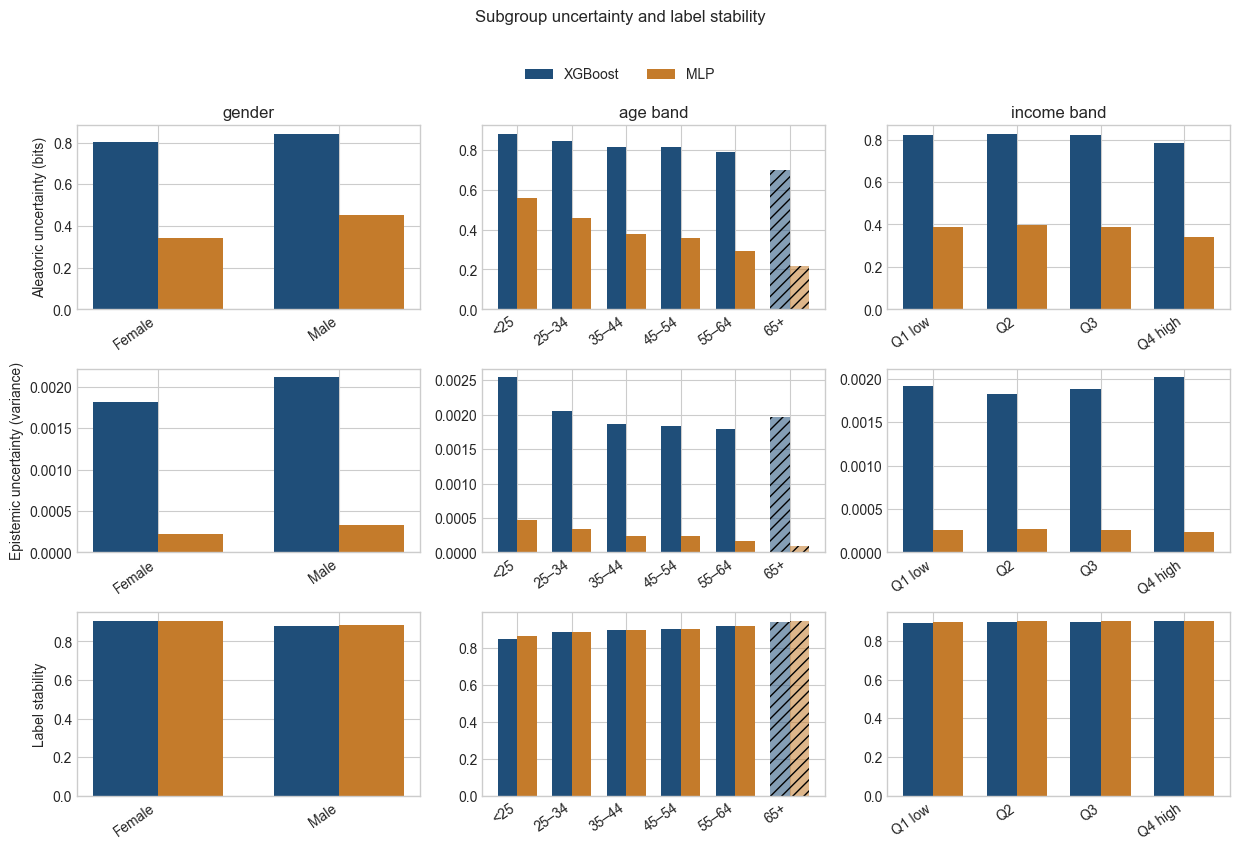

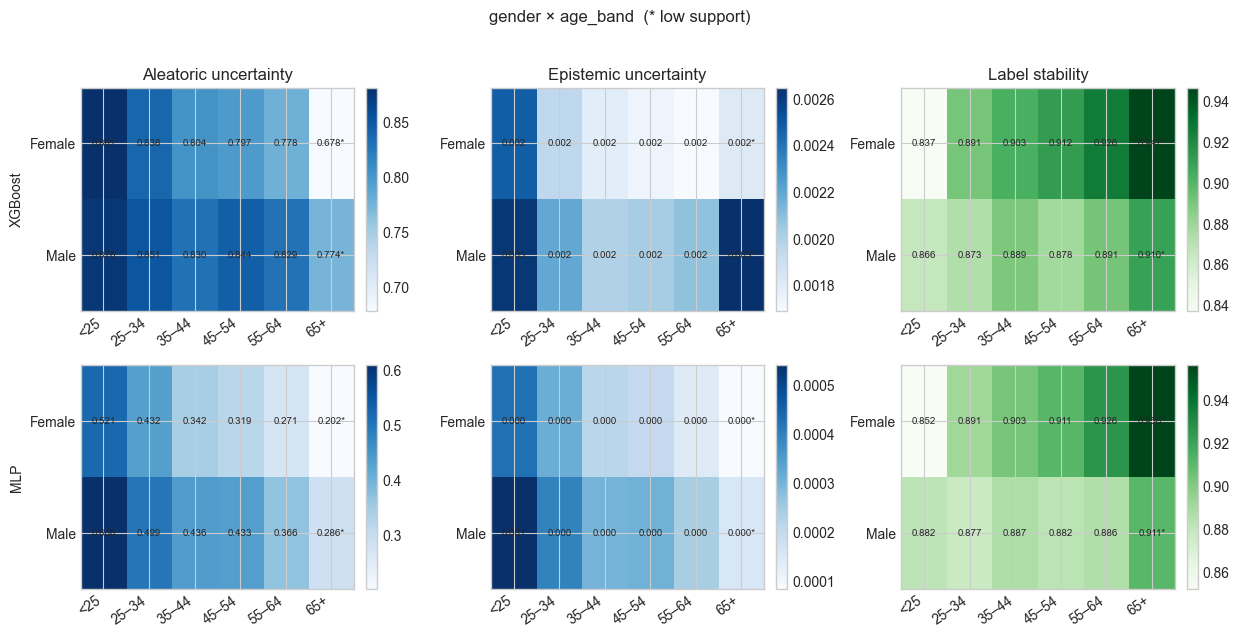

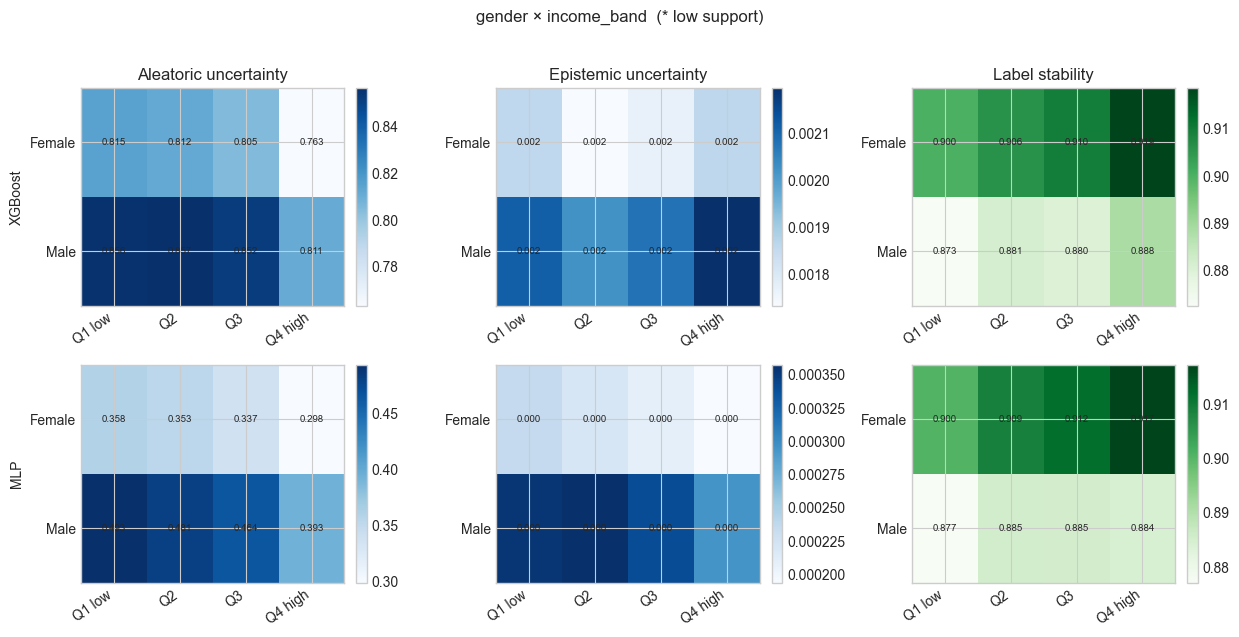

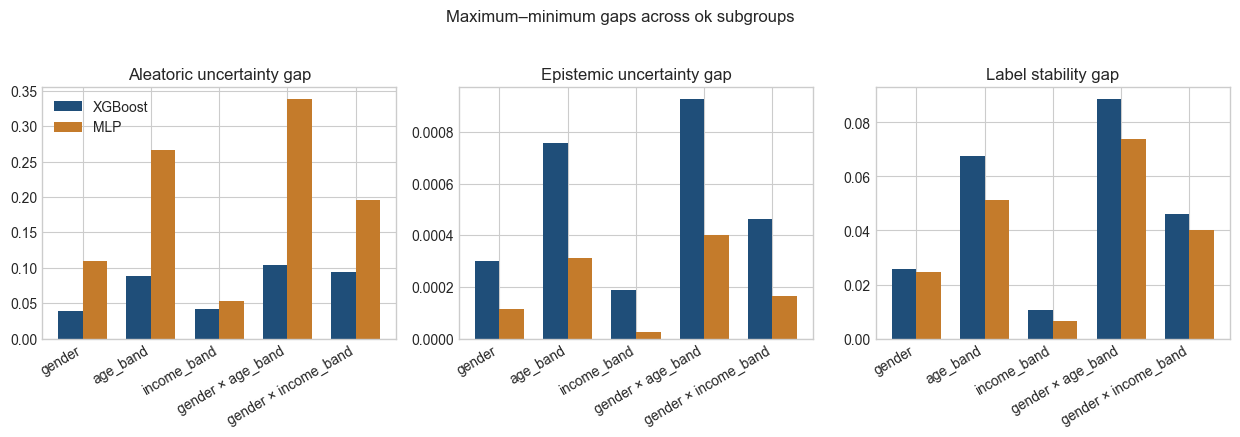

Uncertainty figures saved in output/fairness/figures


In [222]:
AGE_ORDER = ["<25", "25–34", "35–44", "45–54", "55–64", "65+"]
INCOME_ORDER = ["Q1 low", "Q2", "Q3", "Q4 high"]
GENDER_ORDER = ["Female", "Male"]
MODEL_COLORS = {"XGBoost": "#1f4e79", "MLP": "#c47b2b"}
SINGLE_GROUPINGS = ["gender", "age_band", "income_band"]
PLOT_METRICS = [
    ("aleatoric_uncertainty", "Aleatoric uncertainty (bits)"),
    ("epistemic_uncertainty", "Epistemic uncertainty (variance)"),
    ("label_stability", "Label stability"),
]


def ordered_subgroups(grouping, present):
    preferred = {"gender": GENDER_ORDER, "age_band": AGE_ORDER, "income_band": INCOME_ORDER}.get(grouping)
    if preferred is None:
        return sorted(present)
    return [label for label in preferred if label in set(present)]


def comparison_figure():
    figure, axes = plt.subplots(len(PLOT_METRICS), len(SINGLE_GROUPINGS), figsize=(12.5, 8.5), squeeze=False)
    for row, (metric, ylabel) in enumerate(PLOT_METRICS):
        for col, grouping in enumerate(SINGLE_GROUPINGS):
            axis = axes[row, col]
            part = subgroup_uncertainty[subgroup_uncertainty["grouping_variable"].eq(grouping)]
            labels = ordered_subgroups(grouping, part["subgroup"].tolist())
            positions = np.arange(len(labels))
            for offset, model_name in enumerate(["XGBoost", "MLP"]):
                model_part = part[part["model"].eq(model_name)].set_index("subgroup").loc[labels]
                bars = axis.bar(
                    positions + (offset - 0.5) * 0.36,
                    model_part[metric].to_numpy(),
                    width=0.36,
                    color=MODEL_COLORS[model_name],
                    label=model_name if row == 0 and col == 0 else None,
                )
                for bar, flag in zip(bars, model_part["support_flag"]):
                    if flag != "ok":
                        bar.set_hatch("///")
                        bar.set_alpha(0.55)
            axis.set_xticks(positions, labels, rotation=35, ha="right")
            if row == 0:
                axis.set_title(grouping.replace("_", " "))
            if col == 0:
                axis.set_ylabel(ylabel)
    handles, legend_labels = axes[0, 0].get_legend_handles_labels()
    figure.tight_layout(rect=(0, 0, 1, 0.90))
    figure.legend(
        handles, legend_labels, loc="lower center", ncol=2, frameon=False,
        bbox_to_anchor=(0.5, 0.90), borderaxespad=0.2,
    )
    figure.suptitle("Subgroup uncertainty and label stability", y=0.995)
    return figure


def intersection_levels(grouping):
    if grouping == "gender × age_band":
        return GENDER_ORDER, AGE_ORDER
    return GENDER_ORDER, INCOME_ORDER


def intersection_figure(grouping):
    row_labels, column_labels = intersection_levels(grouping)
    figure, axes = plt.subplots(2, 3, figsize=(12.5, 6.2), squeeze=False)
    part = subgroup_uncertainty[subgroup_uncertainty["grouping_variable"].eq(grouping)].copy()
    split = part["subgroup"].str.split(" | ", n=1, regex=False, expand=True)
    part["row_label"] = split[0]
    part["column_label"] = split[1]
    for row, model_name in enumerate(["XGBoost", "MLP"]):
        model_part = part[part["model"].eq(model_name)]
        for col, (metric, title) in enumerate(PLOT_METRICS):
            axis = axes[row, col]
            values = np.full((len(row_labels), len(column_labels)), np.nan)
            flags = np.full((len(row_labels), len(column_labels)), "", dtype=object)
            indexed = model_part.set_index(["row_label", "column_label"])
            for i, row_label in enumerate(row_labels):
                for j, column_label in enumerate(column_labels):
                    if (row_label, column_label) not in indexed.index:
                        continue
                    values[i, j] = indexed.loc[(row_label, column_label), metric]
                    flags[i, j] = indexed.loc[(row_label, column_label), "support_flag"]
            image = axis.imshow(values, cmap="Blues" if metric != "label_stability" else "Greens", aspect="auto")
            axis.set_xticks(np.arange(len(column_labels)), column_labels, rotation=35, ha="right")
            axis.set_yticks(np.arange(len(row_labels)), row_labels)
            finite = values[np.isfinite(values)]
            span = float(finite.max() - finite.min()) if len(finite) else 1.0
            for i in range(values.shape[0]):
                for j in range(values.shape[1]):
                    if not np.isfinite(values[i, j]):
                        continue
                    marker = "*" if flags[i, j] != "ok" else ""
                    axis.text(j, i, f"{values[i, j]:.3f}{marker}", ha="center", va="center", fontsize=7)
            if row == 0:
                axis.set_title(title.split(" (")[0])
            if col == 0:
                axis.set_ylabel(model_name)
            figure.colorbar(image, ax=axis, fraction=0.046, pad=0.04)
    figure.suptitle(f"{grouping}  (* low support)", y=1.02)
    figure.tight_layout()
    return figure


def gap_figure():
    figure, axes = plt.subplots(1, 3, figsize=(12.5, 4.2), squeeze=False)
    labels = [str(label) for label in selected_groupings]
    positions = np.arange(len(labels))
    gap_columns = {
        "aleatoric_uncertainty": "aleatoric_uncertainty_gap",
        "epistemic_uncertainty": "epistemic_uncertainty_gap",
        "label_stability": "label_stability_gap",
    }
    for axis, (metric, title) in zip(axes[0], PLOT_METRICS):
        column = gap_columns[metric]
        for offset, model_name in enumerate(["XGBoost", "MLP"]):
            values = uncertainty_gaps[uncertainty_gaps["model"].eq(model_name)].set_index("grouping_variable").loc[labels, column]
            axis.bar(
                positions + (offset - 0.5) * 0.36,
                values.to_numpy(),
                width=0.36,
                color=MODEL_COLORS[model_name],
                label=model_name,
            )
        axis.set_xticks(positions, labels, rotation=30, ha="right")
        axis.set_title(title.split(" (")[0] + " gap")
    axes[0, 0].legend(frameon=False)
    figure.suptitle("Maximum–minimum gaps across ok subgroups", y=1.03)
    figure.tight_layout()
    return figure


comparison = comparison_figure()
comparison.savefig(FIGURE_DIR / "subgroup_uncertainty_comparison.png", dpi=160, bbox_inches="tight")
display(comparison)
plt.close(comparison)
for grouping, filename in [
    ("gender × age_band", "uncertainty_gender_age.png"),
    ("gender × income_band", "uncertainty_gender_income.png"),
]:
    figure = intersection_figure(grouping)
    figure.savefig(FIGURE_DIR / filename, dpi=160, bbox_inches="tight")
    display(figure)
    plt.close(figure)
gaps_plot = gap_figure()
gaps_plot.savefig(FIGURE_DIR / "uncertainty_gaps.png", dpi=160, bbox_inches="tight")
display(gaps_plot)
plt.close(gaps_plot)
print("Uncertainty figures saved in", FIGURE_DIR)


In [223]:
def subgroup_means_for_prefix(n_models):
    rows = []
    for model_name in ["XGBoost", "MLP"]:
        metrics = applicant_uncertainty(bootstrap_probabilities[model_name][:n_models], uncertainty_thresholds[model_name])
        metric_frame = pd.DataFrame(metrics, index=audit_test.index)
        for grouping in selected_groupings:
            grouped = metric_frame.groupby(audit_test[grouping].astype("string"), observed=True, dropna=False)
            summary = grouped[UNCERTAINTY_METRICS].mean().reset_index(names="subgroup")
            summary.insert(0, "grouping_variable", grouping)
            summary.insert(1, "model", model_name)
            rows.append(summary)
    return pd.concat(rows, ignore_index=True)


full_means = subgroup_uncertainty[["grouping_variable", "subgroup", "model", *UNCERTAINTY_METRICS]].copy()
stability_rows = []
for n_models in (10, 20, N_BOOTSTRAP_MODELS):
    prefix = subgroup_means_for_prefix(n_models)
    prefix["subgroup"] = prefix["subgroup"].astype(str)
    merged = prefix.merge(
        full_means, on=["grouping_variable", "subgroup", "model"], suffixes=("_prefix", "_full")
    )
    for metric in UNCERTAINTY_METRICS:
        deviation = (merged[f"{metric}_prefix"] - merged[f"{metric}_full"]).abs()
        stability_rows.append({
            "ensemble_size": n_models,
            "metric": metric,
            "max_abs_change_vs_full": float(deviation.max()),
            "mean_abs_change_vs_full": float(deviation.mean()),
        })
ensemble_stability = pd.DataFrame(stability_rows)
ensemble_stability_display = ensemble_stability.copy()
for column in ["max_abs_change_vs_full", "mean_abs_change_vs_full"]:
    ensemble_stability_display[column] = ensemble_stability_display[column].map(lambda value: f"{value:.5f}")
print("ENSEMBLE SIZE STABILITY AGAINST THE FULL ENSEMBLE")
display(ensemble_stability_display)
ensemble_stability.to_csv(UNCERTAINTY_DIR / "ensemble_size_stability.csv", index=False)


ENSEMBLE SIZE STABILITY AGAINST THE FULL ENSEMBLE


,ensemble_size,metric,max_abs_change_vs_full,mean_abs_change_vs_full
0,10,aleatoric_uncertainty,0.00760,0.00151
1,10,epistemic_uncertainty,0.00011,0.00001
2,10,label_stability,0.01487,0.00593
3,20,aleatoric_uncertainty,0.00243,0.00062
4,20,epistemic_uncertainty,0.00003,0.00001
5,20,label_stability,0.00326,0.00123
6,30,aleatoric_uncertainty,0.00000,0.00000
7,30,epistemic_uncertainty,0.00000,0.00000
8,30,label_stability,0.00000,0.00000


## 9. SHAP Model Interpretability & Feature Attribution 

This section explains the original XGBoost and MLP predicted default probabilities. `TARGET = 1` is default. The Section 8 bootstrap ensembles are not used, and neither model is retrained.

SHAP values are in probability units for both models. XGBoost uses `shap.TreeExplainer` with `feature_perturbation="interventional"` and `model_output="probability"`. The installed SHAP build cannot parse this XGBoost file's bracketed `base_score` (`[5E-1]`). A local parser converts that string to `0.5` before the explainer is built. Predictions are unchanged. The MLP uses `shap.GradientExplainer` on the sigmoid output, which is already a default probability. `DeepExplainer` is not used.

Both models share one background sample of 1,000 training applicants. SHAP values are computed for every held-out test applicant, so the subgroup counts match Section 3. Each applicant has equal weight. `support_flag` is the original Section 3 flag.

One-hot columns are added back into their original feature before the reported importances are calculated. For each applicant the family attribution is the sum of the encoded columns, and the mean absolute importance is computed after that sum. Encoded-column importances are saved separately.


In [226]:
import inspect
import platform
import textwrap
import shap
import shap.explainers._tree as shap_tree

RANDOM_STATE = 42
BACKGROUND_SIZE = 1000
THIN_SHAP_COUNT = 20
SHAP_DIR = AUDIT_DIR / "shap"
SHAP_DIR.mkdir(parents=True, exist_ok=True)
ONE_HOT_PREFIXES = (
    "NAME_CONTRACT_TYPE_", "CODE_GENDER_", "FLAG_OWN_CAR_", "FLAG_OWN_REALTY_",
    "NAME_TYPE_SUITE_", "NAME_INCOME_TYPE_", "NAME_FAMILY_STATUS_", "NAME_HOUSING_TYPE_",
    "WEEKDAY_APPR_PROCESS_START_", "ORGANIZATION_TYPE_", "OCCUPATION_TYPE_",
)
CONTRASTS = [
    ("gender", "Female", "Male"),
    ("age_band", "<25", "55–64"),
    ("income_band", "Q1 low", "Q4 high"),
    ("gender × income_band", "Female | Q1 low", "Male | Q1 low"),
    ("gender × income_band", "Female | Q4 high", "Male | Q4 high"),
]


def _parse_xgb_base_score(value):
    if isinstance(value, str):
        text = value.strip()
        if text.startswith("["):
            text = text.strip("[]").split(",")[0]
        return float(text)
    return float(value)


_BASE_SCORE_FLOAT_CALL = 'float(learner_model_param["base_score"])'


def _is_dynamic_function(func):
    filename = getattr(getattr(func, "__code__", None), "co_filename", "")
    return isinstance(filename, str) and filename.startswith("<") and filename.endswith(">")


def _is_our_base_score_patch(func):
    # The marker covers a patch from this version of the cell. The code-name check covers
    # a parser already installed earlier in this kernel, before the marker existed.
    if getattr(func, "_xgb_base_score_patch", False):
        return True
    code = getattr(func, "__code__", None)
    return code is not None and "_parse_xgb_base_score" in code.co_names


def _install_xgboost_shap_parser():
    # XGBoost serializes base_score as a string such as "[5E-1]". SHAP 0.49.1 passes that
    # string to float(). Rewrite that call once per kernel. A SHAP build that no longer has
    # the call does not need the rewrite, and a later run must not call inspect.getsource
    # on the function created by exec.
    current = shap_tree.XGBTreeModelLoader.__init__
    if _is_our_base_score_patch(current):
        return
    if _is_dynamic_function(current):
        raise OSError(
            "XGBTreeModelLoader.__init__ is a dynamically generated function "
            f"({current.__code__.co_filename}) and is not this notebook's base_score parser. "
            "Restart the kernel and rerun this cell."
        )
    try:
        source = textwrap.dedent(inspect.getsource(current))
    except OSError as exc:
        raise OSError(
            "Could not read XGBTreeModelLoader.__init__ to install the XGBoost base_score parser. "
            "Restart the kernel and rerun this cell."
        ) from exc
    if _BASE_SCORE_FLOAT_CALL not in source:
        return
    source = source.replace(
        _BASE_SCORE_FLOAT_CALL,
        '_parse_xgb_base_score(learner_model_param["base_score"])',
    )
    globs = dict(shap_tree.__dict__)
    globs["_parse_xgb_base_score"] = _parse_xgb_base_score
    exec(source, globs)
    patched = globs["__init__"]
    patched._xgb_base_score_patch = True
    shap_tree.XGBTreeModelLoader.__init__ = patched


def feature_family(name):
    for prefix in ONE_HOT_PREFIXES:
        if name.startswith(prefix):
            return prefix[:-1]
    return name


def weighted_mean(values, weights):
    values = np.asarray(values, dtype=float)
    weights = np.asarray(weights, dtype=float)
    return float(np.sum(weights * values) / np.sum(weights))


def shap_matrix(raw):
    if hasattr(raw, "values"):
        values = np.asarray(raw.values)
    else:
        values = np.asarray(raw)
    if values.ndim == 3 and values.shape[-1] == 1:
        values = values[..., 0]
    if values.ndim == 3 and values.shape[-1] == 2:
        values = values[..., 1]
    return values


def family_matrix(values):
    groups = {}
    for index, name in enumerate(feature_names):
        groups.setdefault(feature_family(name), []).append(index)
    names = list(groups)
    stacked = np.column_stack([values[:, groups[name]].sum(axis=1) for name in names])
    return names, stacked


_install_xgboost_shap_parser()
if list(X_test.columns) != list(feature_names):
    raise AssertionError("Transformed test columns do not match the saved feature names.")

X_train_matrix = np.asarray(preprocessor.transform(X_train_raw), dtype=np.float32)
X_test_matrix = X_test.to_numpy(dtype=np.float32)
rng = np.random.default_rng(RANDOM_STATE)
background_index = np.sort(rng.choice(len(X_train_matrix), size=BACKGROUND_SIZE, replace=False))
sample_index = np.arange(len(X_test_matrix))
weights = np.ones(len(sample_index), dtype=float)

cache_key = {
    "random_state": RANDOM_STATE,
    "background_size": BACKGROUND_SIZE,
    "sample_size": int(len(sample_index)),
    "test_id_first": int(audit_test["SK_ID_CURR"].iloc[0]),
    "test_id_last": int(audit_test["SK_ID_CURR"].iloc[-1]),
    "n_features": int(len(feature_names)),
}
metadata_path = SHAP_DIR / "metadata.json"
matrix_paths = {name: SHAP_DIR / f"{name.lower()}_shap.npy" for name in ["XGBoost", "MLP"]}
if metadata_path.exists() and all(path.exists() for path in matrix_paths.values()):
    stored = json.loads(metadata_path.read_text())
    if all(stored.get(key) == value for key, value in cache_key.items()):
        sample_index = np.load(SHAP_DIR / "sample_index.npy")
        weights = np.load(SHAP_DIR / "weights.npy")
        background_index = np.load(SHAP_DIR / "background_index.npy")
        shap_values = {name: np.load(path) for name, path in matrix_paths.items()}
        baselines = {name: float(stored["baselines"][name]) for name in ["XGBoost", "MLP"]}
        reconstruction = stored["reconstruction"]
        print("Loaded cached SHAP values.")
    else:
        stored = None
else:
    stored = None

if stored is None:
    background = X_train_matrix[background_index]
    explained = X_test_matrix[sample_index]
    tree = shap.TreeExplainer(
        xgb_model, data=background, model_output="probability", feature_perturbation="interventional",
    )
    xgb_values = shap_matrix(tree.shap_values(explained, check_additivity=False))
    xgb_base = float(np.ravel(tree.expected_value)[0])
    xgb_pred = xgb_model.predict_proba(explained)[:, 1]
    xgb_error = np.abs(xgb_base + xgb_values.sum(axis=1) - xgb_pred)
    gradient = shap.GradientExplainer((mlp_model.input, mlp_model.output), background)
    mlp_values = shap_matrix(gradient.shap_values(explained))
    mlp_base = float(np.mean(mlp_model.predict(background, verbose=0)))
    mlp_pred = mlp_model.predict(explained, verbose=0).ravel()
    mlp_error = np.abs(mlp_base + mlp_values.sum(axis=1) - mlp_pred)
    reconstruction = {
        "XGBoost": {"max_abs_error": float(xgb_error.max()), "mean_abs_error": float(xgb_error.mean())},
        "MLP": {"max_abs_error": float(mlp_error.max()), "mean_abs_error": float(mlp_error.mean())},
    }
    if reconstruction["XGBoost"]["max_abs_error"] > 1e-3:
        raise AssertionError(f"XGBoost SHAP reconstruction failed: {reconstruction['XGBoost']}")
    if reconstruction["MLP"]["max_abs_error"] > 0.05:
        raise AssertionError(f"MLP SHAP reconstruction failed: {reconstruction['MLP']}")
    if not np.isfinite(xgb_values).all() or not np.isfinite(mlp_values).all():
        raise AssertionError("SHAP values contain a nonfinite number.")
    shap_values = {"XGBoost": xgb_values.astype(np.float32), "MLP": mlp_values.astype(np.float32)}
    baselines = {"XGBoost": xgb_base, "MLP": mlp_base}
    np.save(matrix_paths["XGBoost"], shap_values["XGBoost"])
    np.save(matrix_paths["MLP"], shap_values["MLP"])
    np.save(SHAP_DIR / "sample_index.npy", sample_index)
    np.save(SHAP_DIR / "weights.npy", weights)
    np.save(SHAP_DIR / "background_index.npy", background_index)
    metadata_path.write_text(json.dumps({
        **cache_key,
        "baselines": baselines,
        "reconstruction": reconstruction,
        "versions": {
            "python": platform.python_version(),
            "shap": shap.__version__,
            "xgboost": xgboost.__version__,
            "tensorflow": tf.__version__,
        },
    }, indent=2))
    print("Computed and cached SHAP values.")

for name, values in shap_values.items():
    if values.shape != (len(sample_index), len(feature_names)):
        raise AssertionError(f"{name} SHAP matrix has shape {values.shape}.")
explained_test = audit_test.iloc[sample_index].reset_index(drop=True)
if not np.array_equal(explained_test["SK_ID_CURR"].to_numpy(), audit_test["SK_ID_CURR"].to_numpy()[sample_index]):
    raise AssertionError("SHAP rows are not aligned with the test applicants.")
family_names, family_values = {}, {}
for name, values in shap_values.items():
    names, matrix = family_matrix(values)
    family_names[name] = names
    family_values[name] = matrix
if family_names["XGBoost"] != family_names["MLP"]:
    raise AssertionError("Feature families differ between models.")
family_names = family_names["XGBoost"]
print("SHAP sample:", len(sample_index), "background:", len(background_index))

coverage_rows = []
for grouping in selected_groupings:
    population = population_summary[population_summary["grouping_variable"].eq(grouping)]
    for _, info in population.iterrows():
        explained_count = int((explained_test[grouping].astype(str) == str(info["subgroup"])).sum())
        coverage_rows.append({
            "grouping_variable": grouping,
            "subgroup": str(info["subgroup"]),
            "population_count": int(info["count"]),
            "support_flag": info["support_flag"],
            "shap_count": explained_count,
            "shap_coverage": "ok" if explained_count >= THIN_SHAP_COUNT else "thin",
        })
shap_coverage = pd.DataFrame(coverage_rows)
print("SHAP SAMPLE COVERAGE")
display(shap_coverage)
shap_coverage.to_csv(SHAP_DIR / "shap_sample_coverage.csv", index=False)


100%|===================| 46039/46126 [07:53<00:00]        /Users/beta/Desktop/RDS Audit Project/.audit-venv/lib/python3.11/site-packages/keras/src/backend.py:452: UserWarning: `tf.keras.backend.set_learning_phase` is deprecated and will be removed after 2020-10-11. To update it, simply pass a True/False value to the `training` argument of the `__call__` method of your layer or model.
  warnings.warn(


Computed and cached SHAP values.
SHAP sample: 46126 background: 1000
SHAP SAMPLE COVERAGE


,grouping_variable,subgroup,population_count,support_flag,shap_count,shap_coverage
0,gender,Female,30410,ok,30410,ok
1,gender,Male,15716,ok,15716,ok
2,age_band,25–34,10763,ok,10763,ok
3,age_band,35–44,12731,ok,12731,ok
4,age_band,45–54,10579,ok,10579,ok
5,age_band,55–64,8995,ok,8995,ok
6,age_band,65+,1208,low_support,1208,ok
7,age_band,<25,1850,ok,1850,ok
8,income_band,Q1 low,15123,ok,15123,ok
9,income_band,Q2,7879,ok,7879,ok


### 9.1 Global Feature Importance


GLOBAL SHAP FEATURE IMPORTANCE


,model,feature,mean_abs_shap,mean_signed_shap,n_observations,importance_rank
0,MLP,EXT_SOURCE_3,0.029948,-0.001104,46126,1
1,MLP,EXT_SOURCE_2,0.025560,0.000179,46126,2
2,MLP,EXT_SOURCE_1,0.012773,0.000548,46126,3
3,MLP,CREDIT_GOODS_RATIO,0.010234,-0.000210,46126,4
4,MLP,CODE_GENDER,0.009901,0.000487,46126,5
5,MLP,CREDIT_TERM,0.009358,-0.000253,46126,6
6,MLP,EXT_SOURCE_1_MISSING,0.008204,-0.000292,46126,7
7,MLP,FLAG_OWN_CAR,0.007530,0.000151,46126,8
8,MLP,AMT_CREDIT,0.007522,0.000111,46126,9
9,MLP,FLAG_DOCUMENT_3,0.006592,-0.000128,46126,10


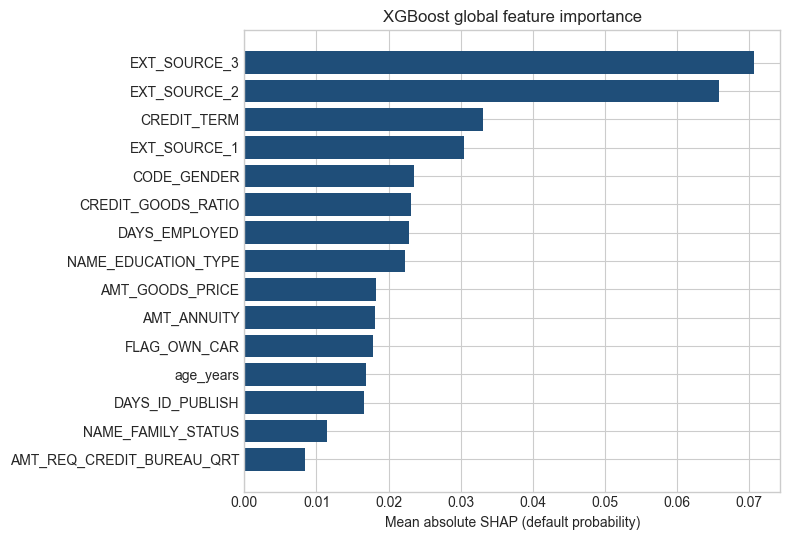

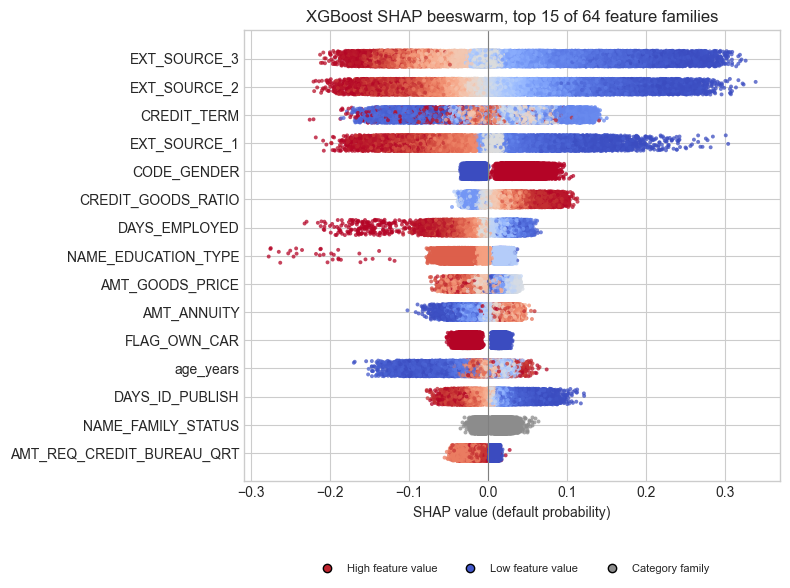

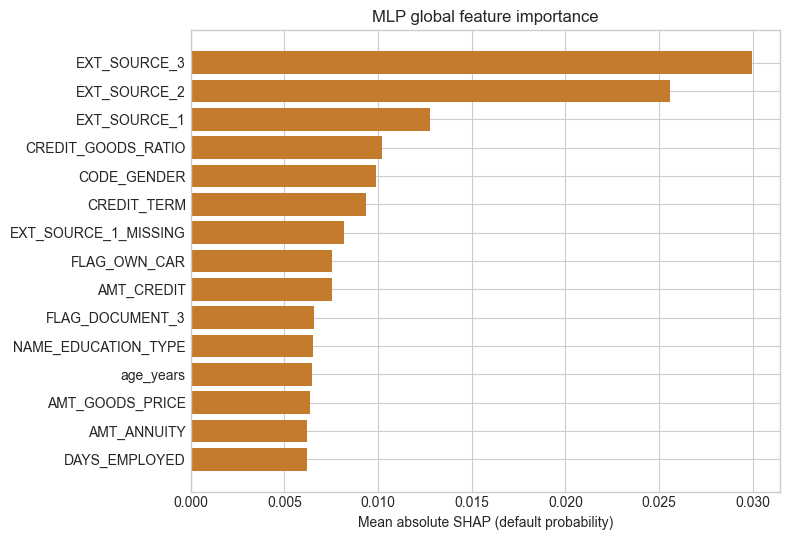

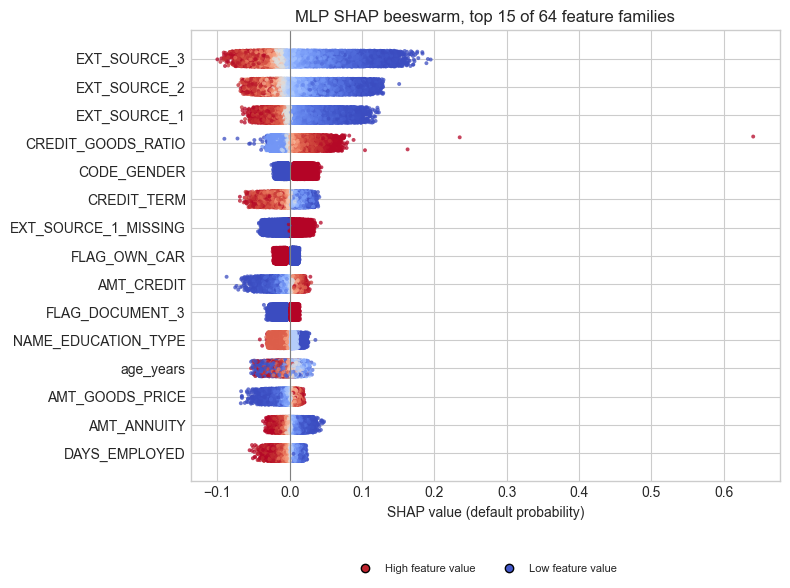

In [227]:
def importance_frame(values_by_model, names):
    rows = []
    for model_name, matrix in values_by_model.items():
        for index, feature in enumerate(names):
            column = matrix[:, index]
            rows.append({
                "model": model_name,
                "feature": feature,
                "mean_abs_shap": weighted_mean(np.abs(column), weights),
                "mean_signed_shap": weighted_mean(column, weights),
                "n_observations": int(len(column)),
            })
    frame = pd.DataFrame(rows)
    frame["importance_rank"] = frame.groupby("model")["mean_abs_shap"].rank(ascending=False, method="min").astype(int)
    return frame.sort_values(["model", "importance_rank", "feature"]).reset_index(drop=True)


encoded_matrices = {
    "XGBoost": shap_values["XGBoost"].astype(float),
    "MLP": shap_values["MLP"].astype(float),
}
encoded_importance = importance_frame(encoded_matrices, list(feature_names))
global_importance = importance_frame(family_values, family_names)
encoded_importance.to_csv(SHAP_DIR / "global_shap_encoded.csv", index=False)
global_importance.to_csv(SHAP_DIR / "global_shap_feature_importance.csv", index=False)
global_top = global_importance[global_importance["importance_rank"].le(15)].copy()
global_display = global_top.copy()
for column in ["mean_abs_shap", "mean_signed_shap"]:
    global_display[column] = global_display[column].map(lambda value: f"{value:.6f}")
print("GLOBAL SHAP FEATURE IMPORTANCE")
display(global_display)

def importance_bars(model_name):
    part = global_top[global_top["model"].eq(model_name)].sort_values("mean_abs_shap")
    figure, axis = plt.subplots(figsize=(8, 5.5))
    axis.barh(part["feature"], part["mean_abs_shap"], color="#1f4e79" if model_name == "XGBoost" else "#c47b2b")
    axis.set_xlabel("Mean absolute SHAP (default probability)")
    axis.set_title(f"{model_name} global feature importance")
    figure.tight_layout()
    figure.savefig(FIGURE_DIR / f"shap_global_{model_name.lower()}.png", dpi=160, bbox_inches="tight")
    display(figure)
    plt.close(figure)

family_columns = {}
for feature_index, feature_name in enumerate(feature_names):
    family_columns.setdefault(feature_family(feature_name), []).append(feature_index)

def beeswarm(model_name):
    ranks = global_importance[global_importance["model"].eq(model_name)].sort_values("importance_rank")
    chosen = ranks["feature"].head(15).tolist()[::-1]
    matrix = family_values[model_name]
    figure, axis = plt.subplots(figsize=(8, 6))
    for position, feature in enumerate(chosen):
        member_indexes = family_columns[feature]
        shap_column = matrix[:, family_names.index(feature)]
        jitter = np.random.default_rng(RANDOM_STATE + position).uniform(-0.28, 0.28, len(shap_column))
        vertical = np.full(len(shap_column), position) + jitter
        if len(member_indexes) == 1:
            color = pd.Series(explained_matrix[:, member_indexes[0]]).rank(pct=True).to_numpy()
            axis.scatter(shap_column, vertical, c=color, cmap="coolwarm", s=8, alpha=0.75, linewidths=0)
        else:
            axis.scatter(shap_column, vertical, c="0.55", s=8, alpha=0.75, linewidths=0)
    axis.set_yticks(range(len(chosen)), chosen)
    axis.axvline(0, color="0.5", lw=0.8)
    axis.set_xlabel("SHAP value (default probability)")
    axis.set_title(f"{model_name} SHAP beeswarm, top 15 of 64 feature families")
    legend_handles = [
        plt.Line2D([0], [0], marker="o", color="none", markerfacecolor=plt.cm.coolwarm(0.97), markersize=6, label="High feature value"),
        plt.Line2D([0], [0], marker="o", color="none", markerfacecolor=plt.cm.coolwarm(0.03), markersize=6, label="Low feature value"),
    ]
    if any(len(family_columns[feature]) > 1 for feature in chosen):
        legend_handles.append(
            plt.Line2D([0], [0], marker="o", color="none", markerfacecolor="0.55", markersize=6, label="Category family")
        )
    axis.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, frameon=False, fontsize=8)
    figure.tight_layout()
    figure.savefig(FIGURE_DIR / f"shap_beeswarm_{model_name.lower()}.png", dpi=160, bbox_inches="tight")
    display(figure)
    plt.close(figure)

explained_matrix = X_test_matrix[sample_index]
for model_name in ["XGBoost", "MLP"]:
    importance_bars(model_name)
    beeswarm(model_name)


GENDER, AGE, AND INCOME SHAP


,model,feature,mean_abs_shap,mean_signed_shap,n_observations,importance_rank
0,MLP,CODE_GENDER,0.009901,0.000487,46126,5
1,MLP,age_years,0.006491,-0.000027,46126,12
2,MLP,AMT_INCOME_TOTAL,0.002665,0.000250,46126,25
3,XGBoost,CODE_GENDER,0.023475,0.003781,46126,5
4,XGBoost,age_years,0.016857,-0.001795,46126,12
5,XGBoost,AMT_INCOME_TOTAL,0.003226,-0.000026,46126,35


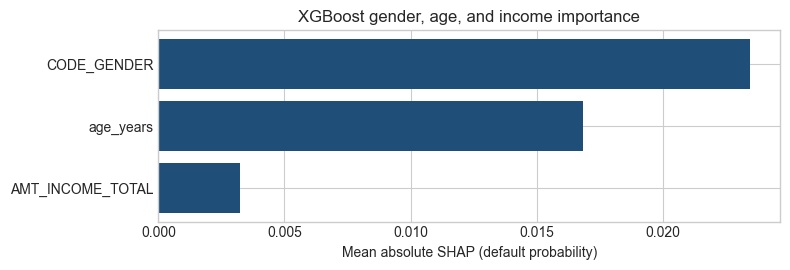

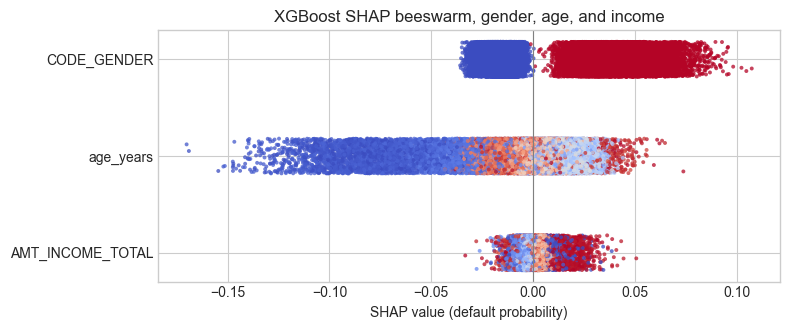

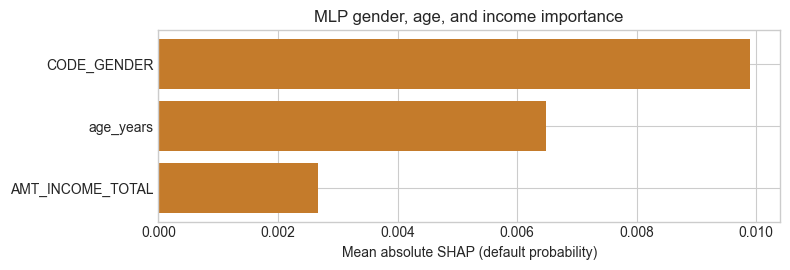

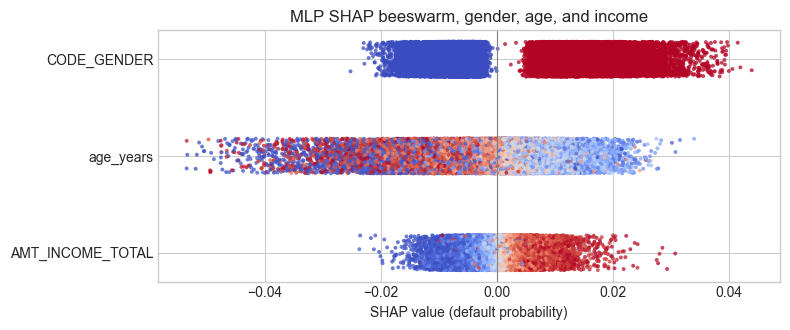

In [228]:
FOCUS_FEATURES = ["CODE_GENDER", "age_years", "AMT_INCOME_TOTAL"]
ENCODED_FOCUS = {
    "CODE_GENDER": "CODE_GENDER_M",
    "age_years": "age_years",
    "AMT_INCOME_TOTAL": "AMT_INCOME_TOTAL",
}
focus = global_importance[global_importance["feature"].isin(FOCUS_FEATURES)].copy()
if set(focus["feature"]) != set(FOCUS_FEATURES) or focus.groupby("model").size().ne(len(FOCUS_FEATURES)).any():
    raise AssertionError("Gender, age, or income is missing from the SHAP feature families.")
focus = focus.sort_values(["model", "importance_rank", "feature"]).reset_index(drop=True)
focus.to_csv(SHAP_DIR / "gender_age_income_shap.csv", index=False)
focus_display = focus.copy()
for column in ["mean_abs_shap", "mean_signed_shap"]:
    focus_display[column] = focus_display[column].map(lambda value: f"{value:.6f}")
print("GENDER, AGE, AND INCOME SHAP")
display(focus_display)

def focus_bars(model_name):
    part = focus[focus["model"].eq(model_name)].sort_values("mean_abs_shap")
    figure, axis = plt.subplots(figsize=(8, 2.8))
    axis.barh(part["feature"], part["mean_abs_shap"], color="#1f4e79" if model_name == "XGBoost" else "#c47b2b")
    axis.set_xlabel("Mean absolute SHAP (default probability)")
    axis.set_title(f"{model_name} gender, age, and income importance")
    figure.tight_layout()
    figure.savefig(FIGURE_DIR / f"shap_gender_age_income_{model_name.lower()}.png", dpi=160, bbox_inches="tight")
    display(figure)
    plt.close(figure)

def focus_beeswarm(model_name):
    order = focus[focus["model"].eq(model_name)].sort_values("importance_rank")["feature"].tolist()
    encoded_names = [ENCODED_FOCUS[feature] for feature in order][::-1]
    indexes = [list(feature_names).index(feature) for feature in encoded_names]
    matrix = encoded_matrices[model_name]
    figure, axis = plt.subplots(figsize=(8, 3.4))
    for position, feature_index in enumerate(indexes):
        color = pd.Series(explained_matrix[:, feature_index]).rank(pct=True).to_numpy()
        jitter = np.random.default_rng(RANDOM_STATE + position).uniform(-0.18, 0.18, len(matrix))
        axis.scatter(
            matrix[:, feature_index],
            np.full(len(matrix), position) + jitter,
            c=color, cmap="coolwarm", s=8, alpha=0.75, linewidths=0,
        )
    axis.set_yticks(range(len(order)), order[::-1])
    axis.axvline(0, color="0.5", lw=0.8)
    axis.set_xlabel("SHAP value (default probability)")
    axis.set_title(f"{model_name} SHAP beeswarm, gender, age, and income")
    figure.tight_layout()
    figure.savefig(FIGURE_DIR / f"shap_beeswarm_gender_age_income_{model_name.lower()}.png", dpi=160, bbox_inches="tight")
    display(figure)
    plt.close(figure)

for model_name in ["XGBoost", "MLP"]:
    focus_bars(model_name)
    focus_beeswarm(model_name)


### 9.2 Subgroup Feature Importance


In [229]:
support_lookup = population_summary.loc[
    population_summary["grouping_variable"].isin(selected_groupings),
    ["grouping_variable", "subgroup", "support_flag"],
].copy()
support_lookup["subgroup"] = support_lookup["subgroup"].astype(str)

def subgroup_importance(values_by_model, names):
    rows = []
    for model_name, matrix in values_by_model.items():
        for grouping in selected_groupings:
            labels = explained_test[grouping].astype(str)
            for subgroup, count in labels.value_counts().items():
                mask = labels.eq(subgroup).to_numpy()
                group_weights = weights[mask]
                for index, feature in enumerate(names):
                    column = matrix[mask, index]
                    rows.append({
                        "model": model_name,
                        "grouping_variable": grouping,
                        "subgroup": str(subgroup),
                        "feature": feature,
                        "count": int(count),
                        "mean_abs_shap": weighted_mean(np.abs(column), group_weights),
                        "mean_signed_shap": weighted_mean(column, group_weights),
                    })
    frame = pd.DataFrame(rows)
    frame = frame.merge(support_lookup, on=["grouping_variable", "subgroup"], how="left")
    if frame["support_flag"].isna().any():
        raise AssertionError("A SHAP subgroup is missing its Section 3 support flag.")
    frame["subgroup_feature_rank"] = frame.groupby(
        ["model", "grouping_variable", "subgroup"]
    )["mean_abs_shap"].rank(ascending=False, method="min").astype(int)
    return frame.sort_values(
        ["grouping_variable", "model", "subgroup", "subgroup_feature_rank"]
    ).reset_index(drop=True)


subgroup_shap = subgroup_importance(family_values, family_names)
subgroup_top = subgroup_shap[subgroup_shap["subgroup_feature_rank"].le(5)].copy()
subgroup_display = subgroup_top.copy()
for column in ["mean_abs_shap", "mean_signed_shap"]:
    subgroup_display[column] = subgroup_display[column].map(lambda value: f"{value:.6f}")
heatmap_features = (
    global_importance.groupby("feature")["mean_abs_shap"].mean().nlargest(15).index.tolist()
)
AGE_ORDER = ["<25", "25–34", "35–44", "45–54", "55–64", "65+"]
INCOME_ORDER = ["Q1 low", "Q2", "Q3", "Q4 high"]
GENDER_ORDER = ["Female", "Male"]

def subgroup_sort_key(grouping, label):
    if grouping == "gender":
        return GENDER_ORDER.index(label) if label in GENDER_ORDER else 99
    if grouping == "age_band":
        return AGE_ORDER.index(label) if label in AGE_ORDER else 99
    if grouping == "income_band":
        return INCOME_ORDER.index(label) if label in INCOME_ORDER else 99
    gender, rest = label.split(" | ", 1)
    secondary = AGE_ORDER if "age" in grouping else INCOME_ORDER
    return (GENDER_ORDER.index(gender), secondary.index(rest) if rest in secondary else 99)

def order_subgroup_table(frame):
    pieces = []
    for grouping in selected_groupings:
        part = frame[frame["grouping_variable"].eq(grouping)].copy()
        part["_model_order"] = part["model"].map({"MLP": 0, "XGBoost": 1})
        part["_subgroup_order"] = [subgroup_sort_key(grouping, label) for label in part["subgroup"]]
        pieces.append(
            part.sort_values(["_model_order", "_subgroup_order", "subgroup_feature_rank"])
            .drop(columns=["_model_order", "_subgroup_order"])
        )
    return pd.concat(pieces, ignore_index=True)

subgroup_shap = order_subgroup_table(subgroup_shap)
subgroup_shap.to_csv(SHAP_DIR / "subgroup_shap_feature_importance.csv", index=False)
subgroup_display = order_subgroup_table(subgroup_display)

def subgroup_top5_bars(grouping):
    ranked = subgroup_shap[
        subgroup_shap["grouping_variable"].eq(grouping) & subgroup_shap["subgroup_feature_rank"].le(5)
    ]
    labels = sorted(ranked["subgroup"].unique(), key=lambda label: subgroup_sort_key(grouping, label))
    safe_name = grouping.replace(" × ", "_").replace(" ", "_")
    print(f"SUBGROUP TOP 5 FEATURE IMPORTANCE: {grouping}")
    for model_name, color in (("XGBoost", "#1f4e79"), ("MLP", "#c47b2b")):
        part = ranked[ranked["model"].eq(model_name)]
        columns = 2 if len(labels) <= 6 else 3
        row_count = int(np.ceil(len(labels) / columns))
        figure, axes = plt.subplots(row_count, columns, figsize=(6.4 * columns, 2.9 * row_count), squeeze=False, layout="constrained")
        limit = float(part["mean_abs_shap"].max()) * 1.05
        flags = part.drop_duplicates("subgroup").set_index("subgroup")["support_flag"]
        for axis, label in zip(axes.ravel(), labels):
            rows = part[part["subgroup"].eq(label)].sort_values("mean_abs_shap")
            axis.barh(rows["feature"], rows["mean_abs_shap"], color=color)
            axis.set_xlim(0, limit)
            axis.set_title(label if flags.loc[label] == "ok" else f"{label} *", loc="left", fontsize=10)
            axis.tick_params(axis="y", labelsize=8)
        for axis in axes.ravel()[len(labels):]:
            axis.axis("off")
        for axis in axes[-1]:
            if axis.axison:
                axis.set_xlabel("Mean absolute SHAP (default probability)")
        figure.suptitle(f"{model_name} subgroup top 5 feature importance")
        figure.savefig(FIGURE_DIR / f"shap_top5_{safe_name}_{model_name.lower()}.png", dpi=140, bbox_inches="tight")
        display(figure)
        plt.close(figure)

def subgroup_top5_comparison(grouping):
    part = subgroup_shap[subgroup_shap["grouping_variable"].eq(grouping)]
    labels = sorted(part["subgroup"].unique(), key=lambda label: subgroup_sort_key(grouping, label))
    safe_name = grouping.replace(" × ", "_").replace(" ", "_")
    colors = ["#1b4f72", "#148f77", "#d68910", "#922b21", "#6c3483", "#1e8449", "#2e86ab", "#b03a2e", "#7d3c98", "#b7950b", "#1a5276", "#117a65"]
    print(f"SUBGROUP TOP 5 FEATURE COMPARISON: {grouping}")
    for model_name in ["XGBoost", "MLP"]:
        model_part = part[part["model"].eq(model_name)]
        features = model_part.loc[model_part["subgroup_feature_rank"].le(5), "feature"].drop_duplicates()
        compared = model_part[model_part["feature"].isin(features)]
        feature_order = compared.groupby("feature")["mean_abs_shap"].max().sort_values().index.tolist()
        positions = np.arange(len(feature_order))
        bar_height = 0.8 / len(labels)
        figure, axis = plt.subplots(figsize=(10, 0.72 * len(feature_order) + 1.4))
        flags = model_part.drop_duplicates("subgroup").set_index("subgroup")["support_flag"]
        for index, label in enumerate(labels):
            rows = compared[compared["subgroup"].eq(label)].set_index("feature").loc[feature_order]
            offset = ((len(labels) - 1) / 2 - index) * bar_height
            legend_label = label if flags.loc[label] == "ok" else f"{label} *"
            if grouping == "gender":
                color = {"Female": "#c0392b", "Male": "#1f4e79"}[label]
            else:
                color = colors[index]
            axis.barh(positions + offset, rows["mean_abs_shap"], height=bar_height * 0.9, color=color, label=legend_label)
        axis.set_yticks(positions, feature_order)
        axis.set_xlabel("Mean absolute SHAP (default probability)")
        axis.set_title(f"{model_name} top 5 features across subgroups")
        axis.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=8)
        figure.tight_layout()
        figure.savefig(FIGURE_DIR / f"shap_top5_compare_{safe_name}_{model_name.lower()}.png", dpi=140, bbox_inches="tight")
        display(figure)
        plt.close(figure)


def show_subgroup_shap(grouping):
    importance = subgroup_display[subgroup_display["grouping_variable"].eq(grouping)]
    print(f"SUBGROUP SHAP FEATURE IMPORTANCE: {grouping}")
    with pd.option_context("display.max_rows", None, "display.max_columns", None):
        display(importance)
    subgroup_top5_bars(grouping)
    if grouping == "gender":
        subgroup_top5_comparison(grouping)

    figure, axes = plt.subplots(2, 1, figsize=(18, 8), squeeze=False)
    parts = []
    for model_name in ["XGBoost", "MLP"]:
        part = subgroup_shap[
            subgroup_shap["model"].eq(model_name) & subgroup_shap["grouping_variable"].eq(grouping)
            & subgroup_shap["feature"].isin(heatmap_features)
        ]
        parts.append(part)
    limit = max(
        abs(parts[0]["mean_signed_shap"].max()), abs(parts[0]["mean_signed_shap"].min()),
        abs(parts[1]["mean_signed_shap"].max()), abs(parts[1]["mean_signed_shap"].min()),
    )
    for axis, model_name, part in zip(axes[:, 0], ["XGBoost", "MLP"], parts):
        labels = sorted(part["subgroup"].unique(), key=lambda label: subgroup_sort_key(grouping, label))
        grid = np.full((len(labels), len(heatmap_features)), np.nan)
        flags = {}
        for _, row in part.iterrows():
            grid[labels.index(row["subgroup"]), heatmap_features.index(row["feature"])] = row["mean_signed_shap"]
            flags[row["subgroup"]] = row["support_flag"]
        image = axis.imshow(grid, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
        axis.set_xticks(range(len(heatmap_features)), heatmap_features, rotation=60, ha="right", fontsize=8)
        axis.set_yticks(range(len(labels)), [label if flags.get(label) == "ok" else f"{label} *" for label in labels])
        axis.set_title(model_name)
        figure.colorbar(image, ax=axis, fraction=0.03, pad=0.02)
    figure.suptitle(f"{grouping} mean signed SHAP", y=1.01)
    figure.tight_layout()
    safe_name = grouping.replace(" × ", "_").replace(" ", "_")
    figure.savefig(FIGURE_DIR / f"shap_heatmap_{safe_name}.png", dpi=140, bbox_inches="tight")
    display(figure)
    plt.close(figure)


SUBGROUP SHAP FEATURE IMPORTANCE: gender


,model,grouping_variable,subgroup,feature,count,mean_abs_shap,mean_signed_shap,support_flag,subgroup_feature_rank
0,MLP,gender,Female,EXT_SOURCE_3,30410,0.029076,-0.001541,ok,1
1,MLP,gender,Female,EXT_SOURCE_2,30410,0.024076,-0.000225,ok,2
2,MLP,gender,Female,EXT_SOURCE_1,30410,0.012008,-0.002104,ok,3
3,MLP,gender,Female,CREDIT_GOODS_RATIO,30410,0.009403,-0.000279,ok,4
4,MLP,gender,Female,CREDIT_TERM,30410,0.008185,-0.000945,ok,5
5,MLP,gender,Male,EXT_SOURCE_3,15716,0.031636,-0.000258,ok,1
6,MLP,gender,Male,EXT_SOURCE_2,15716,0.028432,0.000962,ok,2
7,MLP,gender,Male,CODE_GENDER,15716,0.015245,0.015245,ok,3
8,MLP,gender,Male,EXT_SOURCE_1,15716,0.014252,0.005678,ok,4
9,MLP,gender,Male,CREDIT_GOODS_RATIO,15716,0.011842,-0.000075,ok,5


SUBGROUP TOP 5 FEATURE IMPORTANCE: gender


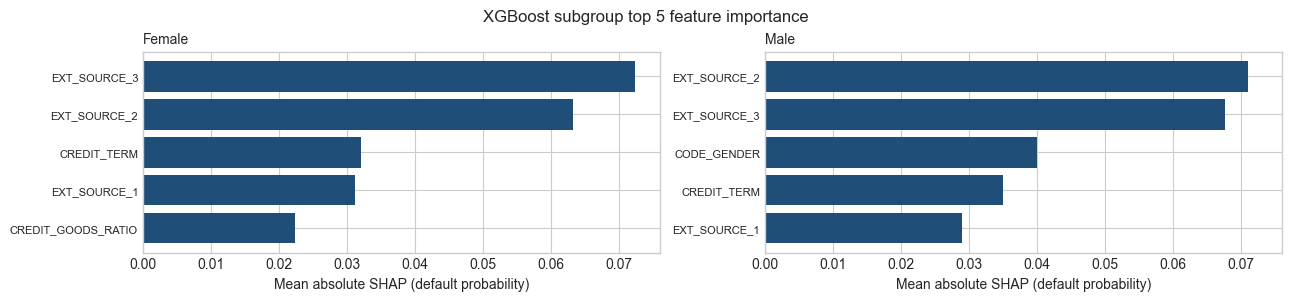

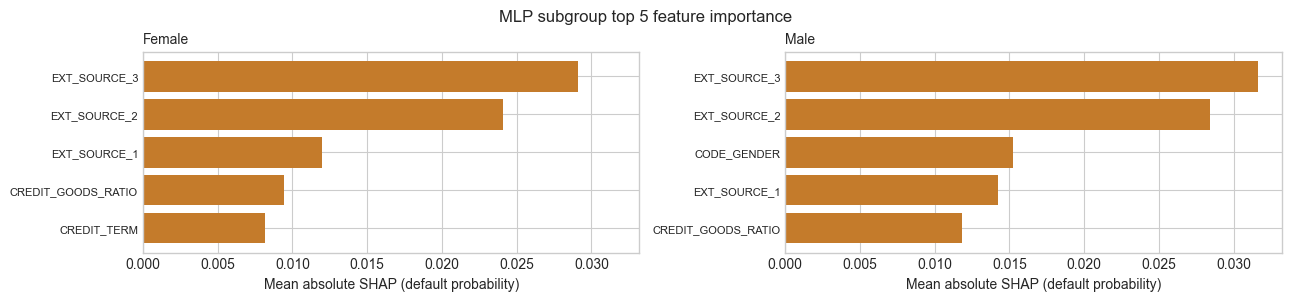

SUBGROUP TOP 5 FEATURE COMPARISON: gender


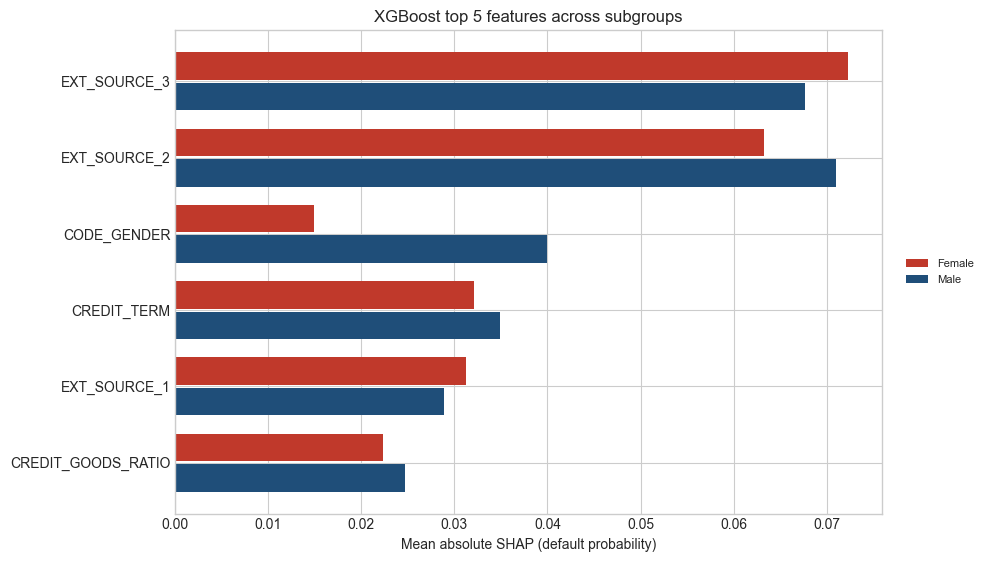

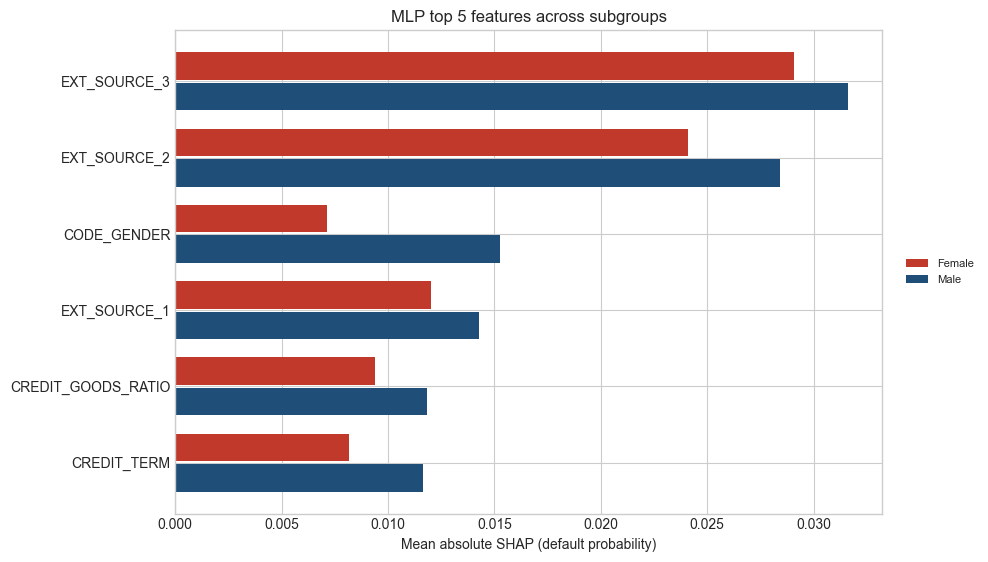

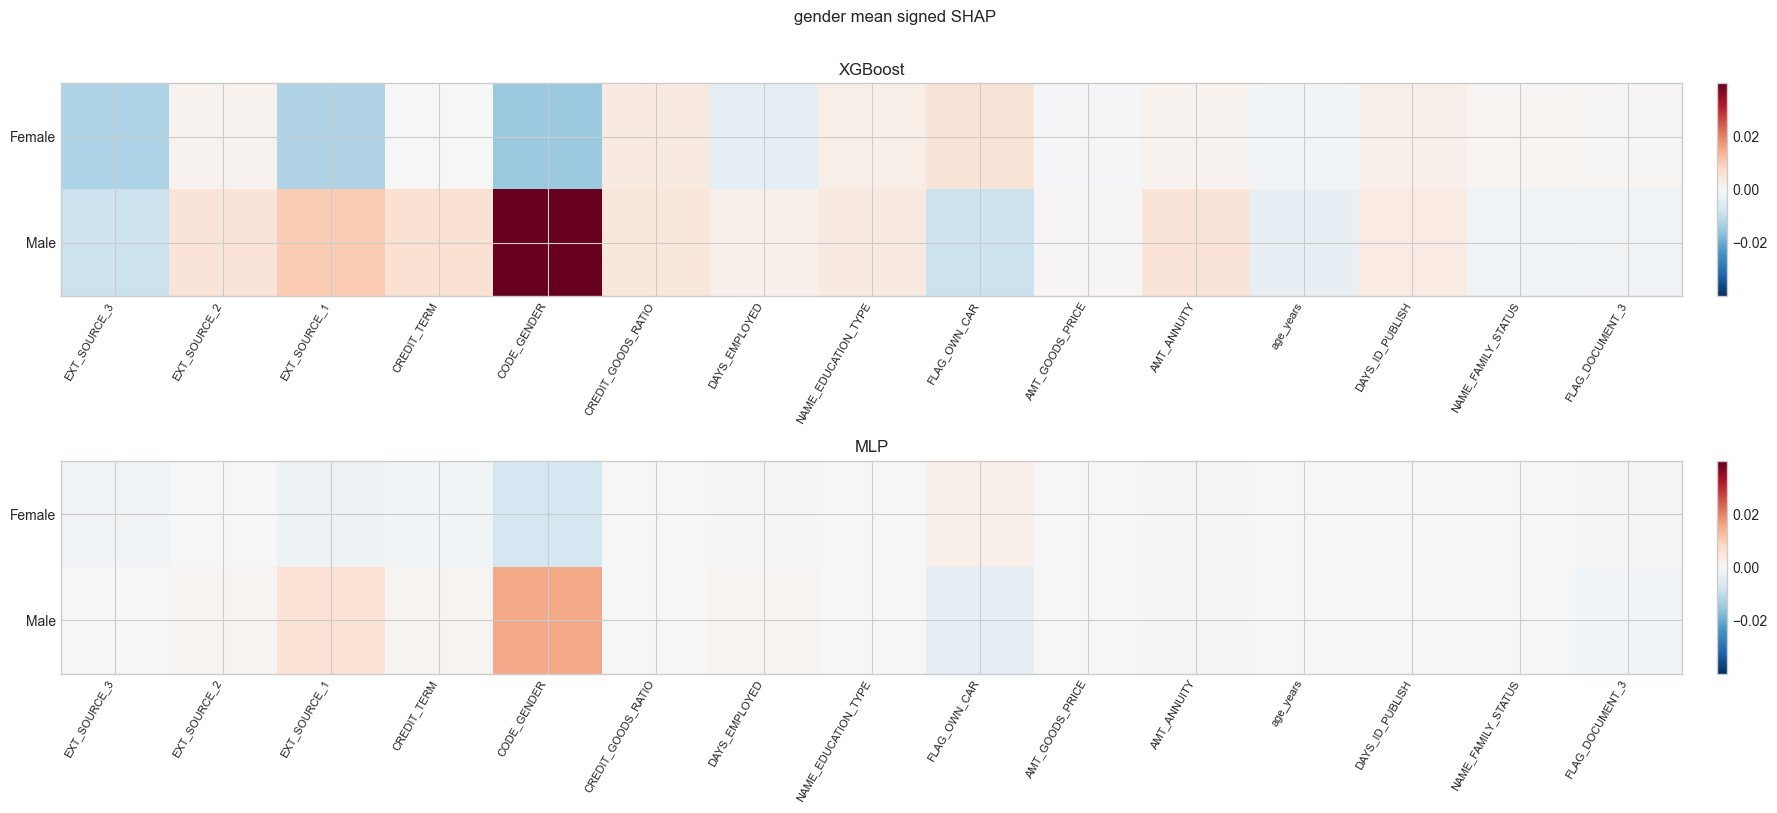

In [230]:
show_subgroup_shap("gender")

SUBGROUP SHAP FEATURE IMPORTANCE: age_band


,model,grouping_variable,subgroup,feature,count,mean_abs_shap,mean_signed_shap,support_flag,subgroup_feature_rank
20,MLP,age_band,<25,EXT_SOURCE_3,1850,0.035613,0.017938,ok,1
21,MLP,age_band,<25,EXT_SOURCE_2,1850,0.034950,0.018119,ok,2
22,MLP,age_band,<25,EXT_SOURCE_1,1850,0.027372,0.022879,ok,3
23,MLP,age_band,<25,EXT_SOURCE_1_MISSING,1850,0.020595,-0.004865,ok,4
24,MLP,age_band,<25,age_years,1850,0.015715,-0.013506,ok,5
25,MLP,age_band,25–34,EXT_SOURCE_3,10763,0.031909,0.005476,ok,1
26,MLP,age_band,25–34,EXT_SOURCE_2,10763,0.028279,0.004581,ok,2
27,MLP,age_band,25–34,EXT_SOURCE_1,10763,0.018876,0.012013,ok,3
28,MLP,age_band,25–34,EXT_SOURCE_1_MISSING,10763,0.014358,-0.003196,ok,4
29,MLP,age_band,25–34,CREDIT_GOODS_RATIO,10763,0.012141,-0.000063,ok,5


SUBGROUP TOP 5 FEATURE IMPORTANCE: age_band


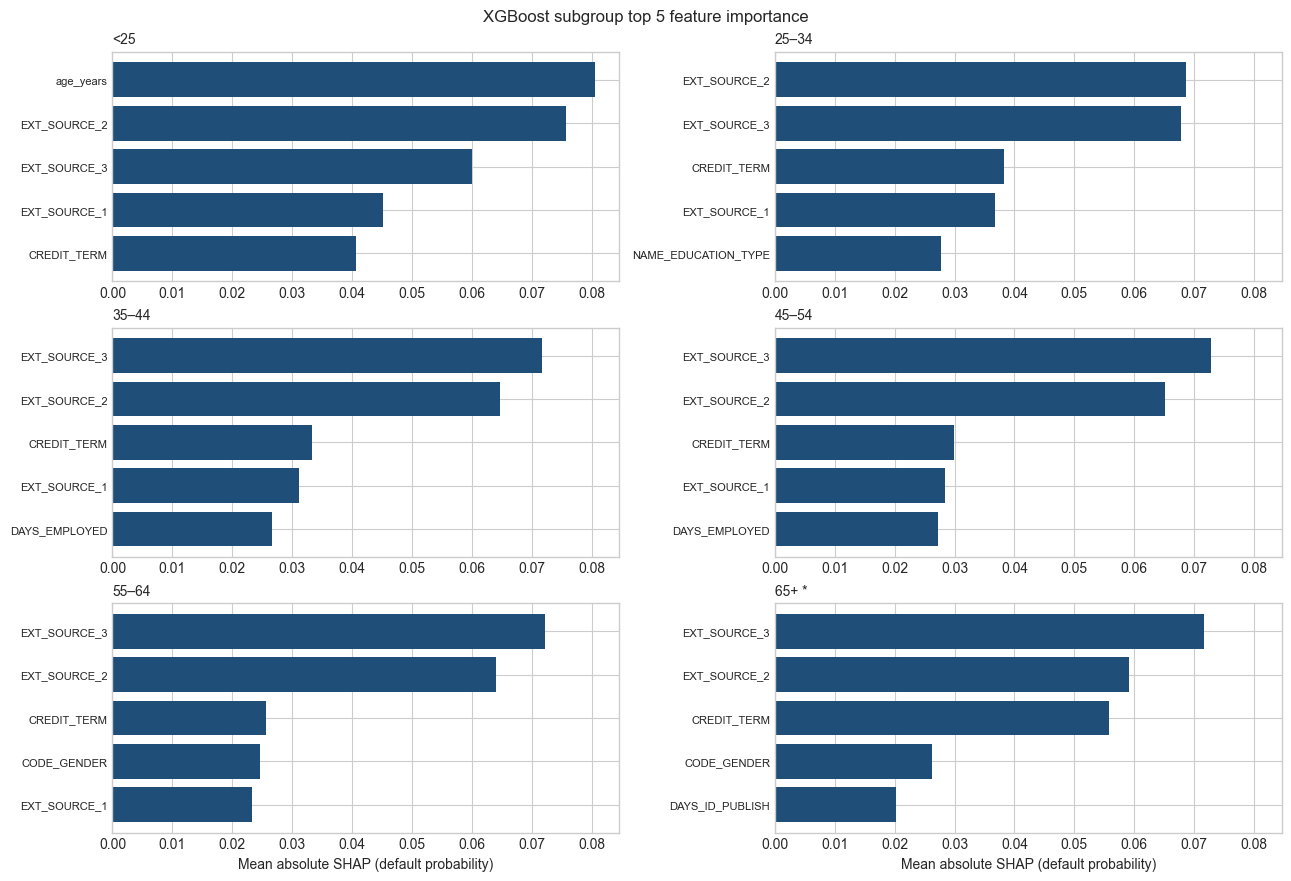

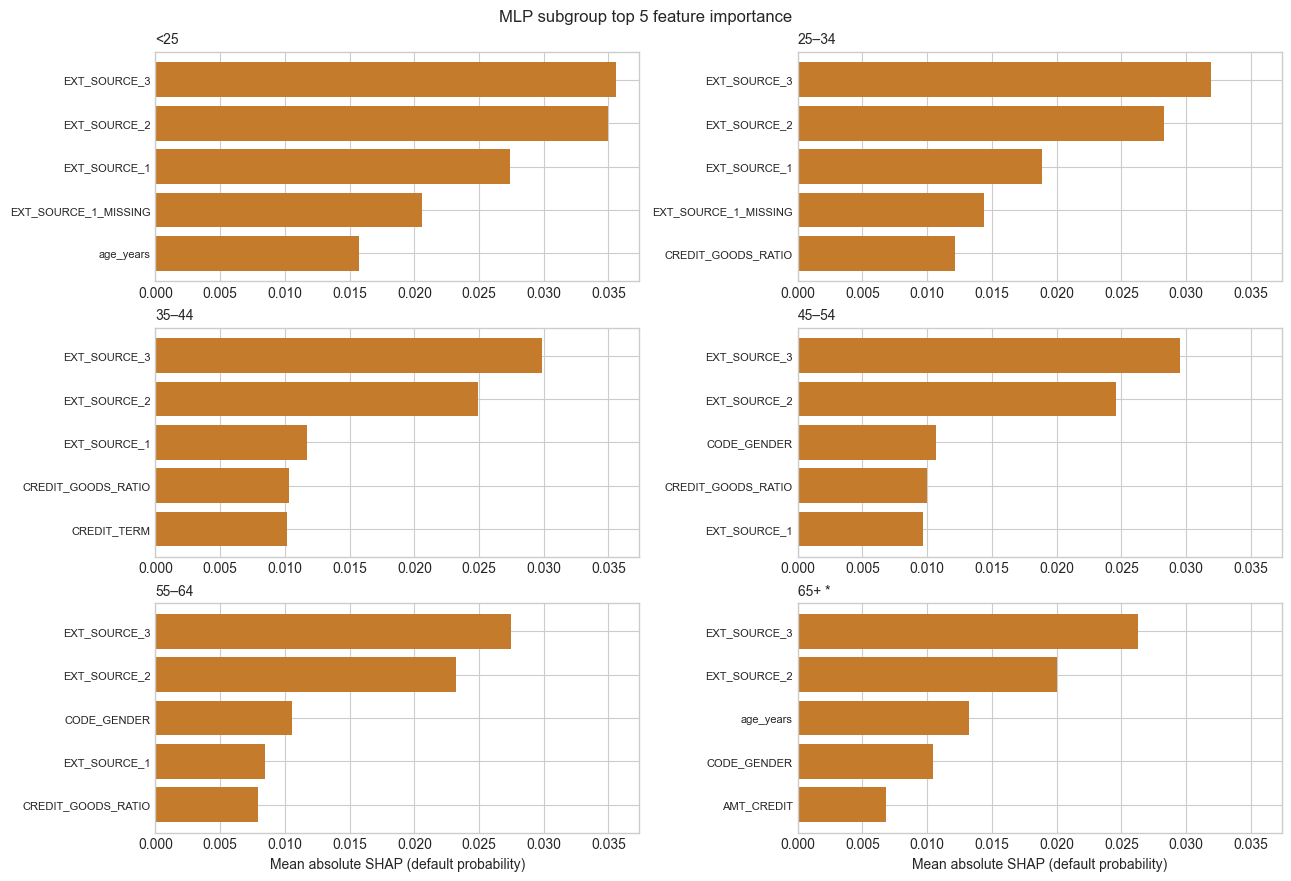

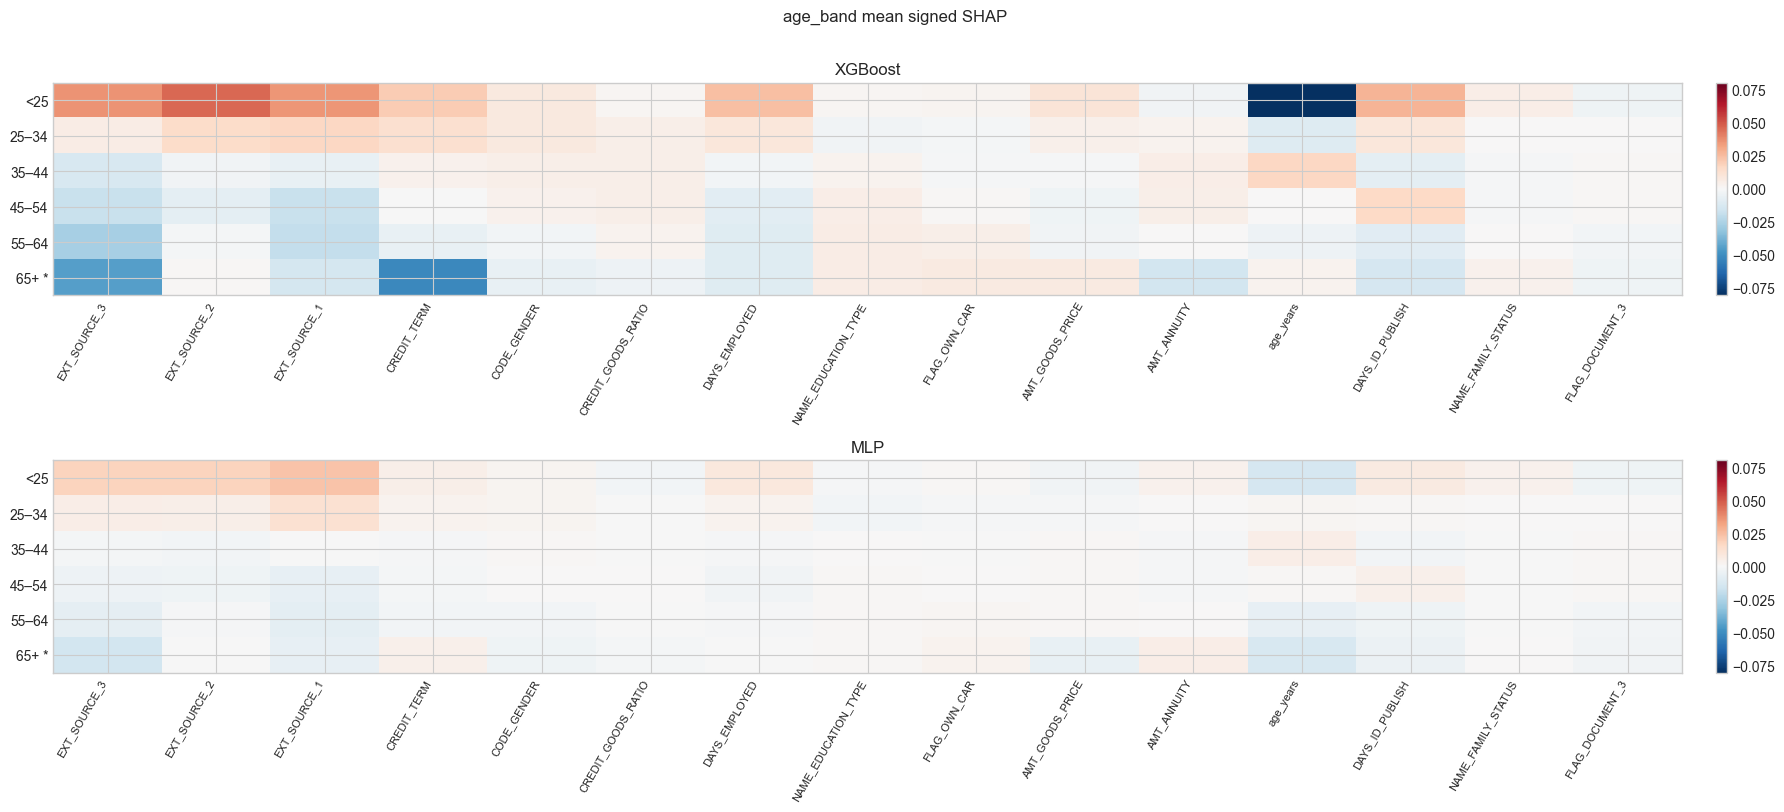

In [231]:
show_subgroup_shap("age_band")

SUBGROUP SHAP FEATURE IMPORTANCE: income_band


,model,grouping_variable,subgroup,feature,count,mean_abs_shap,mean_signed_shap,support_flag,subgroup_feature_rank
80,MLP,income_band,Q1 low,EXT_SOURCE_3,15123,0.029510,-0.005302,ok,1
81,MLP,income_band,Q1 low,EXT_SOURCE_2,15123,0.026183,0.005490,ok,2
82,MLP,income_band,Q1 low,EXT_SOURCE_1,15123,0.012489,0.001108,ok,3
83,MLP,income_band,Q1 low,CREDIT_GOODS_RATIO,15123,0.010587,0.000438,ok,4
84,MLP,income_band,Q1 low,CODE_GENDER,15123,0.009825,-0.002177,ok,5
85,MLP,income_band,Q2,EXT_SOURCE_3,7879,0.030558,-0.000985,ok,1
86,MLP,income_band,Q2,EXT_SOURCE_2,7879,0.025769,0.001645,ok,2
87,MLP,income_band,Q2,EXT_SOURCE_1,7879,0.013217,0.001632,ok,3
88,MLP,income_band,Q2,CREDIT_GOODS_RATIO,7879,0.010556,0.000305,ok,4
89,MLP,income_band,Q2,CODE_GENDER,7879,0.010032,0.000390,ok,5


SUBGROUP TOP 5 FEATURE IMPORTANCE: income_band


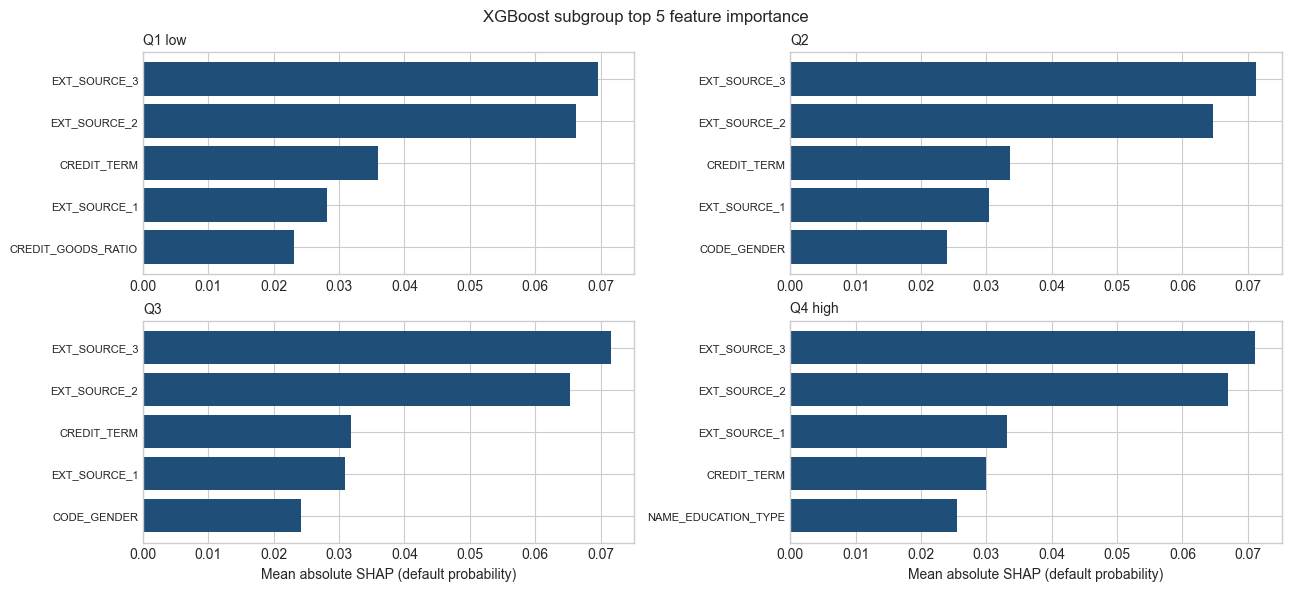

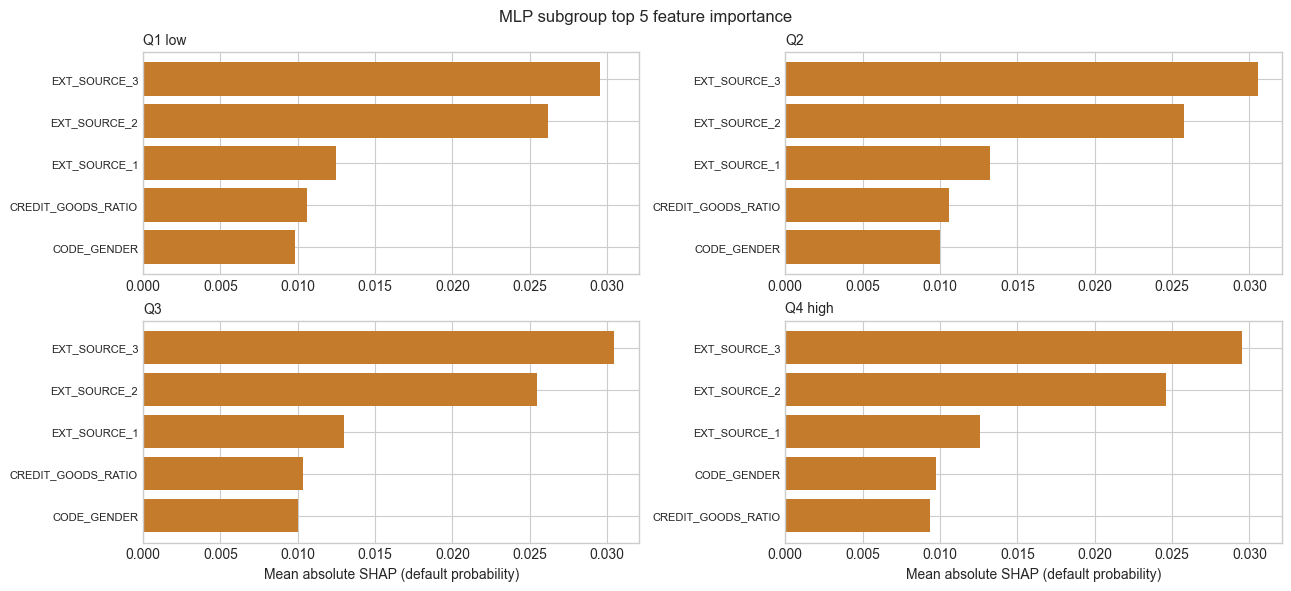

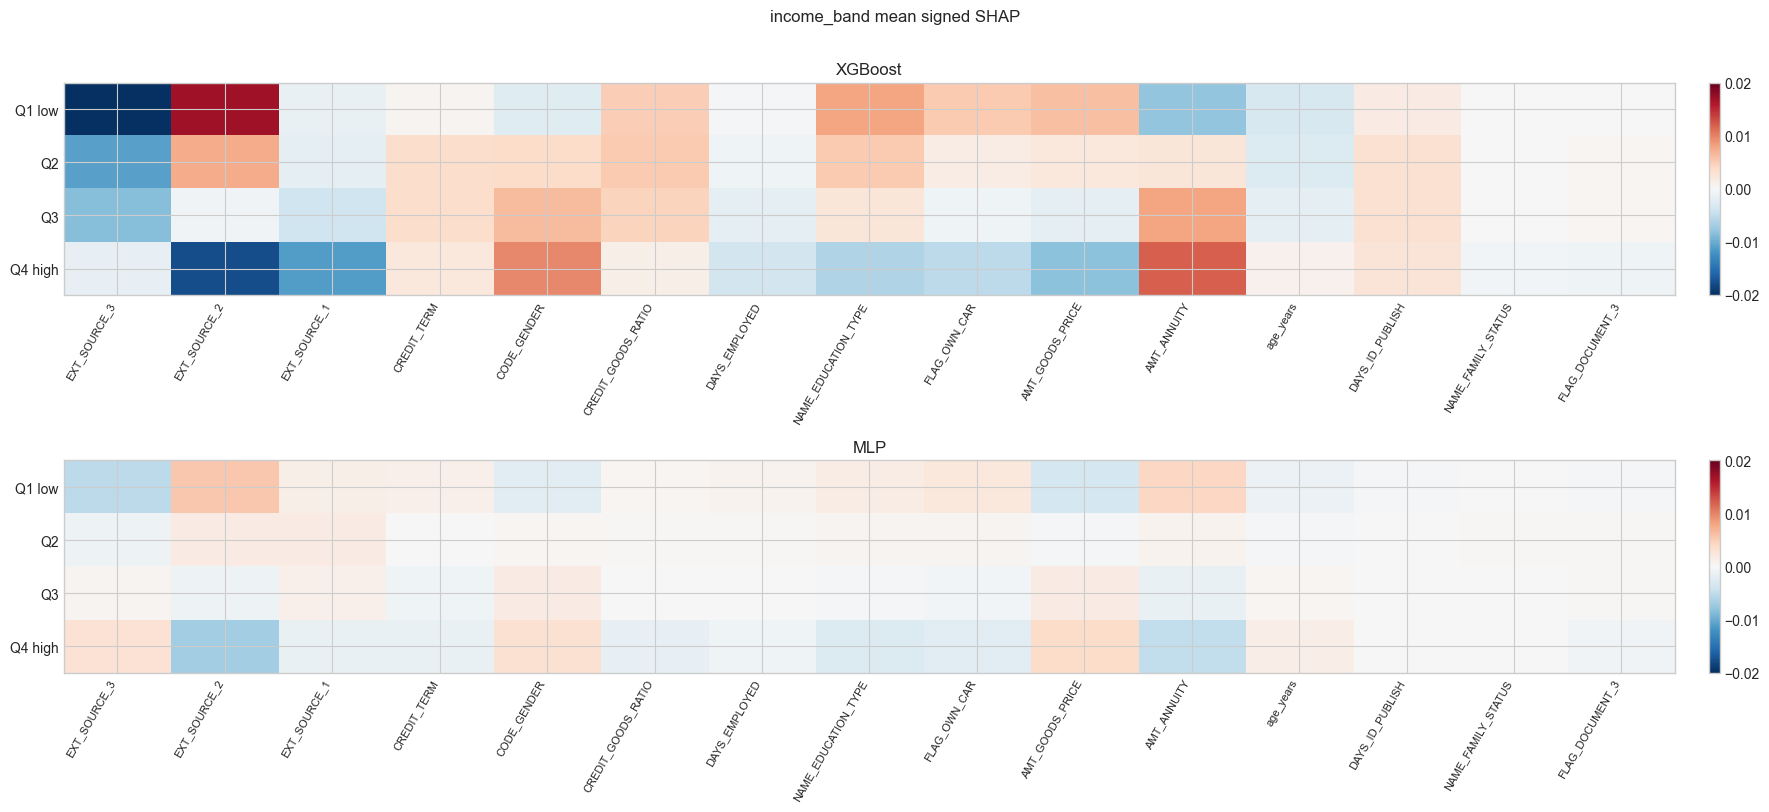

In [232]:
show_subgroup_shap("income_band")

SUBGROUP SHAP FEATURE IMPORTANCE: gender × age_band


,model,grouping_variable,subgroup,feature,count,mean_abs_shap,mean_signed_shap,support_flag,subgroup_feature_rank
120,MLP,gender × age_band,Female | <25,EXT_SOURCE_3,1022,0.034197,0.015502,ok,1
121,MLP,gender × age_band,Female | <25,EXT_SOURCE_2,1022,0.033814,0.016663,ok,2
122,MLP,gender × age_band,Female | <25,EXT_SOURCE_1,1022,0.026231,0.021210,ok,3
123,MLP,gender × age_band,Female | <25,EXT_SOURCE_1_MISSING,1022,0.018912,-0.006735,ok,4
124,MLP,gender × age_band,Female | <25,CREDIT_GOODS_RATIO,1022,0.014226,-0.002195,ok,5
125,MLP,gender × age_band,Female | 25–34,EXT_SOURCE_3,6287,0.031572,0.006509,ok,1
126,MLP,gender × age_band,Female | 25–34,EXT_SOURCE_2,6287,0.027114,0.003609,ok,2
127,MLP,gender × age_band,Female | 25–34,EXT_SOURCE_1,6287,0.017351,0.009052,ok,3
128,MLP,gender × age_band,Female | 25–34,EXT_SOURCE_1_MISSING,6287,0.012671,-0.004246,ok,4
129,MLP,gender × age_band,Female | 25–34,CREDIT_GOODS_RATIO,6287,0.011625,0.000011,ok,5


SUBGROUP TOP 5 FEATURE IMPORTANCE: gender × age_band


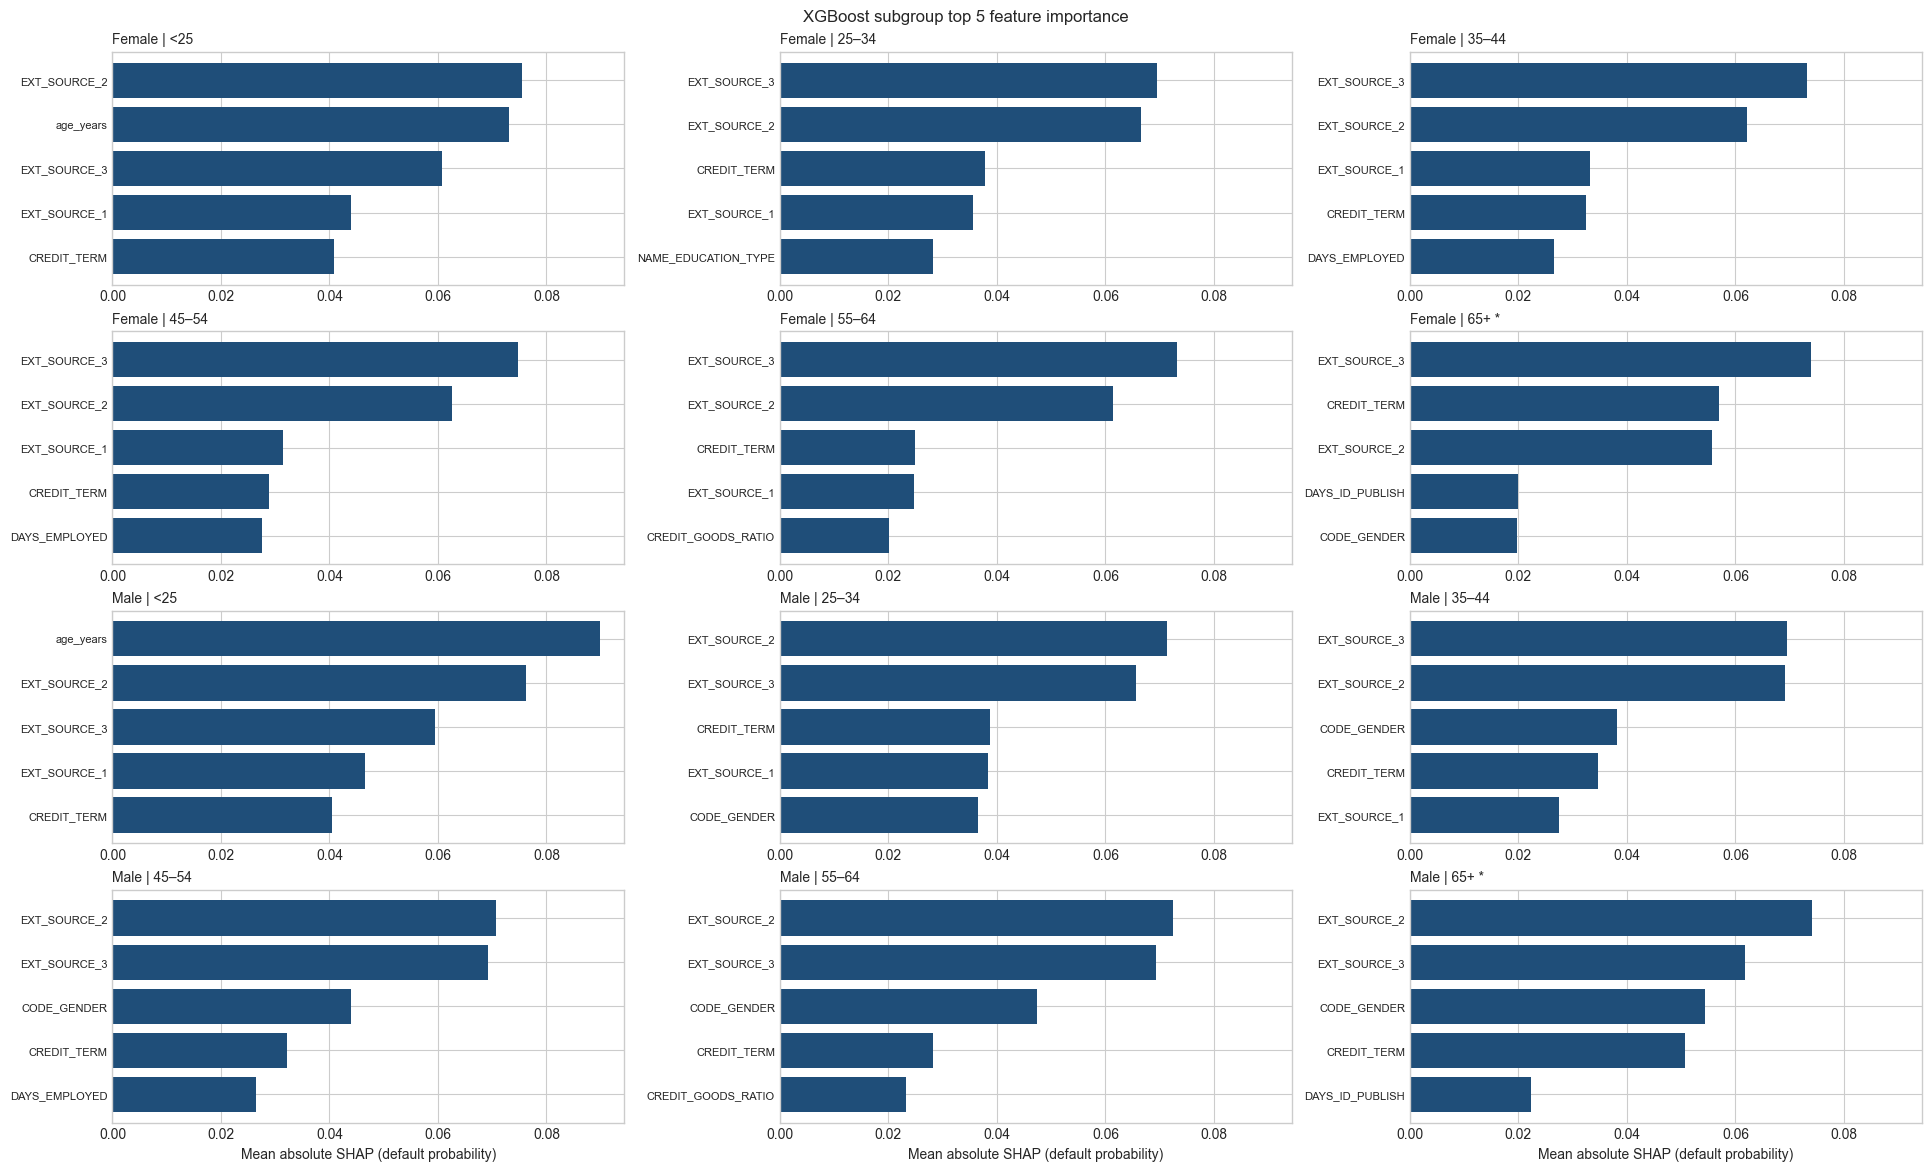

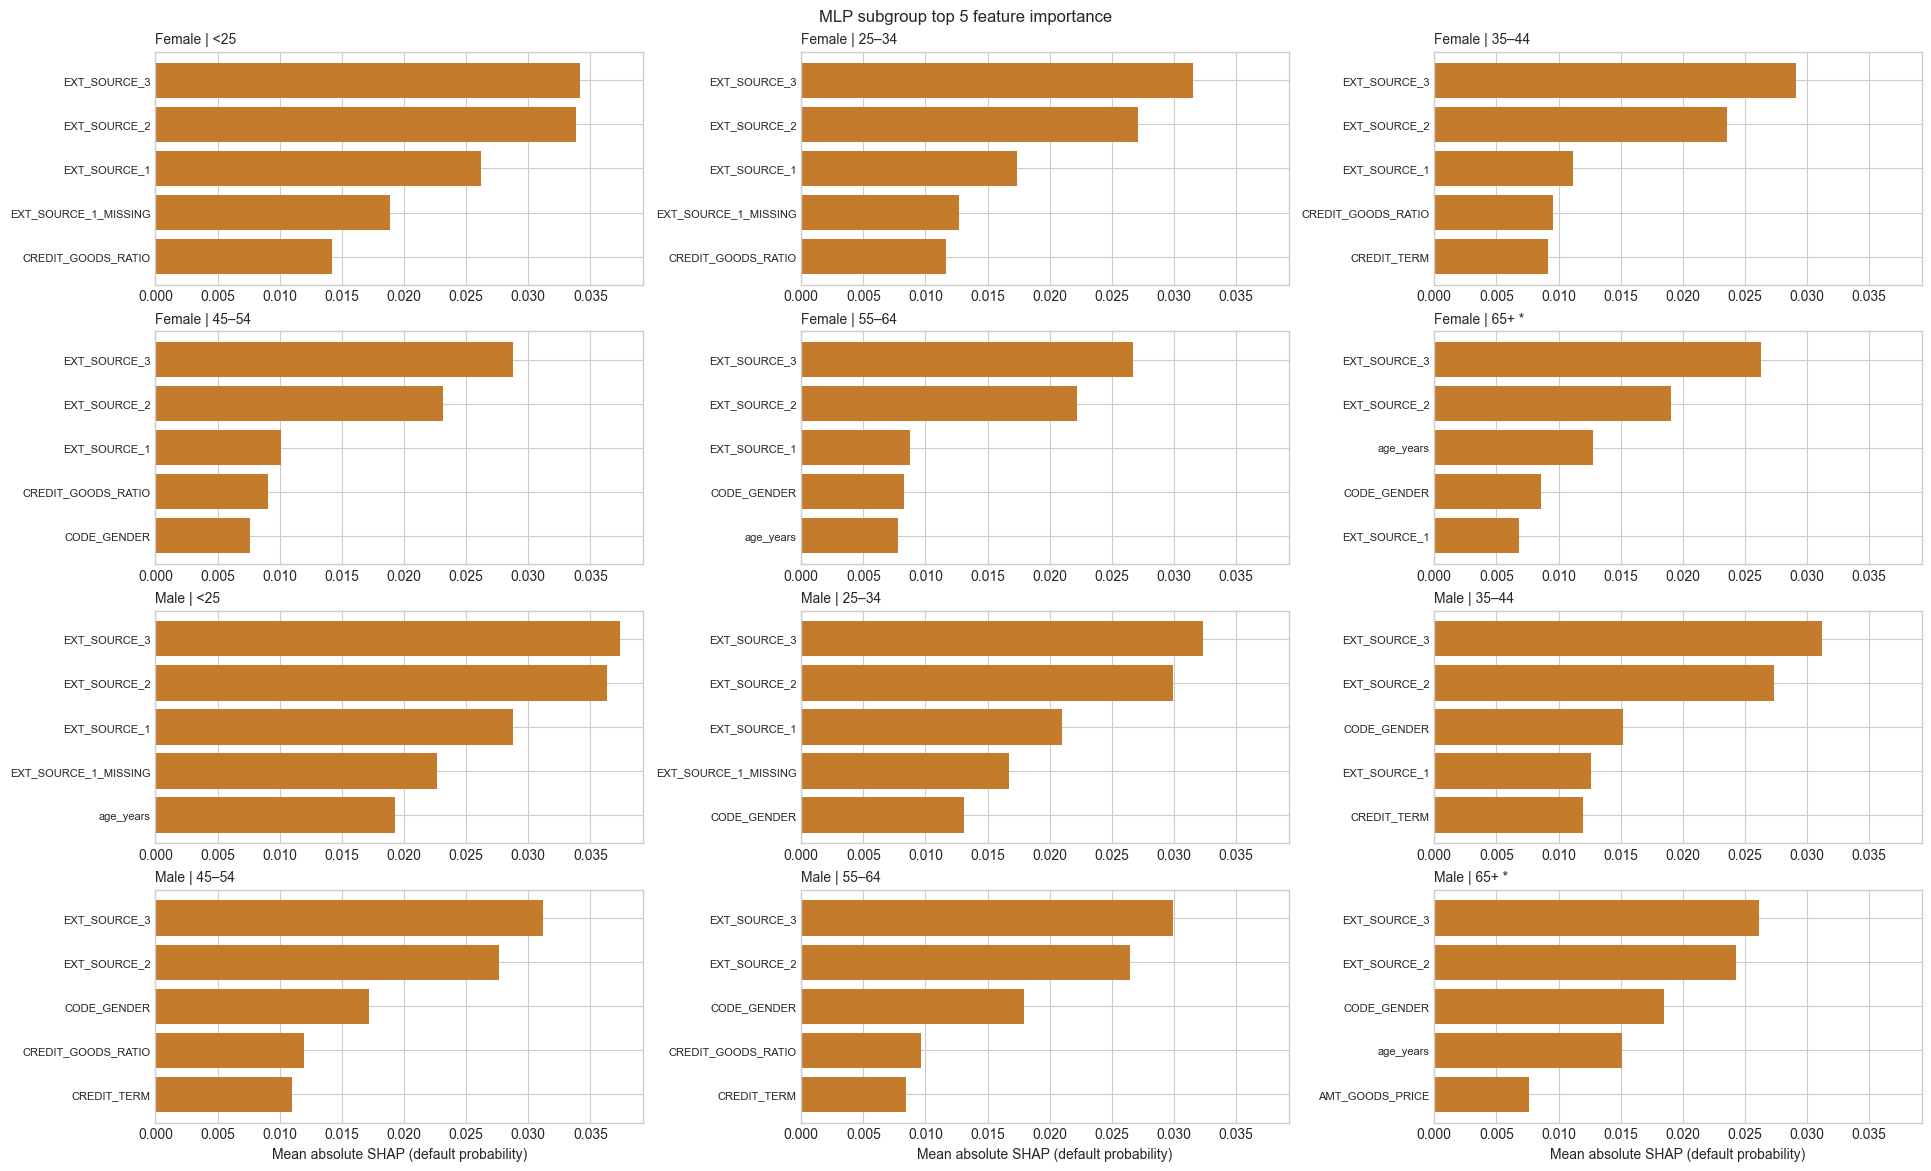

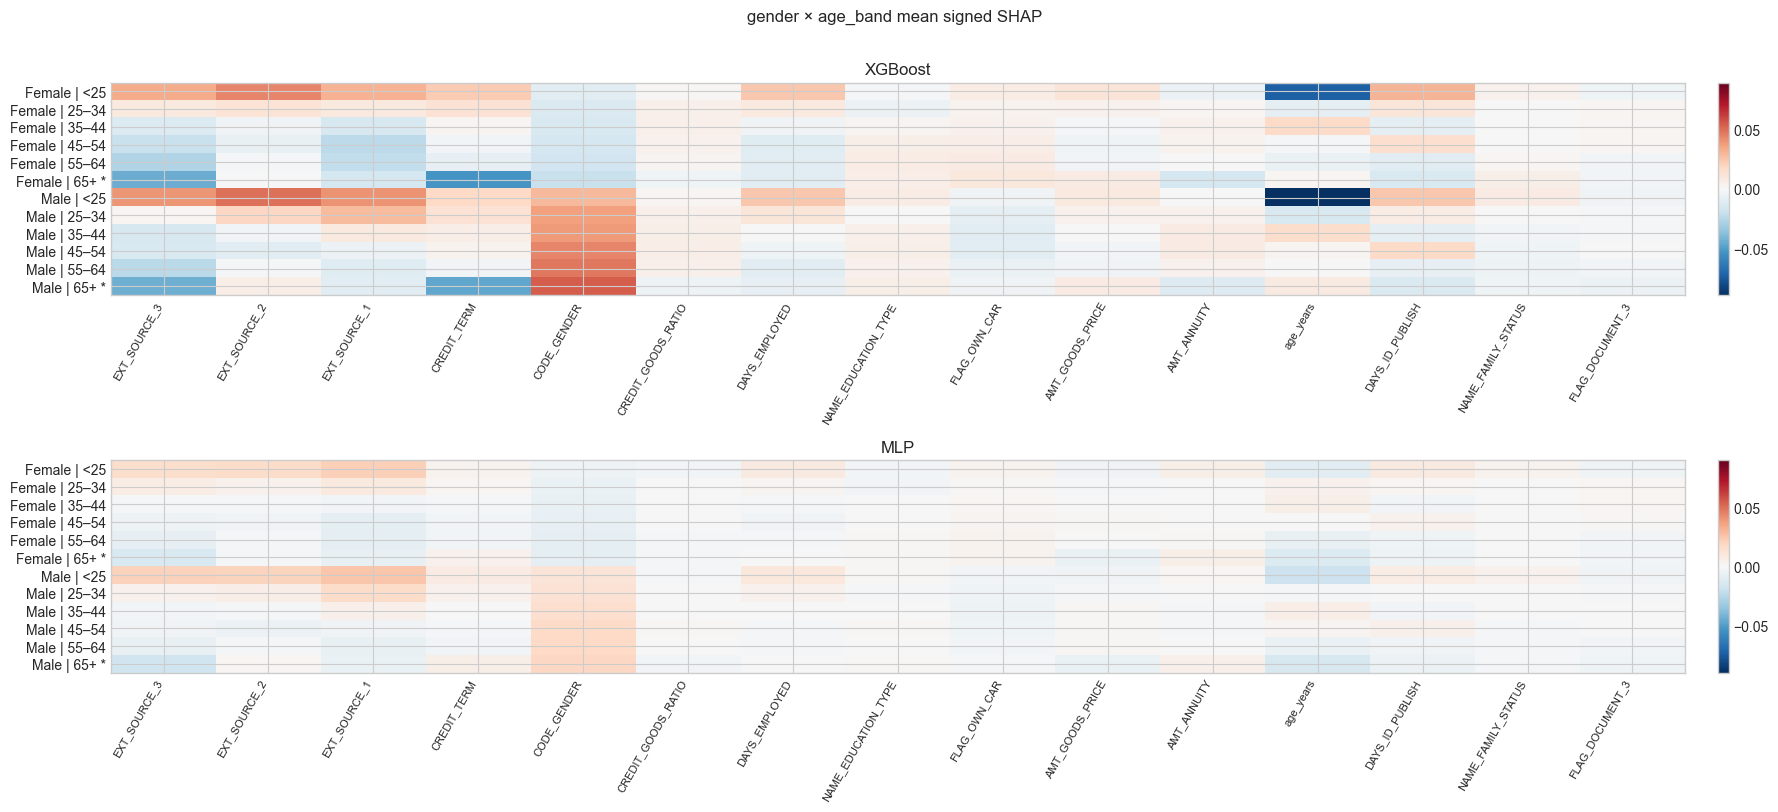

In [233]:
show_subgroup_shap("gender × age_band")

SUBGROUP SHAP FEATURE IMPORTANCE: gender × income_band


,model,grouping_variable,subgroup,feature,count,mean_abs_shap,mean_signed_shap,support_flag,subgroup_feature_rank
240,MLP,gender × income_band,Female | Q1 low,EXT_SOURCE_3,11795,0.029010,-0.004910,ok,1
241,MLP,gender × income_band,Female | Q1 low,EXT_SOURCE_2,11795,0.024783,0.004319,ok,2
242,MLP,gender × income_band,Female | Q1 low,EXT_SOURCE_1,11795,0.011874,-0.000486,ok,3
243,MLP,gender × income_band,Female | Q1 low,CREDIT_GOODS_RATIO,11795,0.009932,0.000162,ok,4
244,MLP,gender × income_band,Female | Q1 low,CREDIT_TERM,11795,0.008350,0.000392,ok,5
245,MLP,gender × income_band,Female | Q2,EXT_SOURCE_3,5264,0.029580,-0.001162,ok,1
246,MLP,gender × income_band,Female | Q2,EXT_SOURCE_2,5264,0.024438,0.000747,ok,2
247,MLP,gender × income_band,Female | Q2,EXT_SOURCE_1,5264,0.012112,-0.001270,ok,3
248,MLP,gender × income_band,Female | Q2,CREDIT_GOODS_RATIO,5264,0.009661,0.000054,ok,4
249,MLP,gender × income_band,Female | Q2,CREDIT_TERM,5264,0.008450,-0.001106,ok,5


SUBGROUP TOP 5 FEATURE IMPORTANCE: gender × income_band


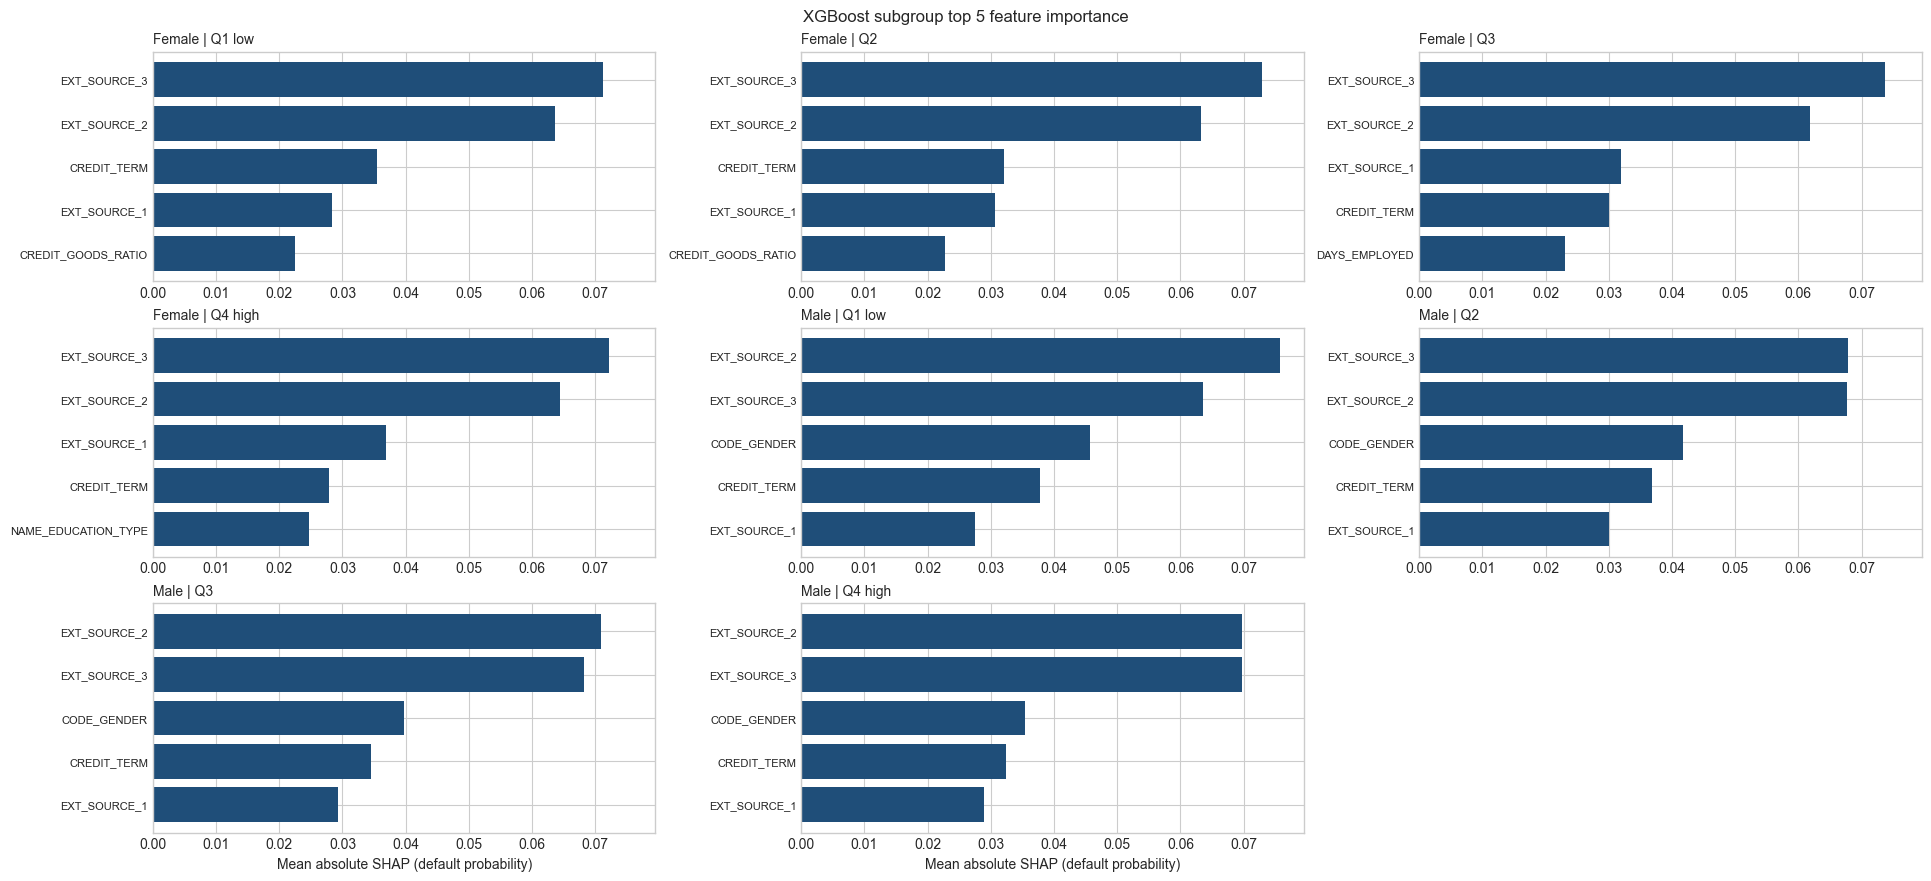

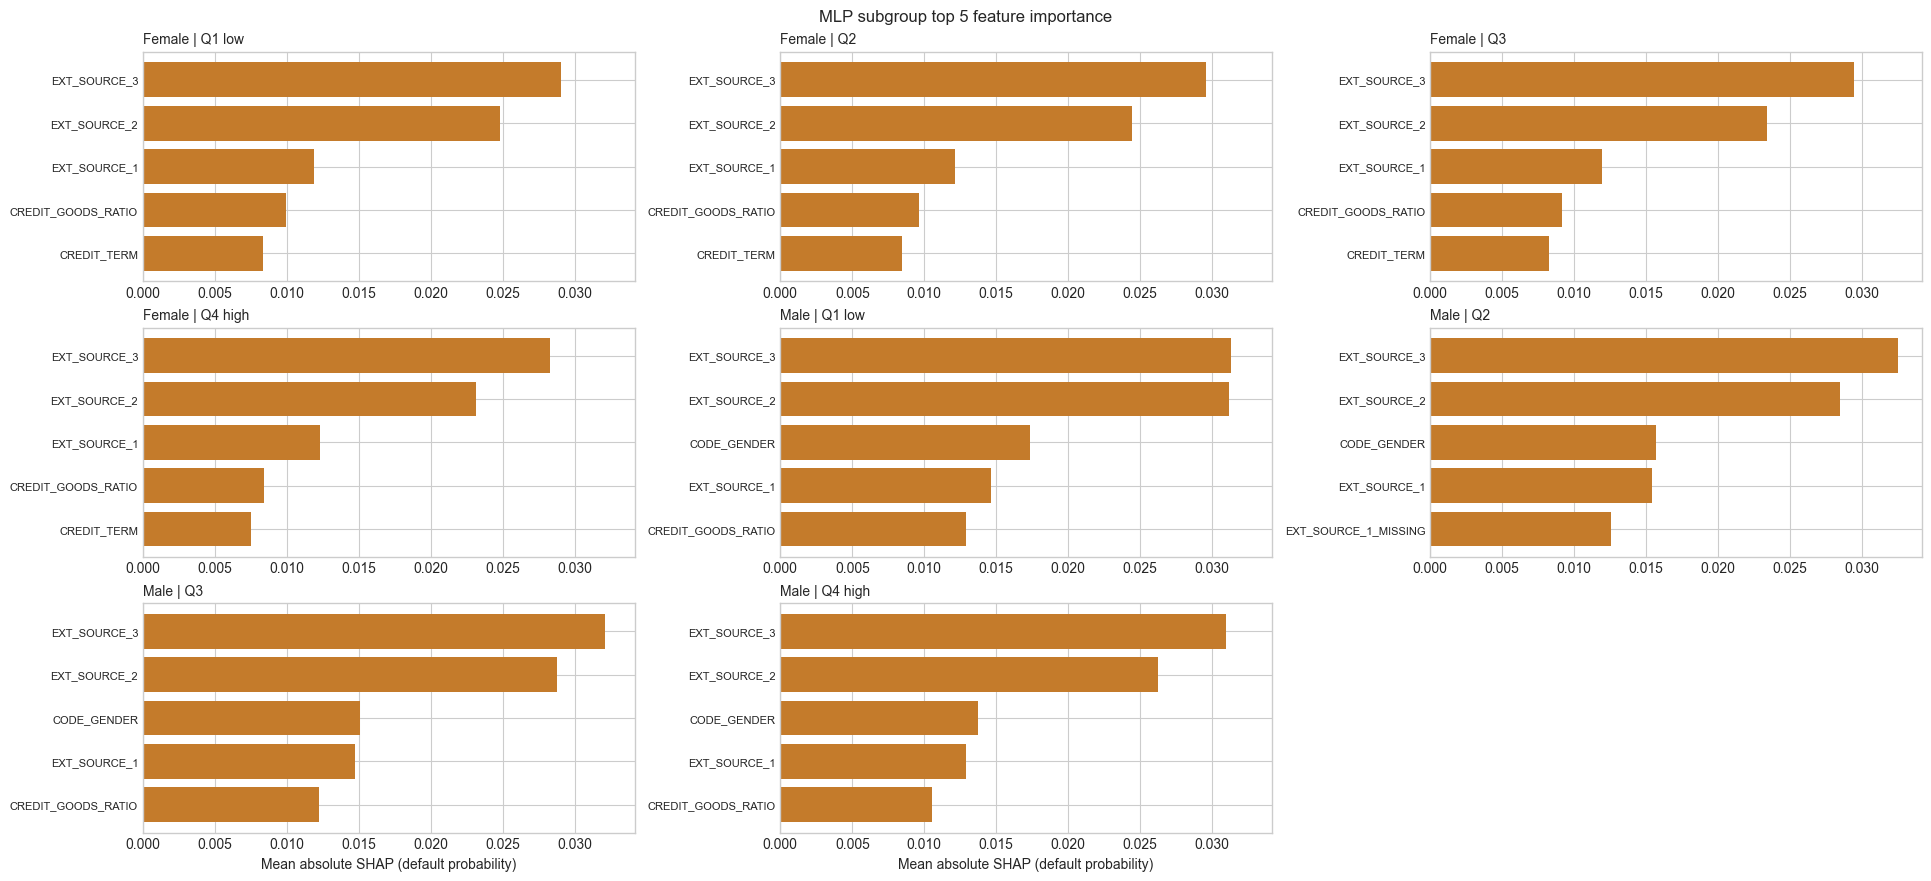

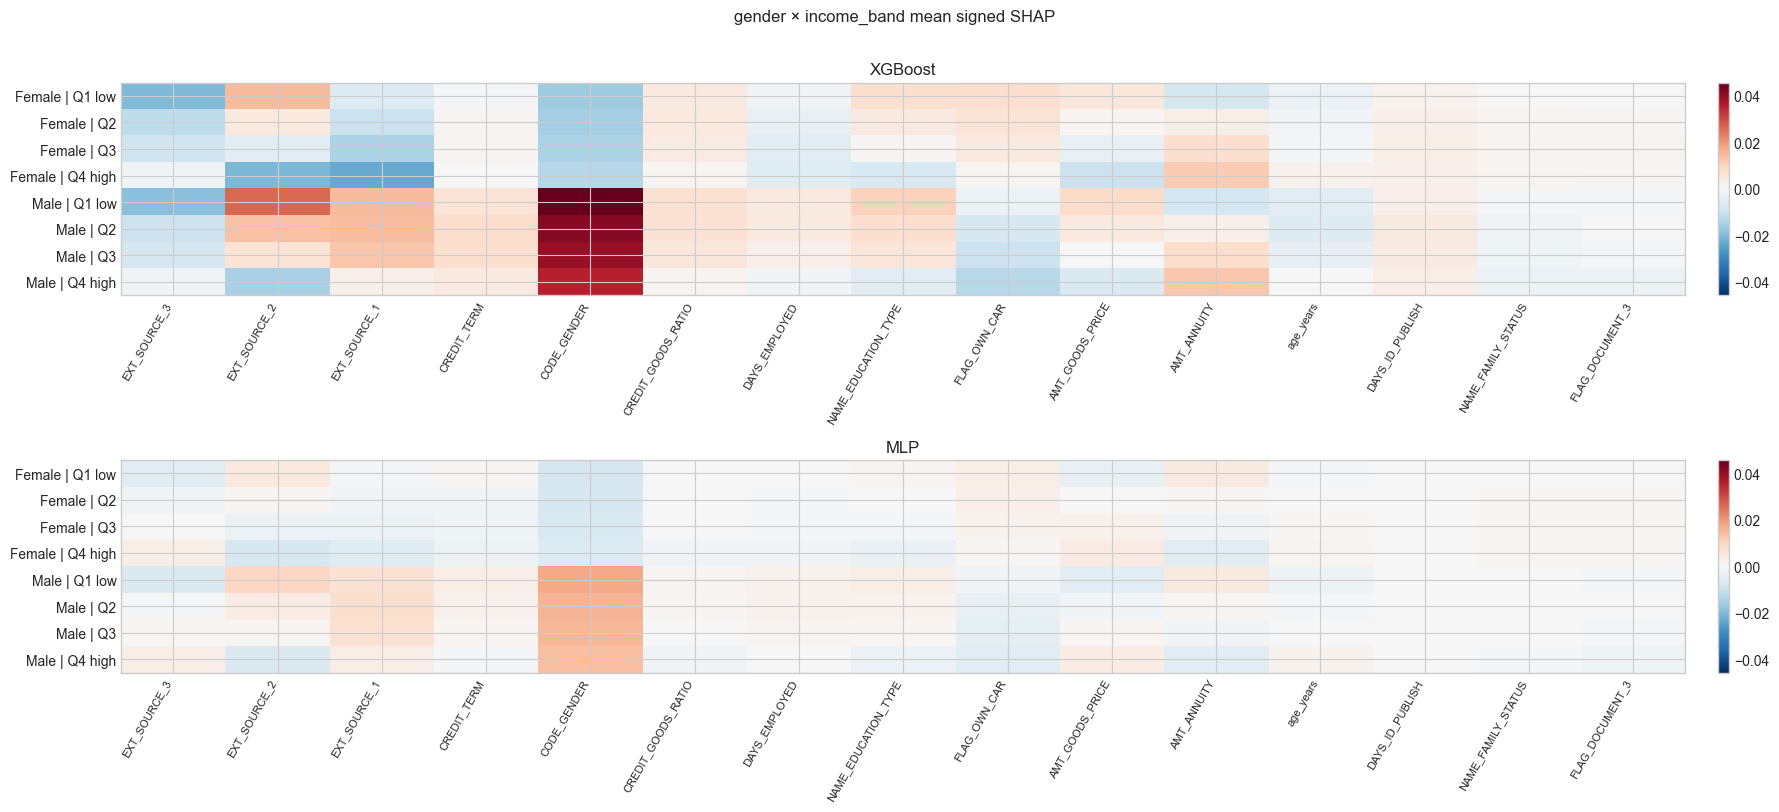

In [234]:
show_subgroup_shap("gender × income_band")

In [235]:
DEMOGRAPHIC_FEATURES = {
    "gender": "CODE_GENDER",
    "age_band": "age_years",
    "income_band": "AMT_INCOME_TOTAL",
}
DEMOGRAPHIC_CATEGORY_ORDER = {
    "gender": ["Female", "Male"],
    "age_band": ["<25", "25–34", "35–44", "45–54", "55–64", "65+"],
    "income_band": ["Q1 low", "Q2", "Q3", "Q4 high"],
}

demographic_rows = []
for grouping, feature in DEMOGRAPHIC_FEATURES.items():
    part = subgroup_shap[
        subgroup_shap["grouping_variable"].eq(grouping) & subgroup_shap["feature"].eq(feature)
    ].copy()
    if set(part["subgroup"]) != set(DEMOGRAPHIC_CATEGORY_ORDER[grouping]) or part["model"].nunique() != 2:
        raise AssertionError(f"Demographic SHAP rows are incomplete for {grouping}.")
    part["_category_order"] = part["subgroup"].map({label: index for index, label in enumerate(DEMOGRAPHIC_CATEGORY_ORDER[grouping])})
    part["_model_order"] = part["model"].map({"MLP": 0, "XGBoost": 1})
    demographic_rows.append(part.sort_values(["_category_order", "_model_order"]))
demographic_attribution = pd.concat(demographic_rows, ignore_index=True).drop(columns=["_category_order", "_model_order"])
demographic_attribution = demographic_attribution[[
    "model", "grouping_variable", "subgroup", "feature", "count", "mean_abs_shap", "mean_signed_shap", "support_flag",
]]
demographic_attribution.to_csv(SHAP_DIR / "demographic_feature_attribution.csv", index=False)
demographic_display = demographic_attribution.copy()
for column in ["mean_abs_shap", "mean_signed_shap"]:
    demographic_display[column] = demographic_display[column].map(lambda value: f"{value:.6f}")

def demographic_bars(grouping):
    feature = DEMOGRAPHIC_FEATURES[grouping]
    categories = DEMOGRAPHIC_CATEGORY_ORDER[grouping]
    part = demographic_attribution[demographic_attribution["grouping_variable"].eq(grouping)]
    labels = []
    for category in categories:
        flag = part.loc[part["subgroup"].eq(category), "support_flag"].iloc[0]
        labels.append(category if flag == "ok" else f"{category} *")
    positions = np.arange(len(categories))
    figure, axis = plt.subplots(figsize=(8, 0.48 * len(categories) + 1.6))
    bar_height = 0.36
    for offset, model_name, color in ((-bar_height / 2, "MLP", "#c47b2b"), (bar_height / 2, "XGBoost", "#1f4e79")):
        values = [
            float(part.loc[part["model"].eq(model_name) & part["subgroup"].eq(category), "mean_signed_shap"].iloc[0])
            for category in categories
        ]
        axis.barh(positions + offset, values, height=bar_height, color=color, label=model_name)
    axis.axvline(0, color="0.45", lw=0.8)
    axis.set_yticks(positions, labels)
    axis.invert_yaxis()
    axis.set_xlabel("Mean signed SHAP (default probability)")
    axis.set_title(f"{grouping}: {feature}")
    axis.legend(frameon=False, loc="best")
    figure.tight_layout()
    safe_name = grouping.replace(" ", "_")
    figure.savefig(FIGURE_DIR / f"shap_demographic_{safe_name}.png", dpi=160, bbox_inches="tight")
    display(figure)
    plt.close(figure)

def show_demographic_attribution(grouping):
    part = demographic_display[demographic_display["grouping_variable"].eq(grouping)]
    print(f"DEMOGRAPHIC FEATURE ATTRIBUTION BY CATEGORY: {grouping}")
    display(part)
    demographic_bars(grouping)


DEMOGRAPHIC FEATURE ATTRIBUTION BY CATEGORY: gender


,model,grouping_variable,subgroup,feature,count,mean_abs_shap,mean_signed_shap,support_flag
0,MLP,gender,Female,CODE_GENDER,30410,0.007139,-0.007139,ok
1,XGBoost,gender,Female,CODE_GENDER,30410,0.014936,-0.014936,ok
2,MLP,gender,Male,CODE_GENDER,15716,0.015245,0.015245,ok
3,XGBoost,gender,Male,CODE_GENDER,15716,0.039998,0.039997,ok


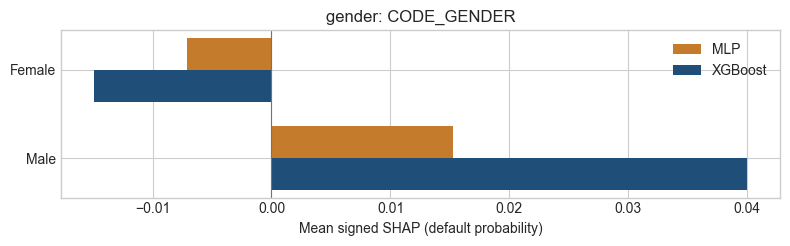

In [236]:
show_demographic_attribution("gender")

DEMOGRAPHIC FEATURE ATTRIBUTION BY CATEGORY: age_band


,model,grouping_variable,subgroup,feature,count,mean_abs_shap,mean_signed_shap,support_flag
4,MLP,age_band,<25,age_years,1850,0.015715,-0.013506,ok
5,XGBoost,age_band,<25,age_years,1850,0.080600,-0.080600,ok
6,MLP,age_band,25–34,age_years,10763,0.006983,0.001599,ok
7,XGBoost,age_band,25–34,age_years,10763,0.020787,-0.010317,ok
8,MLP,age_band,35–44,age_years,12731,0.005575,0.005523,ok
9,XGBoost,age_band,35–44,age_years,12731,0.016537,0.016509,ok
10,MLP,age_band,45–54,age_years,10579,0.003587,0.001017,ok
11,XGBoost,age_band,45–54,age_years,10579,0.006607,0.000235,ok
12,MLP,age_band,55–64,age_years,8995,0.007810,-0.006547,ok
13,XGBoost,age_band,55–64,age_years,8995,0.012103,-0.004327,ok


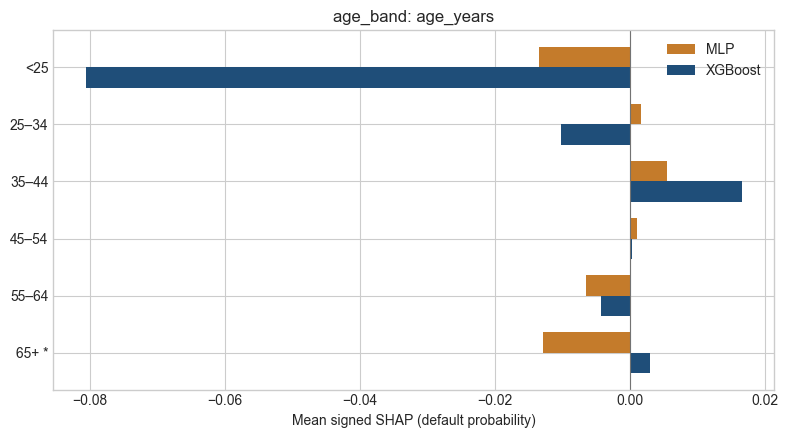

In [237]:
show_demographic_attribution("age_band")

DEMOGRAPHIC FEATURE ATTRIBUTION BY CATEGORY: income_band


,model,grouping_variable,subgroup,feature,count,mean_abs_shap,mean_signed_shap,support_flag
16,MLP,income_band,Q1 low,AMT_INCOME_TOTAL,15123,0.003413,-0.003173,ok
17,XGBoost,income_band,Q1 low,AMT_INCOME_TOTAL,15123,0.003591,-0.001935,ok
18,MLP,income_band,Q2,AMT_INCOME_TOTAL,7879,0.000626,-0.000352,ok
19,XGBoost,income_band,Q2,AMT_INCOME_TOTAL,7879,0.002826,-0.002433,ok
20,MLP,income_band,Q3,AMT_INCOME_TOTAL,12463,0.001541,0.001457,ok
21,XGBoost,income_band,Q3,AMT_INCOME_TOTAL,12463,0.002604,0.002374,ok
22,MLP,income_band,Q4 high,AMT_INCOME_TOTAL,10661,0.004427,0.004139,ok
23,XGBoost,income_band,Q4 high,AMT_INCOME_TOTAL,10661,0.003733,0.001655,ok


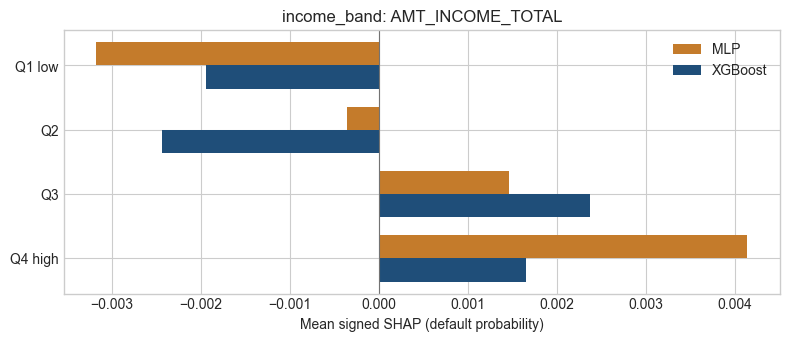

In [238]:
show_demographic_attribution("income_band")

### 9.3 Group Prediction Disparity Decomposition

The contrasts are prespecified, not chosen after comparing SHAP results. They are MALE vs FEMALE, age `<25` vs `55–64`, income `Q1 (LOWEST)` vs `Q4 (HIGHEST)`, `FEMALE Q1` vs `MALE Q1`, and `FEMALE Q4` vs `MALE Q4`. The same pairs are used for both models. A positive feature contribution means that feature's average attribution is higher for the first group, in the direction of a higher predicted default probability.


In [239]:
def group_mask(grouping, subgroup):
    return explained_test[grouping].astype(str).eq(subgroup).to_numpy()


decomposition_rows = []
summaries = []
for grouping, subgroup_a, subgroup_b in CONTRASTS:
    mask_a = group_mask(grouping, subgroup_a)
    mask_b = group_mask(grouping, subgroup_b)
    if mask_a.sum() == 0 or mask_b.sum() == 0:
        raise AssertionError(f"Contrast {subgroup_a} versus {subgroup_b} is absent from the SHAP sample.")
    for model_name in ["XGBoost", "MLP"]:
        matrix = family_values[model_name]
        if model_name == "XGBoost":
            prediction = xgb_model.predict_proba(X_test_matrix[sample_index])[:, 1]
        else:
            prediction = mlp_model.predict(X_test_matrix[sample_index], verbose=0).ravel()
        mean_a = weighted_mean(prediction[mask_a], weights[mask_a])
        mean_b = weighted_mean(prediction[mask_b], weights[mask_b])
        difference = mean_a - mean_b
        pieces = []
        for index, feature in enumerate(family_names):
            shap_a = weighted_mean(matrix[mask_a, index], weights[mask_a])
            shap_b = weighted_mean(matrix[mask_b, index], weights[mask_b])
            pieces.append((feature, shap_a, shap_b, shap_a - shap_b))
        residual = difference - sum(piece[3] for piece in pieces)
        if abs(residual) > 0.02:
            print(f"Large decomposition residual for {model_name} {grouping}: {residual:.4f}")
        summaries.append({
            "model": model_name, "grouping_variable": grouping,
            "subgroup_a": subgroup_a, "subgroup_b": subgroup_b,
            "mean_prediction_a": mean_a, "mean_prediction_b": mean_b,
            "prediction_difference": difference, "decomposition_residual": residual,
            "observation_count_a": int(mask_a.sum()), "observation_count_b": int(mask_b.sum()),
        })
        for feature, shap_a, shap_b, shap_difference in pieces:
            decomposition_rows.append({
                "model": model_name, "grouping_variable": grouping,
                "subgroup_a": subgroup_a, "subgroup_b": subgroup_b, "feature": feature,
                "mean_shap_a": shap_a, "mean_shap_b": shap_b, "shap_difference": shap_difference,
            })

decomposition = pd.DataFrame(decomposition_rows)
decomposition["abs_difference"] = decomposition["shap_difference"].abs()
decomposition["difference_rank"] = decomposition.groupby(
    ["model", "grouping_variable", "subgroup_a", "subgroup_b"]
)["abs_difference"].rank(ascending=False, method="min").astype(int)
decomposition = decomposition.drop(columns="abs_difference").sort_values(
    ["grouping_variable", "model", "difference_rank"]
).reset_index(drop=True)
decomposition.to_csv(SHAP_DIR / "group_prediction_disparity_decomposition.csv", index=False)
contrast_summary = pd.DataFrame(summaries)
contrast_table = contrast_summary.drop(columns="decomposition_residual")
contrast_table.to_csv(SHAP_DIR / "group_prediction_contrasts.csv", index=False)
contrast_display = contrast_table.copy()
for column in ["mean_prediction_a", "mean_prediction_b", "prediction_difference"]:
    contrast_display[column] = contrast_display[column].map(lambda value: f"{value:.6f}")

top_decomposition = decomposition[decomposition["difference_rank"].le(15)].copy()
top_display = top_decomposition.copy()
for column in ["mean_shap_a", "mean_shap_b", "shap_difference"]:
    top_display[column] = top_display[column].map(lambda value: f"{value:.6f}")

def contrast_heading(subgroup_a, subgroup_b):
    headings = {
        ("Female", "Male"): "MALE vs FEMALE",
        ("<25", "55–64"): "<25 vs 55–64",
        ("Q1 low", "Q4 high"): "Q1 (LOWEST) vs Q4 (HIGHEST)",
        ("Female | Q1 low", "Male | Q1 low"): "FEMALE Q1 vs MALE Q1",
        ("Female | Q4 high", "Male | Q4 high"): "FEMALE Q4 vs MALE Q4",
    }
    return headings[(subgroup_a, subgroup_b)]

def show_contrast(grouping, subgroup_a, subgroup_b):
    summary = contrast_display[
        contrast_display["grouping_variable"].eq(grouping)
        & contrast_display["subgroup_a"].eq(subgroup_a)
        & contrast_display["subgroup_b"].eq(subgroup_b)
    ]
    heading = contrast_heading(subgroup_a, subgroup_b)
    print(f"SELECTED SUBGROUP CONTRASTS: {heading}")
    display(summary)
    part = top_display[
        top_display["grouping_variable"].eq(grouping)
        & top_display["subgroup_a"].eq(subgroup_a)
        & top_display["subgroup_b"].eq(subgroup_b)
    ]
    print(f"GROUP PREDICTION DISPARITY DECOMPOSITION: {heading}")
    with pd.option_context("display.max_rows", None, "display.max_columns", None):
        display(part)

    figure, axes = plt.subplots(1, 2, figsize=(12, 5.2), squeeze=False)
    for axis, model_name in zip(axes[0], ["XGBoost", "MLP"]):
        ranked = top_decomposition[
            top_decomposition["model"].eq(model_name)
            & top_decomposition["grouping_variable"].eq(grouping)
            & top_decomposition["subgroup_a"].eq(subgroup_a)
            & top_decomposition["subgroup_b"].eq(subgroup_b)
        ].sort_values("shap_difference")
        colors = np.where(ranked["shap_difference"] >= 0, "#b2182b", "#2166ac")
        axis.barh(ranked["feature"], ranked["shap_difference"], color=colors)
        axis.axvline(0, color="0.4", lw=0.8)
        summary_row = contrast_summary[
            contrast_summary["model"].eq(model_name) & contrast_summary["grouping_variable"].eq(grouping)
            & contrast_summary["subgroup_a"].eq(subgroup_a) & contrast_summary["subgroup_b"].eq(subgroup_b)
        ].iloc[0]
        axis.set_title(
            f"{model_name}: {summary_row['prediction_difference']:+.4f} predicted difference\n"
            f"residual {summary_row['decomposition_residual']:+.4f}"
        )
        axis.set_xlabel(f"SHAP difference, {subgroup_a} minus {subgroup_b}")
    figure.suptitle(heading, y=1.03)
    figure.tight_layout()
    safe_name = f"{grouping}_{subgroup_a}_{subgroup_b}"
    for mark in [" × ", " | ", " "]:
        safe_name = safe_name.replace(mark, "_")
    figure.savefig(FIGURE_DIR / f"shap_decomposition_{safe_name}.png", dpi=150, bbox_inches="tight")
    display(figure)
    plt.close(figure)


SELECTED SUBGROUP CONTRASTS: MALE vs FEMALE


,model,grouping_variable,subgroup_a,subgroup_b,mean_prediction_a,mean_prediction_b,prediction_difference,observation_count_a,observation_count_b
0,XGBoost,gender,Female,Male,0.364509,0.453441,-0.088932,30410,15716
1,MLP,gender,Female,Male,0.076558,0.109732,-0.033174,30410,15716


GROUP PREDICTION DISPARITY DECOMPOSITION: MALE vs FEMALE


,model,grouping_variable,subgroup_a,subgroup_b,feature,mean_shap_a,mean_shap_b,shap_difference,difference_rank
128,MLP,gender,Female,Male,CODE_GENDER,-0.007139,0.015245,-0.022385,1
129,MLP,gender,Female,Male,EXT_SOURCE_1,-0.002104,0.005678,-0.007781,2
130,MLP,gender,Female,Male,FLAG_OWN_CAR,0.002143,-0.003704,0.005848,3
131,MLP,gender,Female,Male,OCCUPATION_TYPE,-0.001064,0.002302,-0.003366,4
132,MLP,gender,Female,Male,CREDIT_TERM,-0.000945,0.001088,-0.002033,5
133,MLP,gender,Female,Male,DAYS_EMPLOYED,-0.000495,0.001037,-0.001532,6
134,MLP,gender,Female,Male,FLAG_DOCUMENT_3,0.000348,-0.001048,0.001395,7
135,MLP,gender,Female,Male,ANNUITY_INCOME_RATIO,0.000414,-0.000970,0.001384,8
136,MLP,gender,Female,Male,EXT_SOURCE_1_MISSING,-0.000734,0.000564,-0.001298,9
137,MLP,gender,Female,Male,EXT_SOURCE_3,-0.001541,-0.000258,-0.001283,10


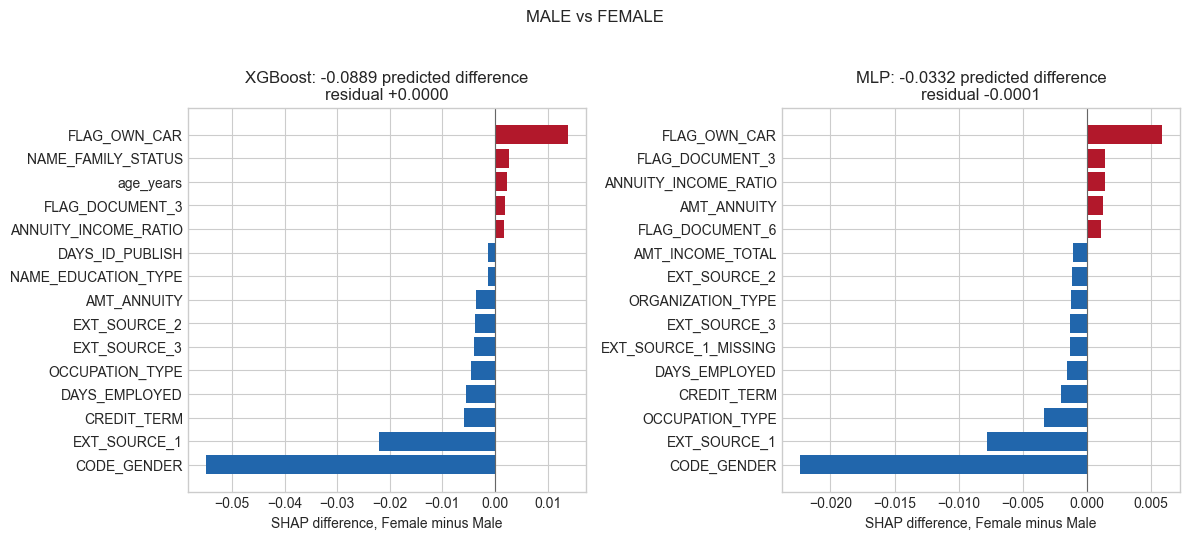

In [240]:
show_contrast("gender", "Female", "Male")

SELECTED SUBGROUP CONTRASTS: <25 vs 55–64


,model,grouping_variable,subgroup_a,subgroup_b,mean_prediction_a,mean_prediction_b,prediction_difference,observation_count_a,observation_count_b
2,XGBoost,age_band,<25,55–64,0.530328,0.324434,0.205894,1850,8995
3,MLP,age_band,<25,55–64,0.148485,0.060595,0.087891,1850,8995


GROUP PREDICTION DISPARITY DECOMPOSITION: <25 vs 55–64


,model,grouping_variable,subgroup_a,subgroup_b,feature,mean_shap_a,mean_shap_b,shap_difference,difference_rank
0,MLP,age_band,<25,55–64,EXT_SOURCE_1,0.022879,-0.007752,0.030631,1
1,MLP,age_band,<25,55–64,EXT_SOURCE_3,0.017938,-0.007116,0.025054,2
2,MLP,age_band,<25,55–64,EXT_SOURCE_2,0.018119,-0.001186,0.019304,3
3,MLP,age_band,<25,55–64,DAYS_ID_PUBLISH,0.007337,-0.003748,0.011085,4
4,MLP,age_band,<25,55–64,DAYS_EMPLOYED,0.008654,-0.000959,0.009613,5
5,MLP,age_band,<25,55–64,CREDIT_TERM,0.004904,-0.002317,0.007221,6
6,MLP,age_band,<25,55–64,age_years,-0.013506,-0.006547,-0.006959,7
7,MLP,age_band,<25,55–64,AMT_CREDIT,-0.005307,0.000877,-0.006184,8
8,MLP,age_band,<25,55–64,FLAG_DOCUMENT_6,-0.002325,0.003794,-0.006118,9
9,MLP,age_band,<25,55–64,EXT_SOURCE_1_MISSING,-0.004865,0.001204,-0.006070,10


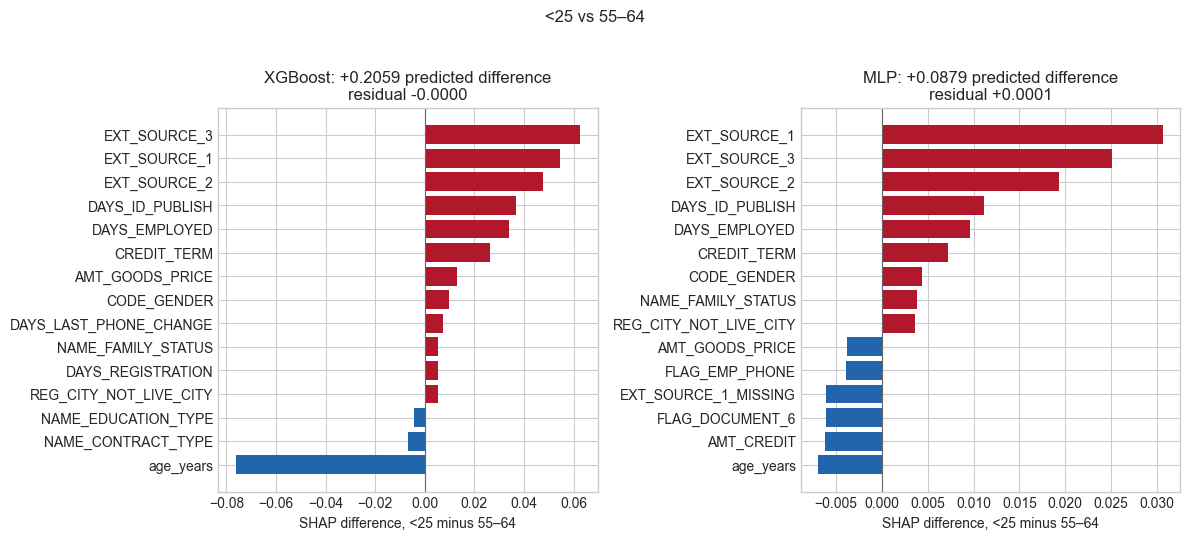

In [241]:
show_contrast("age_band", "<25", "55–64")

SELECTED SUBGROUP CONTRASTS: Q1 (LOWEST) vs Q4 (HIGHEST)


,model,grouping_variable,subgroup_a,subgroup_b,mean_prediction_a,mean_prediction_b,prediction_difference,observation_count_a,observation_count_b
4,XGBoost,income_band,Q1 low,Q4 high,0.405736,0.355909,0.049827,15123,10661
5,MLP,income_band,Q1 low,Q4 high,0.090991,0.076854,0.014137,15123,10661


GROUP PREDICTION DISPARITY DECOMPOSITION: Q1 (LOWEST) vs Q4 (HIGHEST)


,model,grouping_variable,subgroup_a,subgroup_b,feature,mean_shap_a,mean_shap_b,shap_difference,difference_rank
512,MLP,income_band,Q1 low,Q4 high,EXT_SOURCE_2,0.005490,-0.006993,0.012482,1
513,MLP,income_band,Q1 low,Q4 high,AMT_ANNUITY,0.004221,-0.004952,0.009173,2
514,MLP,income_band,Q1 low,Q4 high,AMT_CREDIT,-0.004180,0.004488,-0.008668,3
515,MLP,income_band,Q1 low,Q4 high,EXT_SOURCE_3,-0.005302,0.002828,-0.008130,4
516,MLP,income_band,Q1 low,Q4 high,AMT_GOODS_PRICE,-0.003593,0.003756,-0.007349,5
517,MLP,income_band,Q1 low,Q4 high,AMT_INCOME_TOTAL,-0.003173,0.004139,-0.007312,6
518,MLP,income_band,Q1 low,Q4 high,CODE_GENDER,-0.002177,0.003060,-0.005237,7
519,MLP,income_band,Q1 low,Q4 high,ANNUITY_INCOME_RATIO,0.002394,-0.002462,0.004856,8
520,MLP,income_band,Q1 low,Q4 high,FLAG_OWN_CAR,0.002152,-0.002202,0.004354,9
521,MLP,income_band,Q1 low,Q4 high,NAME_EDUCATION_TYPE,0.001552,-0.002762,0.004314,10


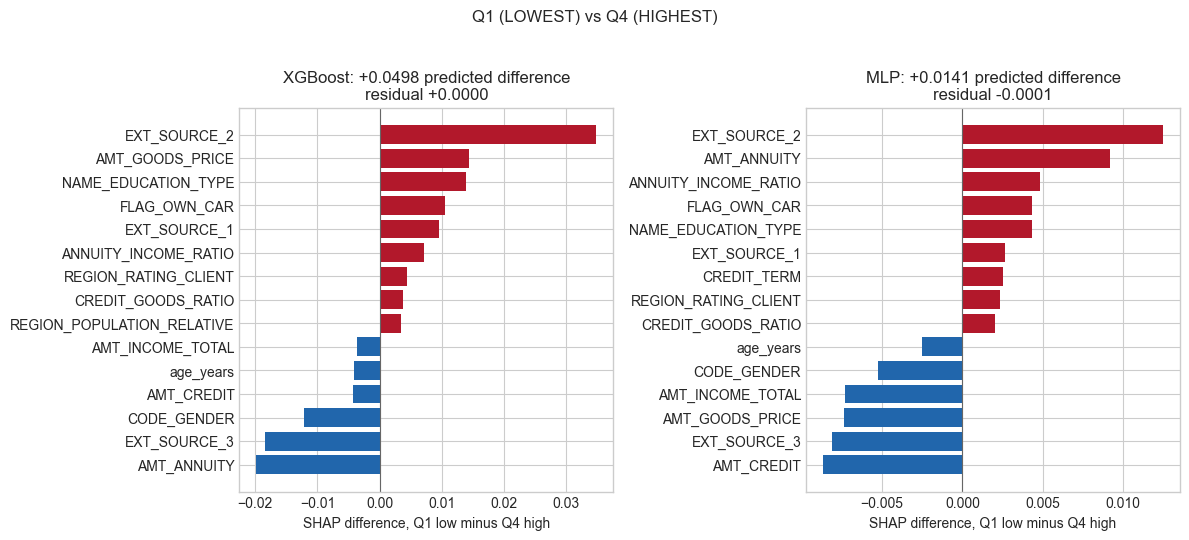

In [242]:
show_contrast("income_band", "Q1 low", "Q4 high")

SELECTED SUBGROUP CONTRASTS: FEMALE Q1 vs MALE Q1


,model,grouping_variable,subgroup_a,subgroup_b,mean_prediction_a,mean_prediction_b,prediction_difference,observation_count_a,observation_count_b
6,XGBoost,gender × income_band,Female | Q1 low,Male | Q1 low,0.380654,0.494632,-0.113979,11795,3328
7,MLP,gender × income_band,Female | Q1 low,Male | Q1 low,0.081497,0.124639,-0.043142,11795,3328


GROUP PREDICTION DISPARITY DECOMPOSITION: FEMALE Q1 vs MALE Q1


,model,grouping_variable,subgroup_a,subgroup_b,feature,mean_shap_a,mean_shap_b,shap_difference,difference_rank
256,MLP,gender × income_band,Female | Q1 low,Male | Q1 low,CODE_GENDER,-0.007694,0.017376,-0.025070,1
258,MLP,gender × income_band,Female | Q1 low,Male | Q1 low,EXT_SOURCE_1,-0.000486,0.006758,-0.007244,2
260,MLP,gender × income_band,Female | Q1 low,Male | Q1 low,EXT_SOURCE_2,0.004319,0.009637,-0.005317,3
262,MLP,gender × income_band,Female | Q1 low,Male | Q1 low,FLAG_OWN_CAR,0.003084,-0.001153,0.004237,4
264,MLP,gender × income_band,Female | Q1 low,Male | Q1 low,OCCUPATION_TYPE,-0.000901,0.002384,-0.003285,5
266,MLP,gender × income_band,Female | Q1 low,Male | Q1 low,CREDIT_TERM,0.000392,0.003193,-0.002801,6
268,MLP,gender × income_band,Female | Q1 low,Male | Q1 low,AMT_CREDIT,-0.003724,-0.005794,0.002070,7
270,MLP,gender × income_band,Female | Q1 low,Male | Q1 low,EXT_SOURCE_1_MISSING,-0.000561,0.001425,-0.001986,8
272,MLP,gender × income_band,Female | Q1 low,Male | Q1 low,DAYS_EMPLOYED,0.000265,0.002110,-0.001845,9
274,MLP,gender × income_band,Female | Q1 low,Male | Q1 low,EXT_SOURCE_3,-0.004910,-0.006692,0.001781,10


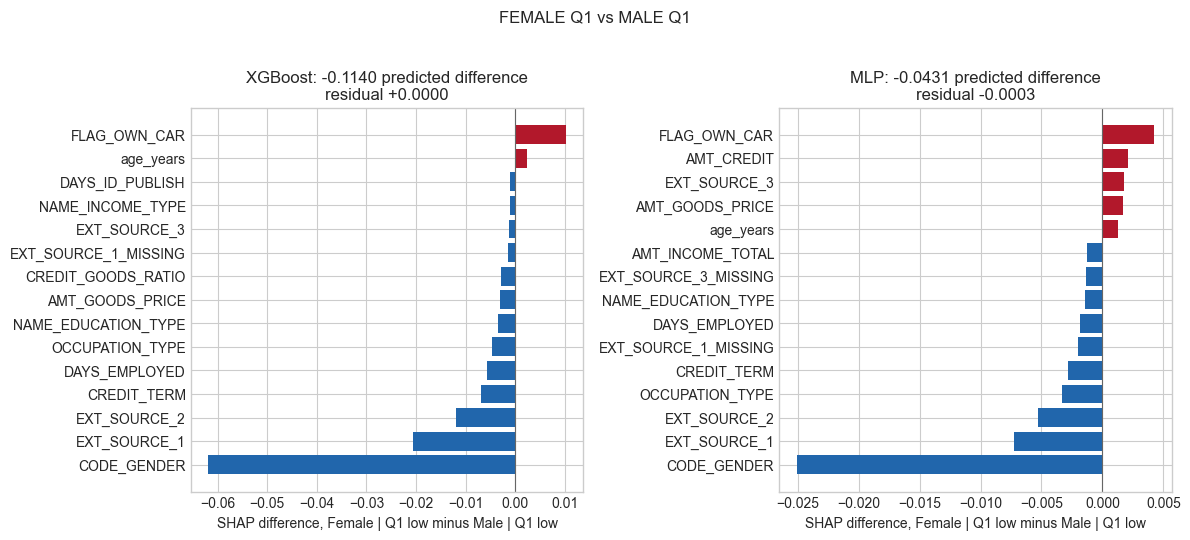

In [243]:
show_contrast("gender × income_band", "Female | Q1 low", "Male | Q1 low")

SELECTED SUBGROUP CONTRASTS: FEMALE Q4 vs MALE Q4


,model,grouping_variable,subgroup_a,subgroup_b,mean_prediction_a,mean_prediction_b,prediction_difference,observation_count_a,observation_count_b
8,XGBoost,gender × income_band,Female | Q4 high,Male | Q4 high,0.321910,0.394620,-0.072710,5676,4985
9,MLP,gender × income_band,Female | Q4 high,Male | Q4 high,0.064747,0.090639,-0.025892,5676,4985


GROUP PREDICTION DISPARITY DECOMPOSITION: FEMALE Q4 vs MALE Q4


,model,grouping_variable,subgroup_a,subgroup_b,feature,mean_shap_a,mean_shap_b,shap_difference,difference_rank
257,MLP,gender × income_band,Female | Q4 high,Male | Q4 high,CODE_GENDER,-0.006298,0.013715,-0.020013,1
259,MLP,gender × income_band,Female | Q4 high,Male | Q4 high,EXT_SOURCE_1,-0.005383,0.002875,-0.008258,2
261,MLP,gender × income_band,Female | Q4 high,Male | Q4 high,FLAG_OWN_CAR,0.000460,-0.005234,0.005694,3
263,MLP,gender × income_band,Female | Q4 high,Male | Q4 high,OCCUPATION_TYPE,-0.001424,0.001497,-0.002921,4
265,MLP,gender × income_band,Female | Q4 high,Male | Q4 high,FLAG_DOCUMENT_3,0.000413,-0.002077,0.002490,5
267,MLP,gender × income_band,Female | Q4 high,Male | Q4 high,CREDIT_TERM,-0.002388,-0.000504,-0.001885,6
269,MLP,gender × income_band,Female | Q4 high,Male | Q4 high,AMT_INCOME_TOTAL,0.004777,0.003412,0.001365,7
271,MLP,gender × income_band,Female | Q4 high,Male | Q4 high,ORGANIZATION_TYPE,-0.000327,0.000917,-0.001244,8
273,MLP,gender × income_band,Female | Q4 high,Male | Q4 high,DAYS_EMPLOYED,-0.001494,-0.000267,-0.001227,9
275,MLP,gender × income_band,Female | Q4 high,Male | Q4 high,NAME_FAMILY_STATUS,0.000408,-0.000565,0.000973,10


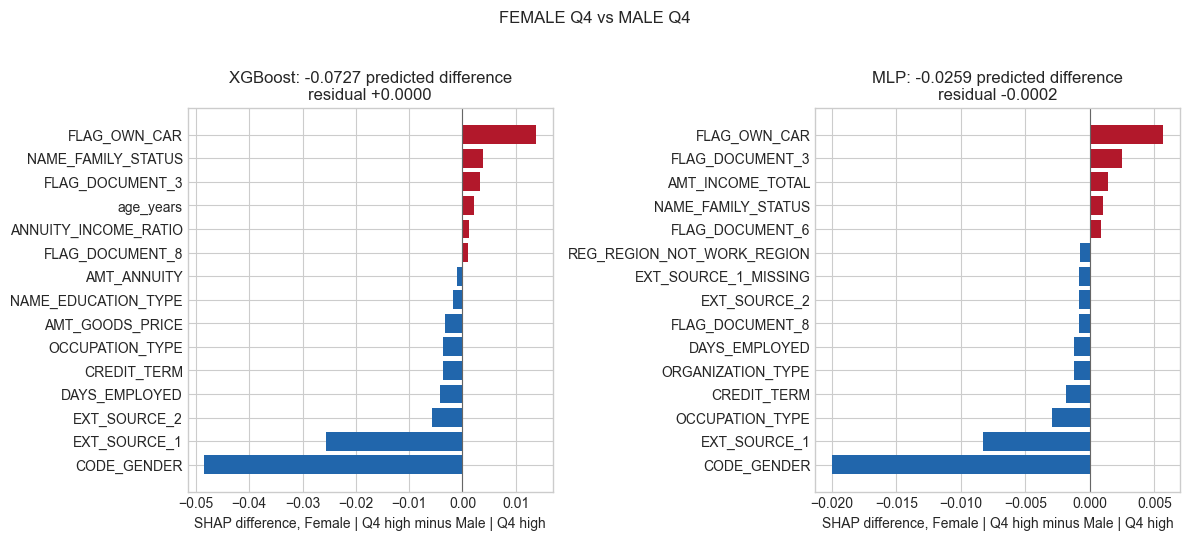

In [244]:
show_contrast("gender × income_band", "Female | Q4 high", "Male | Q4 high")

## 10. Exploratory Fairness Mitigation: Fairness Through Unawareness

This section retrains XGBoost and the MLP without the explicit `CODE_GENDER` input and compares them with the original models on the same test applicants. Removing gender does not remove gender-related information carried by other features. A change in a fairness metric is an observed consequence of this retraining experiment, not a causal effect of gender and not evidence that the blind model is fair.

The primary comparison keeps each architecture's original validation threshold. A separate sensitivity analysis reselects the blind-model threshold on the validation split only.


### 10.1 Gender-Blind Model Training


In [245]:
def validation_threshold(y_true, scores):
    false_positive_rate, true_positive_rate, candidates = roc_curve(y_true, scores)
    finite = np.isfinite(candidates)
    best = np.flatnonzero(finite)[np.argmax((true_positive_rate - false_positive_rate)[finite])]
    return float(candidates[best])


from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from xgboost import XGBClassifier

MITIGATION_DIR = AUDIT_DIR / "mitigation"
MITIGATION_DIR.mkdir(parents=True, exist_ok=True)
BLIND_XGB_PATH = MODEL_DIR / "xgboost_gender_blind.pkl"
BLIND_MLP_PATH = MODEL_DIR / "mlp_gender_blind.keras"
BLIND_PROB_PATH = MITIGATION_DIR / "probabilities.npz"
BLIND_MANIFEST_PATH = MITIGATION_DIR / "manifest.json"
ORIGINAL_MODEL_PATHS = {
    "XGBoost": MODEL_DIR / "xgboost_model.pkl",
    "MLP": MODEL_DIR / "mlp_model.keras",
}
original_model_hashes = {name: hashlib.sha256(path.read_bytes()).hexdigest() for name, path in ORIGINAL_MODEL_PATHS.items()}

if list(X_test.columns) != list(feature_names):
    raise AssertionError("Transformed test columns do not match the saved feature names.")
gender_columns = [name for name in feature_names if name == "CODE_GENDER" or str(name).startswith("CODE_GENDER_")]
if not gender_columns:
    raise AssertionError("No encoded CODE_GENDER columns were found.")
blind_columns = [name for name in feature_names if name not in gender_columns]
if any(str(name).startswith("CODE_GENDER") for name in blind_columns):
    raise AssertionError("A CODE_GENDER column remained in the gender-blind matrix.")

X_train_full = pd.DataFrame(preprocessor.transform(X_train_raw), columns=feature_names)
X_val_blind = X_val.loc[:, blind_columns].copy()
X_test_blind = X_test.loc[:, blind_columns].copy()
X_train_blind = X_train_full.loc[:, blind_columns].copy()
if not X_train_full.drop(columns=gender_columns).reset_index(drop=True).equals(X_train_blind.reset_index(drop=True)):
    raise AssertionError("Removing gender changed another training column.")
if not X_test.drop(columns=gender_columns).reset_index(drop=True).equals(X_test_blind.reset_index(drop=True)):
    raise AssertionError("Removing gender changed another test column.")

scale_pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())
xgb_params = {
    "colsample_bytree": 0.7229163764267956,
    "learning_rate": 0.03899272558722083,
    "max_depth": 5,
    "min_child_weight": 8,
    "n_estimators": 472,
    "subsample": 0.8404460046972835,
}
SELECTED_GROUPINGS = ["gender", "age_band", "income_band", "gender × age_band", "gender × income_band"]
selected_groupings = list(SELECTED_GROUPINGS)
THRESHOLDS = {
    "XGBoost": float(validation_threshold(audit_val["TARGET"], audit_val["XGBoost_score"])),
    "MLP": float(validation_threshold(audit_val["TARGET"], audit_val["MLP_score"])),
}
saved_thresholds = pd.read_csv(AUDIT_DIR / "overall_metrics.csv")
saved_thresholds = saved_thresholds[saved_thresholds["split"].eq("validation")].set_index("model")["threshold"]
for model_name, threshold in THRESHOLDS.items():
    if abs(threshold - float(saved_thresholds.loc[model_name])) > 1e-8:
        raise AssertionError(f"{model_name} threshold does not match the saved validation threshold.")

manifest = {
    "seed": int(SEED),
    "scale_pos_weight": scale_pos_weight,
    "xgb_params": xgb_params,
    "excluded_features": gender_columns,
    "blind_features": blind_columns,
    "n_train": int(len(y_train)),
    "n_validation": int(len(y_val)),
    "n_test": int(len(y_test)),
    "test_id_first": int(audit_test["SK_ID_CURR"].iloc[0]),
    "test_id_last": int(audit_test["SK_ID_CURR"].iloc[-1]),
}
cache_matches = False
if BLIND_MANIFEST_PATH.exists() and BLIND_XGB_PATH.exists() and BLIND_MLP_PATH.exists() and BLIND_PROB_PATH.exists():
    stored = json.loads(BLIND_MANIFEST_PATH.read_text())
    comparable = {key: stored.get(key) for key in manifest}
    cache_matches = comparable == manifest

if cache_matches:
    blind_xgb = joblib.load(BLIND_XGB_PATH)
    blind_mlp = keras.models.load_model(BLIND_MLP_PATH)
    stored_probabilities = np.load(BLIND_PROB_PATH)
    blind_val_scores = {
        "XGBoost": stored_probabilities["xgb_val"],
        "MLP": stored_probabilities["mlp_val"],
    }
    blind_test_scores = {
        "XGBoost": stored_probabilities["xgb_test"],
        "MLP": stored_probabilities["mlp_test"],
    }
    blind_fit_report = json.loads(BLIND_MANIFEST_PATH.read_text())["fit_report"]
else:
    blind_xgb = XGBClassifier(
        **xgb_params,
        scale_pos_weight=scale_pos_weight,
        eval_metric="auc",
        tree_method="hist",
        random_state=SEED,
        n_jobs=-1,
        verbosity=0,
    )
    blind_xgb.fit(X_train_blind, y_train)
    keras.backend.clear_session()
    tf.random.set_seed(SEED)
    np.random.seed(SEED)
    blind_mlp = keras.Sequential(name="MLP_LeakyReLU_GenderBlind")
    blind_mlp.add(layers.Input(shape=(len(blind_columns),)))
    for units in (128, 64):
        blind_mlp.add(layers.Dense(units, use_bias=False))
        blind_mlp.add(layers.BatchNormalization())
        blind_mlp.add(layers.LeakyReLU(alpha=0.1))
        blind_mlp.add(layers.Dropout(0.5, seed=SEED))
    blind_mlp.add(layers.Dense(1, activation="sigmoid"))
    import logging
    logging.getLogger("absl").setLevel(logging.ERROR)
    blind_mlp.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=[keras.metrics.AUC(name="auc")],
    )
    early_stopping = EarlyStopping(
        monitor="val_auc", patience=10, mode="max", restore_best_weights=True, verbose=0,
    )
    history = blind_mlp.fit(
        X_train_blind.to_numpy(dtype=np.float32),
        y_train.to_numpy(dtype=np.float32),
        validation_data=(X_val_blind.to_numpy(dtype=np.float32), y_val.to_numpy(dtype=np.float32)),
        epochs=100,
        batch_size=1024,
        callbacks=[early_stopping],
        verbose=0,
    )
    blind_val_scores = {
        "XGBoost": blind_xgb.predict_proba(X_val_blind)[:, 1],
        "MLP": blind_mlp.predict(X_val_blind.to_numpy(dtype=np.float32), verbose=0).ravel(),
    }
    blind_test_scores = {
        "XGBoost": blind_xgb.predict_proba(X_test_blind)[:, 1],
        "MLP": blind_mlp.predict(X_test_blind.to_numpy(dtype=np.float32), verbose=0).ravel(),
    }
    best_epoch = int(np.argmax(history.history["val_auc"])) + 1
    blind_fit_report = {
        "mlp_epochs_ran": int(len(history.history["val_auc"])),
        "mlp_best_epoch": best_epoch,
        "mlp_best_val_auc": float(np.max(history.history["val_auc"])),
        "xgb_n_estimators": int(xgb_params["n_estimators"]),
    }
    joblib.dump(blind_xgb, BLIND_XGB_PATH)
    blind_mlp.save(BLIND_MLP_PATH)
    np.savez(
        BLIND_PROB_PATH,
        xgb_val=blind_val_scores["XGBoost"],
        mlp_val=blind_val_scores["MLP"],
        xgb_test=blind_test_scores["XGBoost"],
        mlp_test=blind_test_scores["MLP"],
    )
    BLIND_MANIFEST_PATH.write_text(json.dumps({**manifest, "fit_report": blind_fit_report}, indent=2))

for model_name, path in ORIGINAL_MODEL_PATHS.items():
    current_hash = hashlib.sha256(path.read_bytes()).hexdigest()
    if current_hash != original_model_hashes[model_name]:
        raise AssertionError(f"Original {model_name} model file changed.")
for model_name, scores in {**{"XGBoost_val": audit_val["XGBoost_score"], "MLP_val": audit_val["MLP_score"]}}.items():
    pass
for scores in list(blind_val_scores.values()) + list(blind_test_scores.values()):
    scores = np.asarray(scores, dtype=float)
    if scores.shape != (len(y_test),) and scores.shape != (len(y_val),):
        raise AssertionError(f"Unexpected blind score length: {scores.shape}")
    if not np.isfinite(scores).all() or scores.min() < -1e-6 or scores.max() > 1 + 1e-6:
        raise AssertionError("Blind model scores are not valid probabilities.")
if hashlib.sha256(ORIGINAL_MODEL_PATHS["XGBoost"].read_bytes()).hexdigest() != original_model_hashes["XGBoost"]:
    raise AssertionError("Original XGBoost file changed during blind training.")



### 10.2 Predictive Performance Comparison


In [246]:
def validation_threshold(y_true, scores):
    false_positive_rate, true_positive_rate, candidates = roc_curve(y_true, scores)
    finite = np.isfinite(candidates)
    best = np.flatnonzero(finite)[np.argmax((true_positive_rate - false_positive_rate)[finite])]
    return float(candidates[best])


def precision_recall_auc(y_true, scores):
    precision_points, recall_points, _ = precision_recall_curve(y_true, scores)
    return float(auc(recall_points, precision_points))


def probability_metrics(y_true, scores, threshold):
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores, dtype=float)
    predicted_default = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predicted_default, labels=[0, 1]).ravel()
    return {
        "roc_auc": float(roc_auc_score(y_true, scores)),
        "average_precision": precision_recall_auc(y_true, scores),
        "brier_score": float(brier_score_loss(y_true, scores)),
        "accuracy": float((tp + tn) / len(y_true)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, predicted_default)),
        "approval_rate": float(np.mean(scores < threshold)),
        "test_count": int(len(y_true)),
    }


original_test_scores = {
    "XGBoost": audit_test["XGBoost_score"].to_numpy(dtype=float),
    "MLP": audit_test["MLP_score"].to_numpy(dtype=float),
}
original_val_scores = {
    "XGBoost": audit_val["XGBoost_score"].to_numpy(dtype=float),
    "MLP": audit_val["MLP_score"].to_numpy(dtype=float),
}
y_test_array = audit_test["TARGET"].to_numpy(dtype=int)
y_val_array = audit_val["TARGET"].to_numpy(dtype=int)
saved_test = pd.read_csv(AUDIT_DIR / "overall_metrics.csv")
saved_test = saved_test[saved_test["split"].eq("test")].set_index("model")
for model_name, scores in original_test_scores.items():
    reproduced = probability_metrics(y_test_array, scores, THRESHOLDS[model_name])["roc_auc"]
    if abs(reproduced - float(saved_test.loc[model_name, "roc_auc"])) > 1e-6:
        raise AssertionError(f"{model_name} test ROC-AUC does not reproduce the saved baseline.")

retuned_thresholds = {
    model_name: float(validation_threshold(y_val_array, scores))
    for model_name, scores in blind_val_scores.items()
}
score_sets = {
    ("XGBoost", "Original"): original_test_scores["XGBoost"],
    ("XGBoost", "Gender-Blind"): np.asarray(blind_test_scores["XGBoost"], dtype=float),
    ("MLP", "Original"): original_test_scores["MLP"],
    ("MLP", "Gender-Blind"): np.asarray(blind_test_scores["MLP"], dtype=float),
}

performance_rows = []
for policy in ["original_fixed", "validation_retuned"]:
    for architecture, variant in [("XGBoost", "Original"), ("XGBoost", "Gender-Blind"), ("MLP", "Original"), ("MLP", "Gender-Blind")]:
        if policy == "original_fixed" or variant == "Original":
            threshold = THRESHOLDS[architecture]
        else:
            threshold = retuned_thresholds[architecture]
        row = {
            "architecture": architecture,
            "model_variant": variant,
            "threshold_policy": policy,
            "decision_threshold": threshold,
        }
        row.update(probability_metrics(y_test_array, score_sets[(architecture, variant)], threshold))
        performance_rows.append(row)
performance = pd.DataFrame(performance_rows)
performance.to_csv(MITIGATION_DIR / "predictive_performance.csv", index=False)

change_rows = []
for policy in ["original_fixed", "validation_retuned"]:
    for architecture in ["XGBoost", "MLP"]:
        current = performance[performance["threshold_policy"].eq(policy) & performance["architecture"].eq(architecture)]
        original = current[current["model_variant"].eq("Original")].iloc[0]
        blind = current[current["model_variant"].eq("Gender-Blind")].iloc[0]
        change = {"architecture": architecture, "threshold_policy": policy}
        for column in ["roc_auc", "average_precision", "brier_score", "accuracy", "balanced_accuracy", "approval_rate"]:
            change[f"{column}_change"] = float(blind[column] - original[column])
        change["threshold_change"] = float(blind["decision_threshold"] - original["decision_threshold"])
        change_rows.append(change)
performance_change = pd.DataFrame(change_rows)
performance_change.to_csv(MITIGATION_DIR / "predictive_performance_change.csv", index=False)

print("RETUNED GENDER-BLIND THRESHOLDS")
for model_name, threshold in retuned_thresholds.items():
    print(f"{model_name}: original {THRESHOLDS[model_name]:.6f}, retuned {threshold:.6f}, change {threshold - THRESHOLDS[model_name]:+.6f}")
print("PREDICTIVE PERFORMANCE BEFORE VS. AFTER MITIGATION")
display(performance.round(6))
print("PERFORMANCE CHANGE (GENDER-BLIND - ORIGINAL)")
display(performance_change.round(6))


RETUNED GENDER-BLIND THRESHOLDS
XGBoost: original 0.470434, retuned 0.488049, change +0.017615
MLP: original 0.092110, retuned 0.096645, change +0.004534
PREDICTIVE PERFORMANCE BEFORE VS. AFTER MITIGATION


,architecture,model_variant,threshold_policy,decision_threshold,roc_auc,average_precision,brier_score,accuracy,balanced_accuracy,approval_rate,test_count
0,XGBoost,Original,original_fixed,0.4704,0.7689,0.2583,0.1851,0.6894,0.6982,0.6557,46126
1,XGBoost,Gender-Blind,original_fixed,0.4704,0.7690,0.2565,0.1853,0.6895,0.6986,0.6557,46126
2,MLP,Original,original_fixed,0.0921,0.7566,0.2404,0.0682,0.6896,0.6904,0.6587,46126
3,MLP,Gender-Blind,original_fixed,0.0921,0.7560,0.2392,0.0682,0.7096,0.6869,0.6838,46126
4,XGBoost,Original,validation_retuned,0.4704,0.7689,0.2583,0.1851,0.6894,0.6982,0.6557,46126
5,XGBoost,Gender-Blind,validation_retuned,0.4880,0.7690,0.2565,0.1853,0.7084,0.6987,0.6782,46126
6,MLP,Original,validation_retuned,0.0921,0.7566,0.2404,0.0682,0.6896,0.6904,0.6587,46126
7,MLP,Gender-Blind,validation_retuned,0.0966,0.7560,0.2392,0.0682,0.7228,0.6874,0.6993,46126


PERFORMANCE CHANGE (GENDER-BLIND - ORIGINAL)


,architecture,threshold_policy,roc_auc_change,average_precision_change,brier_score_change,accuracy_change,balanced_accuracy_change,approval_rate_change,threshold_change
0,XGBoost,original_fixed,0.0001,-0.0018,0.0002,0.0001,0.0004,0.0000,0.0000
1,MLP,original_fixed,-0.0006,-0.0012,0.0000,0.0201,-0.0035,0.0252,0.0000
2,XGBoost,validation_retuned,0.0001,-0.0018,0.0002,0.0190,0.0006,0.0225,0.0176
3,MLP,validation_retuned,-0.0006,-0.0012,0.0000,0.0332,-0.0030,0.0407,0.0045


### 10.3 Fairness Metric Comparison


FAIRNESS METRICS BEFORE VS. AFTER MITIGATION


,architecture,grouping_variable,fairness_metric,original_value,blind_value,absolute_change,improvement_direction,improved_or_worsened,threshold_policy,n_eligible_subgroups,comparison_population
0,XGBoost,gender,demographic_parity_difference,0.1709,0.1093,-0.0617,toward_zero,improved,original_fixed,2,all_populated_subgroups
1,XGBoost,gender,demographic_parity_ratio,0.7606,0.8423,0.0817,toward_one,improved,original_fixed,2,all_populated_subgroups
2,XGBoost,gender,equal_opportunity_difference,0.1589,0.0971,-0.0618,toward_zero,improved,original_fixed,2,all_populated_subgroups
3,XGBoost,gender,equal_opportunity_ratio,0.7855,0.8651,0.0797,toward_one,improved,original_fixed,2,all_populated_subgroups
4,XGBoost,gender,equalized_odds_difference,0.1621,0.0992,-0.0629,toward_zero,improved,original_fixed,2,all_populated_subgroups
5,XGBoost,gender,equalized_odds_ratio,0.5503,0.7019,0.1516,toward_one,improved,original_fixed,2,all_populated_subgroups
6,XGBoost,age_band,demographic_parity_difference,0.5230,0.5271,0.0040,toward_zero,worsened,original_fixed,5,all_populated_subgroups
7,XGBoost,age_band,demographic_parity_ratio,0.4256,0.4207,-0.0050,toward_one,worsened,original_fixed,5,all_populated_subgroups
8,XGBoost,age_band,equal_opportunity_difference,0.4919,0.4957,0.0038,toward_zero,worsened,original_fixed,5,all_populated_subgroups
9,XGBoost,age_band,equal_opportunity_ratio,0.4643,0.4591,-0.0052,toward_one,worsened,original_fixed,5,all_populated_subgroups


FIXED-THRESHOLD FAIRNESS RESULT COUNTS


improved_or_worsened,improved,unchanged,worsened
architecture,,,
MLP,25,0,5
XGBoost,22,1,7


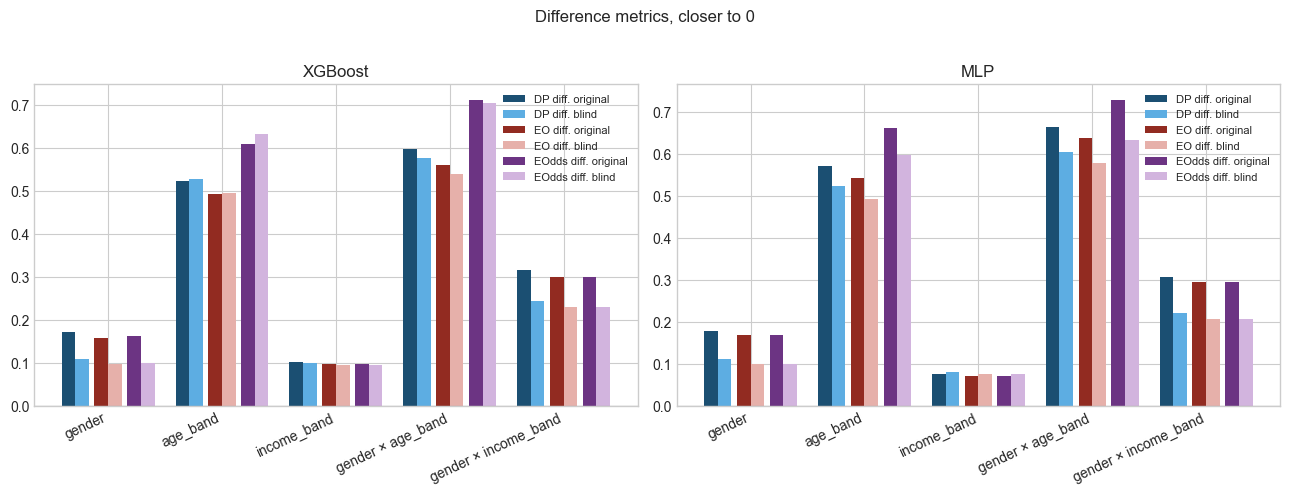

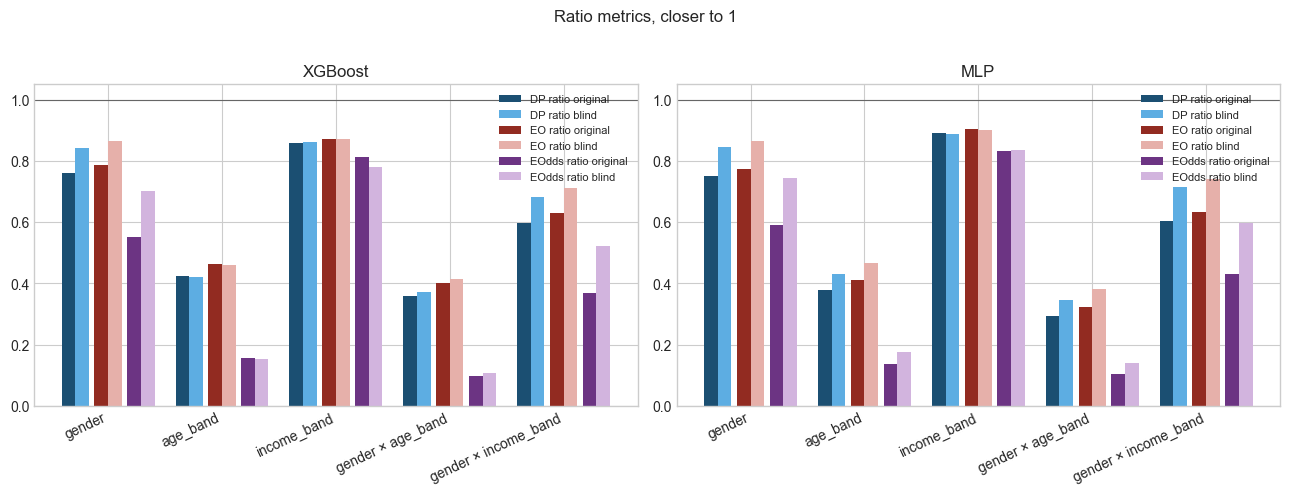

In [247]:
from fairlearn.metrics import (
    demographic_parity_difference,
    demographic_parity_ratio,
    equal_opportunity_difference,
    equal_opportunity_ratio,
    equalized_odds_difference,
    equalized_odds_ratio,
)

FAIRNESS_METRICS = [
    ("demographic_parity_difference", demographic_parity_difference, "toward_zero"),
    ("demographic_parity_ratio", demographic_parity_ratio, "toward_one"),
    ("equal_opportunity_difference", equal_opportunity_difference, "toward_zero"),
    ("equal_opportunity_ratio", equal_opportunity_ratio, "toward_one"),
    ("equalized_odds_difference", equalized_odds_difference, "toward_zero"),
    ("equalized_odds_ratio", equalized_odds_ratio, "toward_one"),
]
CHANGE_TOLERANCE = 1e-3
support_lookup = population_summary.loc[
    population_summary["grouping_variable"].isin(selected_groupings),
    ["grouping_variable", "subgroup", "support_flag"],
].copy()
support_lookup["subgroup"] = support_lookup["subgroup"].astype(str)
eligible_counts = (
    support_lookup[support_lookup["support_flag"].eq("ok")]
    .groupby("grouping_variable")["subgroup"].nunique().to_dict()
)


def approval_arrays(scores, threshold):
    scores = np.asarray(scores, dtype=float)
    favorable_prediction = (scores < threshold).astype(int)
    favorable_label = (y_test_array == 0).astype(int)
    return favorable_label, favorable_prediction


def parity_label(direction, original, blind):
    change = float(blind - original)
    if not np.isfinite(original) or not np.isfinite(blind):
        return change, "undefined"
    if abs(change) < CHANGE_TOLERANCE:
        return change, "unchanged"
    if direction == "toward_zero":
        return change, "improved" if change < 0 else "worsened"
    return change, "improved" if abs(blind - 1) < abs(original - 1) else "worsened"


def fairness_rows_for(policy):
    rows = []
    for architecture in ["XGBoost", "MLP"]:
        threshold_original = THRESHOLDS[architecture]
        threshold_blind = threshold_original if policy == "original_fixed" else retuned_thresholds[architecture]
        comparisons = {
            "Original": approval_arrays(score_sets[(architecture, "Original")], threshold_original),
            "Gender-Blind": approval_arrays(score_sets[(architecture, "Gender-Blind")], threshold_blind),
        }
        for grouping in selected_groupings:
            sensitive = audit_test[grouping].astype(str)
            values = {}
            for variant, (label, prediction) in comparisons.items():
                values[variant] = {}
                for metric_name, metric, _direction in FAIRNESS_METRICS:
                    values[variant][metric_name] = float(metric(
                        label, prediction, sensitive_features=sensitive, method="between_groups",
                    ))
            for metric_name, _metric, direction in FAIRNESS_METRICS:
                original = values["Original"][metric_name]
                blind = values["Gender-Blind"][metric_name]
                change, assessment = parity_label(direction, original, blind)
                rows.append({
                    "architecture": architecture,
                    "grouping_variable": grouping,
                    "fairness_metric": metric_name,
                    "original_value": original,
                    "blind_value": blind,
                    "absolute_change": change,
                    "improvement_direction": direction,
                    "improved_or_worsened": assessment,
                    "threshold_policy": policy,
                    "n_eligible_subgroups": int(eligible_counts.get(grouping, 0)),
                    "comparison_population": "all_populated_subgroups",
                })
    return pd.DataFrame(rows)


fairness_comparison = pd.concat(
    [fairness_rows_for("original_fixed"), fairness_rows_for("validation_retuned")],
    ignore_index=True,
)
fairness_comparison.to_csv(MITIGATION_DIR / "fairness_metric_comparison.csv", index=False)
fixed_fairness = fairness_comparison[fairness_comparison["threshold_policy"].eq("original_fixed")].copy()
fairness_tally = (
    fixed_fairness.groupby(["architecture", "improved_or_worsened"]).size().unstack(fill_value=0)
)
print("FAIRNESS METRICS BEFORE VS. AFTER MITIGATION")
with pd.option_context("display.max_rows", 20, "display.min_rows", 20):
    display(fairness_comparison.round(6))
print("FIXED-THRESHOLD FAIRNESS RESULT COUNTS")
display(fairness_tally)

difference_metrics = [name for name, _metric, direction in FAIRNESS_METRICS if direction == "toward_zero"]
ratio_metrics = [name for name, _metric, direction in FAIRNESS_METRICS if direction == "toward_one"]
short_labels = {
    "demographic_parity_difference": "DP diff.",
    "equal_opportunity_difference": "EO diff.",
    "equalized_odds_difference": "EOdds diff.",
    "demographic_parity_ratio": "DP ratio",
    "equal_opportunity_ratio": "EO ratio",
    "equalized_odds_ratio": "EOdds ratio",
}
for metric_group, metric_names, filename, reference in (
    (difference_metrics, difference_metrics, "mitigation_fairness_differences.png", 0),
    (ratio_metrics, ratio_metrics, "mitigation_fairness_ratios.png", 1),
):
    figure, axes = plt.subplots(1, 2, figsize=(13, 4.8), squeeze=False)
    positions = np.arange(len(selected_groupings))
    width = 0.12
    for column, architecture in enumerate(["XGBoost", "MLP"]):
        axis = axes[0, column]
        part = fixed_fairness[fixed_fairness["architecture"].eq(architecture)]
        original_colors = ["#1b4f72", "#922b21", "#6c3483"]
        blind_colors = ["#5dade2", "#e6b0aa", "#d2b4de"]
        for index, metric_name in enumerate(metric_names):
            subset = part[part["fairness_metric"].eq(metric_name)].set_index("grouping_variable").loc[selected_groupings]
            offset = (index - (len(metric_names) - 1) / 2) * width * 2.4
            axis.bar(positions + offset - width / 2, subset["original_value"], width=width, color=original_colors[index], label=f"{short_labels[metric_name]} original")
            axis.bar(positions + offset + width / 2, subset["blind_value"], width=width, color=blind_colors[index], label=f"{short_labels[metric_name]} blind")
        axis.axhline(reference, color="0.4", lw=0.8)
        axis.set_xticks(positions, selected_groupings, rotation=25, ha="right")
        axis.set_title(architecture)
        axis.legend(frameon=False, fontsize=8)
    figure.suptitle(
        "Difference metrics, closer to 0" if reference == 0 else "Ratio metrics, closer to 1",
        y=1.02,
    )
    figure.tight_layout()
    figure.savefig(FIGURE_DIR / filename, dpi=160, bbox_inches="tight")
    display(figure)
    plt.close(figure)

gender_check = fixed_fairness[
    fixed_fairness["architecture"].eq("XGBoost")
    & fixed_fairness["grouping_variable"].eq("gender")
    & fixed_fairness["fairness_metric"].eq("demographic_parity_difference")
].iloc[0]
female = audit_test["gender"].astype(str).eq("Female").to_numpy()
male = ~female
original_approval = original_test_scores["XGBoost"] < THRESHOLDS["XGBoost"]
manual_gap = abs(original_approval[female].mean() - original_approval[male].mean())
if abs(manual_gap - gender_check["original_value"]) > 1e-8:
    raise AssertionError("Gender demographic parity does not match the two-group approval gap.")


### 10.4 Subgroup and Intersectional Impact


SUBGROUP FAIRNESS IMPACT BEFORE VS. AFTER MITIGATION


,architecture,grouping_variable,subgroup,count,support_flag,original_selection_rate,blind_selection_rate,selection_rate_change,original_tpr,blind_tpr,tpr_change,original_fpr,blind_fpr,fpr_change,threshold_policy
0,XGBoost,gender,Male,15716,ok,0.5430,0.5837,0.0407,0.5818,0.6230,0.0413,0.1984,0.2336,0.0353,original_fixed
1,XGBoost,gender,Female,30410,ok,0.7139,0.6929,-0.0210,0.7406,0.7201,-0.0205,0.3605,0.3329,-0.0276,original_fixed
2,XGBoost,age_band,35–44,12731,ok,0.6476,0.6453,-0.0023,0.6804,0.6781,-0.0023,0.2822,0.2803,-0.0019,original_fixed
3,XGBoost,age_band,55–64,8995,ok,0.8056,0.8058,0.0002,0.8215,0.8217,0.0002,0.5229,0.5229,0.0000,original_fixed
4,XGBoost,age_band,<25,1850,ok,0.3876,0.3827,-0.0049,0.4263,0.4207,-0.0056,0.1135,0.1135,0.0000,original_fixed
5,XGBoost,age_band,25–34,10763,ok,0.5144,0.5146,0.0002,0.5514,0.5526,0.0012,0.1998,0.1910,-0.0088,original_fixed
6,XGBoost,age_band,45–54,10579,ok,0.6996,0.7029,0.0033,0.7302,0.7329,0.0028,0.3198,0.3299,0.0102,original_fixed
7,XGBoost,age_band,65+,1208,low_support,0.9106,0.9098,-0.0008,0.9182,0.9165,-0.0017,0.7234,0.7447,0.0213,original_fixed
8,XGBoost,income_band,Q2,7879,ok,0.6206,0.6233,0.0027,0.6535,0.6564,0.0029,0.2776,0.2776,0.0000,original_fixed
9,XGBoost,income_band,Q4 high,10661,ok,0.7224,0.7243,0.0019,0.7510,0.7526,0.0016,0.3410,0.3464,0.0054,original_fixed


INDIVIDUAL DECISION CHANGES


,architecture,grouping_variable,subgroup,count,approved_both,rejected_both,rejected_to_approved,approved_to_rejected,total_flipped,flip_rate,net_approval_change,support_flag,threshold_policy
0,XGBoost,gender,Male,15716,8360,6369,813,174,987,0.0628,639,ok,original_fixed
1,XGBoost,gender,Female,30410,20783,8410,289,928,1217,0.0400,-639,ok,original_fixed
2,XGBoost,age_band,35–44,12731,7935,4207,280,309,589,0.0463,-29,ok,original_fixed
3,XGBoost,age_band,55–64,8995,7036,1537,212,210,422,0.0469,2,ok,original_fixed
4,XGBoost,age_band,<25,1850,665,1090,43,52,95,0.0514,-9,ok,original_fixed
5,XGBoost,age_band,25–34,10763,5269,4956,270,268,538,0.0500,2,ok,original_fixed
6,XGBoost,age_band,45–54,10579,7164,2906,272,237,509,0.0481,35,ok,original_fixed
7,XGBoost,age_band,65+,1208,1074,83,25,26,51,0.0422,-1,low_support,original_fixed
8,XGBoost,income_band,Q2,7879,4709,2787,202,181,383,0.0486,21,ok,original_fixed
9,XGBoost,income_band,Q4 high,10661,7485,2722,237,217,454,0.0426,20,ok,original_fixed


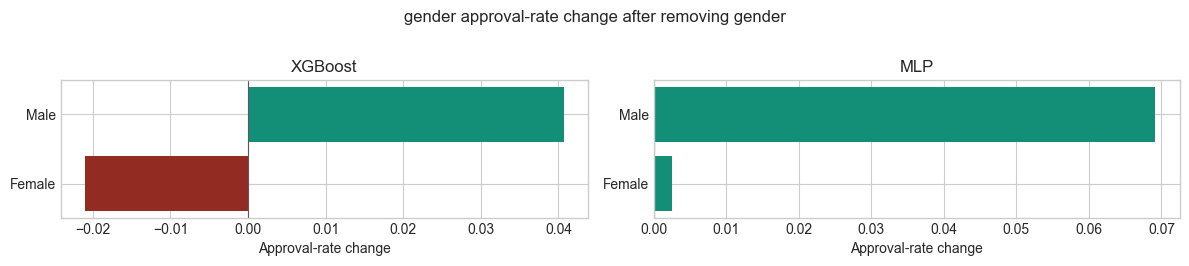

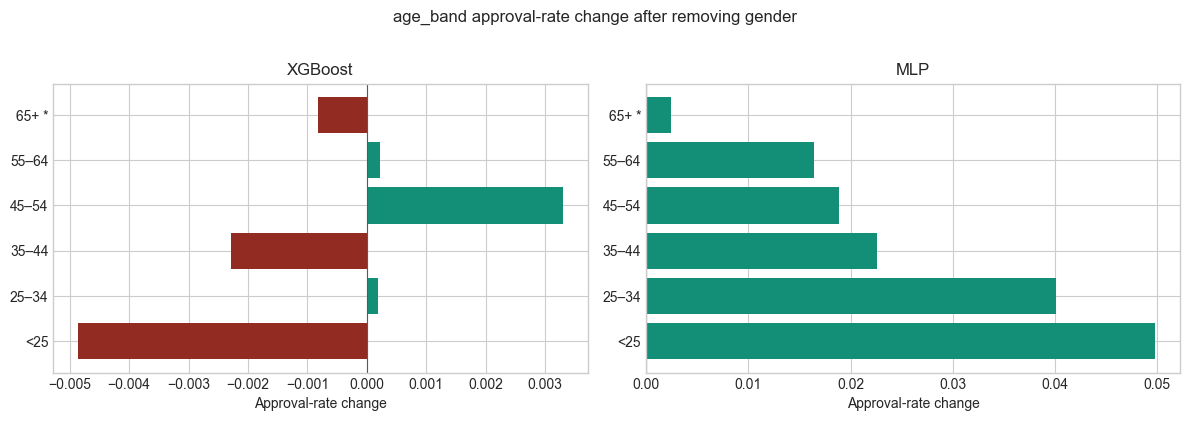

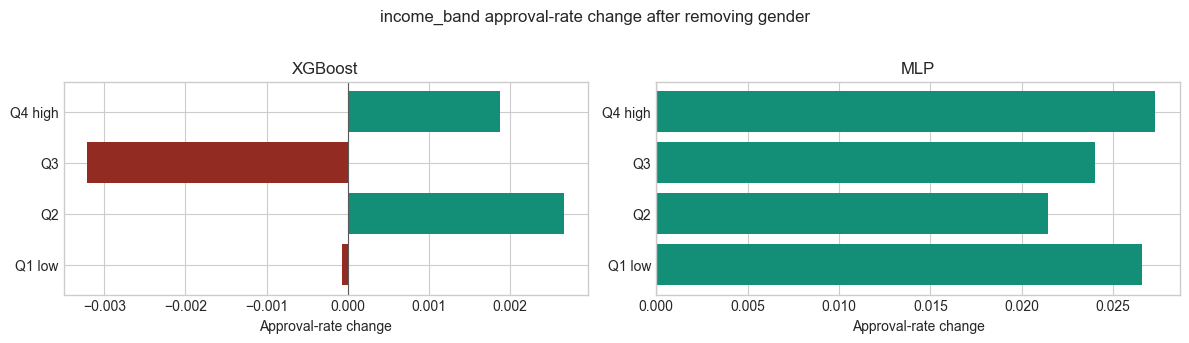

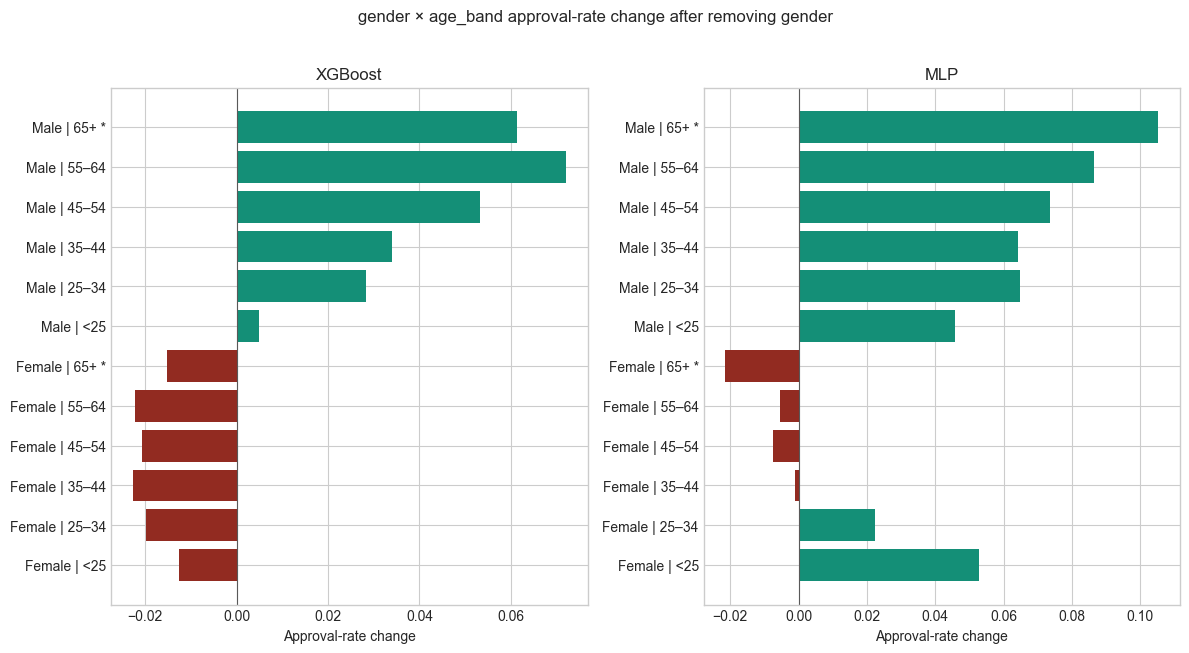

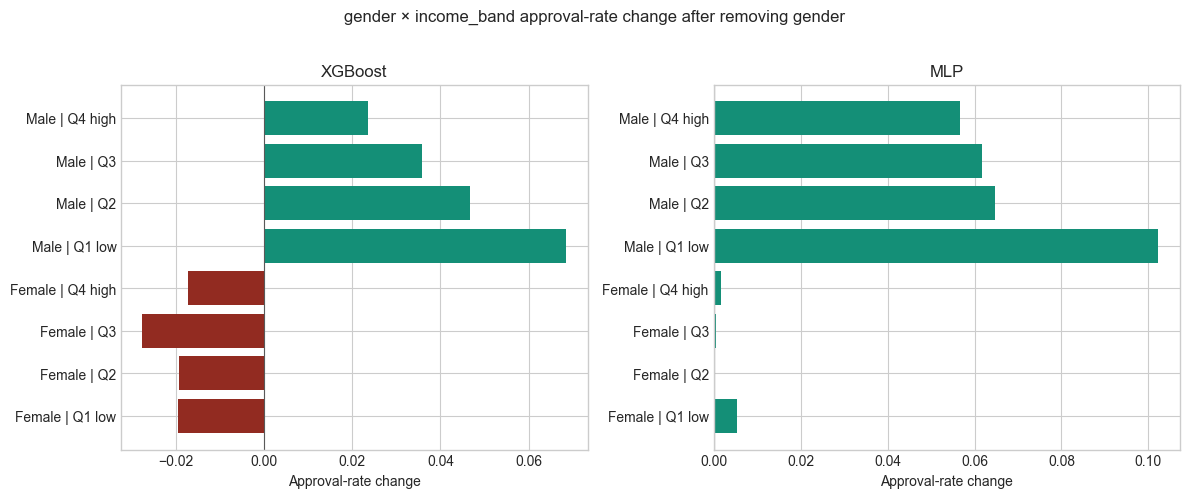

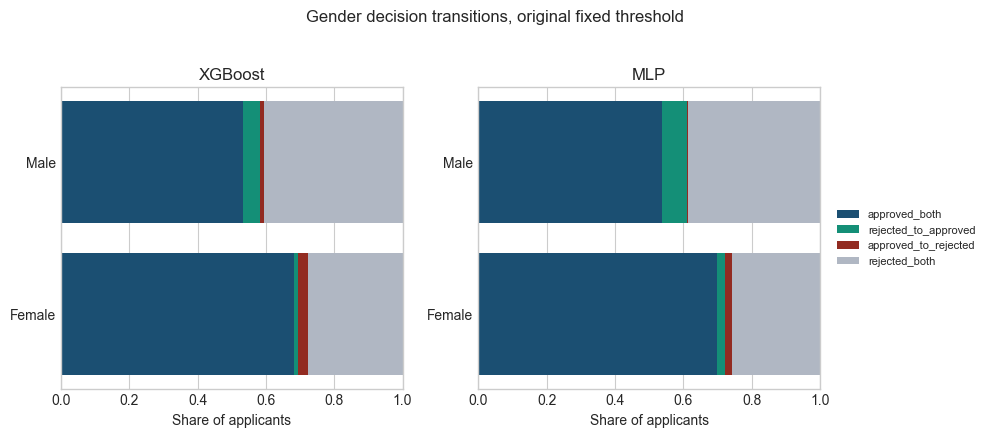

In [248]:
def subgroup_sort_key(grouping, label):
    age_order = ["<25", "25–34", "35–44", "45–54", "55–64", "65+"]
    income_order = ["Q1 low", "Q2", "Q3", "Q4 high"]
    gender_order = ["Female", "Male"]
    if grouping == "gender":
        return (gender_order.index(label) if label in gender_order else 99,)
    if grouping == "age_band":
        return (age_order.index(label) if label in age_order else 99,)
    if grouping == "income_band":
        return (income_order.index(label) if label in income_order else 99,)
    gender, rest = str(label).split(" | ", 1)
    secondary = age_order if "age" in grouping else income_order
    return (gender_order.index(gender), secondary.index(rest) if rest in secondary else 99)


def group_rates(scores, threshold, grouping):
    labels = audit_test[grouping].astype(str).to_numpy()
    approval = np.asarray(scores) < threshold
    y = y_test_array
    rows = []
    for subgroup in pd.unique(labels):
        mask = labels == subgroup
        approved = approval[mask]
        nondefault = y[mask] == 0
        default = y[mask] == 1
        rows.append({
            "grouping_variable": grouping,
            "subgroup": str(subgroup),
            "count": int(mask.sum()),
            "selection_rate": float(approved.mean()),
            "tpr_approval": float(approved[nondefault].mean()) if nondefault.any() else np.nan,
            "fpr_approval": float(approved[default].mean()) if default.any() else np.nan,
        })
    return pd.DataFrame(rows)


impact_rows = []
transition_rows = []
for policy in ["original_fixed", "validation_retuned"]:
    for architecture in ["XGBoost", "MLP"]:
        original_threshold = THRESHOLDS[architecture]
        blind_threshold = original_threshold if policy == "original_fixed" else retuned_thresholds[architecture]
        original_approval = score_sets[(architecture, "Original")] < original_threshold
        blind_approval = score_sets[(architecture, "Gender-Blind")] < blind_threshold
        for grouping in selected_groupings:
            original_rates = group_rates(score_sets[(architecture, "Original")], original_threshold, grouping)
            blind_rates = group_rates(score_sets[(architecture, "Gender-Blind")], blind_threshold, grouping)
            merged = original_rates.merge(
                blind_rates, on=["grouping_variable", "subgroup"], suffixes=("_original", "_blind"),
            )
            merged = merged.merge(support_lookup, on=["grouping_variable", "subgroup"], how="left")
            if merged["support_flag"].isna().any():
                raise AssertionError(f"Missing support flag for {grouping}.")
            labels = audit_test[grouping].astype(str).to_numpy()
            for _, row in merged.iterrows():
                mask = labels == row["subgroup"]
                approved_both = int((original_approval[mask] & blind_approval[mask]).sum())
                rejected_both = int((~original_approval[mask] & ~blind_approval[mask]).sum())
                rejected_to_approved = int((~original_approval[mask] & blind_approval[mask]).sum())
                approved_to_rejected = int((original_approval[mask] & ~blind_approval[mask]).sum())
                count = int(row["count_original"])
                if approved_both + rejected_both + rejected_to_approved + approved_to_rejected != count:
                    raise AssertionError(f"Decision transitions do not sum to {grouping} {row['subgroup']}.")
                net = rejected_to_approved - approved_to_rejected
                selection_change = float(row["selection_rate_blind"] - row["selection_rate_original"])
                if abs(net / count - selection_change) > 1e-9:
                    raise AssertionError(f"Net approval change does not match the approval-rate change for {row['subgroup']}.")
                impact_rows.append({
                    "architecture": architecture,
                    "grouping_variable": grouping,
                    "subgroup": row["subgroup"],
                    "count": count,
                    "support_flag": row["support_flag"],
                    "original_selection_rate": float(row["selection_rate_original"]),
                    "blind_selection_rate": float(row["selection_rate_blind"]),
                    "selection_rate_change": selection_change,
                    "original_tpr": float(row["tpr_approval_original"]),
                    "blind_tpr": float(row["tpr_approval_blind"]),
                    "tpr_change": float(row["tpr_approval_blind"] - row["tpr_approval_original"]),
                    "original_fpr": float(row["fpr_approval_original"]),
                    "blind_fpr": float(row["fpr_approval_blind"]),
                    "fpr_change": float(row["fpr_approval_blind"] - row["fpr_approval_original"]),
                    "threshold_policy": policy,
                })
                transition_rows.append({
                    "architecture": architecture,
                    "grouping_variable": grouping,
                    "subgroup": row["subgroup"],
                    "count": count,
                    "approved_both": approved_both,
                    "rejected_both": rejected_both,
                    "rejected_to_approved": rejected_to_approved,
                    "approved_to_rejected": approved_to_rejected,
                    "total_flipped": rejected_to_approved + approved_to_rejected,
                    "flip_rate": (rejected_to_approved + approved_to_rejected) / count,
                    "net_approval_change": net,
                    "support_flag": row["support_flag"],
                    "threshold_policy": policy,
                })

subgroup_impact = pd.DataFrame(impact_rows)
decision_changes = pd.DataFrame(transition_rows)
subgroup_impact.to_csv(MITIGATION_DIR / "subgroup_fairness_impact.csv", index=False)
decision_changes.to_csv(MITIGATION_DIR / "individual_decision_changes.csv", index=False)
fixed_impact = subgroup_impact[subgroup_impact["threshold_policy"].eq("original_fixed")].copy()
fixed_transitions = decision_changes[decision_changes["threshold_policy"].eq("original_fixed")].copy()
print("SUBGROUP FAIRNESS IMPACT BEFORE VS. AFTER MITIGATION")
with pd.option_context("display.max_rows", 20, "display.min_rows", 20):
    display(subgroup_impact.round(4))
print("INDIVIDUAL DECISION CHANGES")
with pd.option_context("display.max_rows", 20, "display.min_rows", 20):
    display(decision_changes.round(4))

for grouping in selected_groupings:
    figure, axes = plt.subplots(1, 2, figsize=(12, 0.38 * fixed_impact[fixed_impact["grouping_variable"].eq(grouping)].shape[0] / 2 + 1.8), squeeze=False)
    for axis, architecture in zip(axes[0], ["XGBoost", "MLP"]):
        part = fixed_impact[fixed_impact["architecture"].eq(architecture) & fixed_impact["grouping_variable"].eq(grouping)].copy()
        part = part.sort_values("subgroup", key=lambda values: values.map(lambda label: subgroup_sort_key(grouping, label)))
        labels = [label if flag == "ok" else f"{label} *" for label, flag in zip(part["subgroup"], part["support_flag"])]
        colors = ["#148f77" if value >= 0 else "#922b21" for value in part["selection_rate_change"]]
        axis.barh(labels, part["selection_rate_change"], color=colors)
        axis.axvline(0, color="0.35", lw=0.8)
        axis.set_xlabel("Approval-rate change")
        axis.set_title(architecture)
    figure.suptitle(f"{grouping} approval-rate change after removing gender", y=1.02)
    figure.tight_layout()
    safe_name = grouping.replace(" × ", "_").replace(" ", "_")
    figure.savefig(FIGURE_DIR / f"mitigation_approval_change_{safe_name}.png", dpi=150, bbox_inches="tight")
    display(figure)
    plt.close(figure)

gender_transitions = fixed_transitions[fixed_transitions["grouping_variable"].eq("gender")].copy()
components = ["approved_both", "rejected_to_approved", "approved_to_rejected", "rejected_both"]
component_colors = ["#1b4f72", "#148f77", "#922b21", "#b0b7c3"]
figure, axes = plt.subplots(1, 2, figsize=(10, 4.2), squeeze=False)
for axis, architecture in zip(axes[0], ["XGBoost", "MLP"]):
    part = gender_transitions[gender_transitions["architecture"].eq(architecture)].copy()
    part = part.sort_values("subgroup", key=lambda values: values.map(lambda label: subgroup_sort_key("gender", label)))
    left = np.zeros(len(part))
    for component, color in zip(components, component_colors):
        share = part[component].to_numpy() / part["count"].to_numpy()
        axis.barh(part["subgroup"], share, left=left, color=color, label=component)
        left = left + share
    axis.set_xlim(0, 1)
    axis.set_title(architecture)
    axis.set_xlabel("Share of applicants")
axes[0, 1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=8)
figure.suptitle("Gender decision transitions, original fixed threshold", y=1.03)
figure.tight_layout()
figure.savefig(FIGURE_DIR / "mitigation_gender_transitions.png", dpi=160, bbox_inches="tight")
display(figure)
plt.close(figure)


### 10.5 Mitigation Effectiveness and Fairness-Performance Trade-offs


MITIGATION EFFECTIVENESS SUMMARY


,architecture,outcome,original,gender_blind,change,assessment,threshold_policy
0,XGBoost,roc_auc,0.7689,0.7690,0.0001,unchanged,original_fixed
1,XGBoost,average_precision,0.2583,0.2565,-0.0018,worsened,original_fixed
2,XGBoost,brier_score,0.1851,0.1853,0.0002,unchanged,original_fixed
3,XGBoost,approval_rate,0.6557,0.6557,0.0000,descriptive,original_fixed
4,XGBoost,gender_demographic_parity_difference,0.1709,0.1093,-0.0617,improved,original_fixed
5,XGBoost,gender_equal_opportunity_difference,0.1589,0.0971,-0.0618,improved,original_fixed
6,XGBoost,gender_equalized_odds_difference,0.1621,0.0992,-0.0629,improved,original_fixed
7,XGBoost,female_approval_rate,0.7139,0.6929,-0.0210,descriptive,original_fixed
8,XGBoost,male_approval_rate,0.5430,0.5837,0.0407,descriptive,original_fixed
9,XGBoost,decision_flip_rate,NaN,0.0478,NaN,descriptive,original_fixed


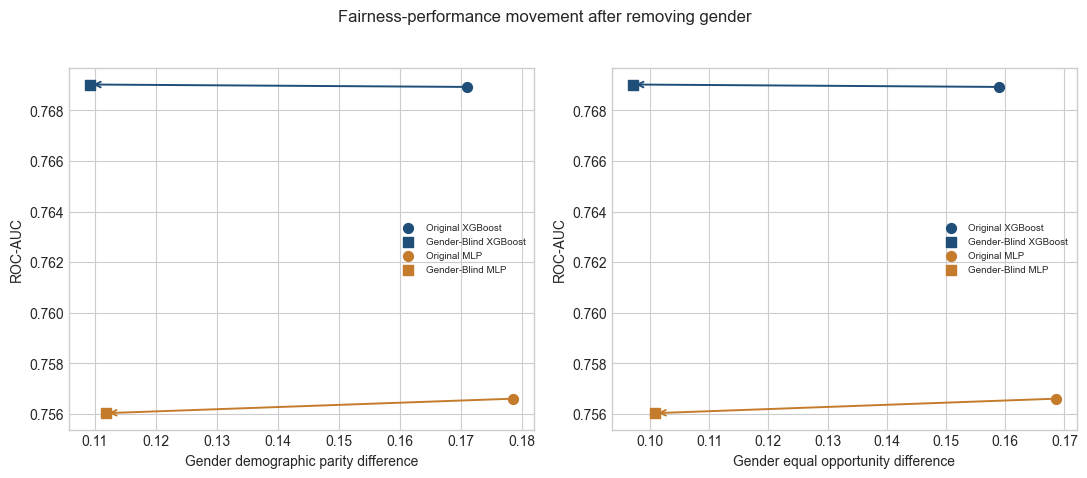

PAIRED BOOTSTRAP 95% INTERVALS FOR GENDER-BLIND MINUS ORIGINAL


,architecture,change,mean,ci_low,ci_high,n_bootstrap,threshold_policy
0,XGBoost,roc_auc_change,0.0001,-0.0014,0.0016,1000,original_fixed
1,XGBoost,average_precision_change,-0.0018,-0.0047,0.0013,1000,original_fixed
2,XGBoost,brier_score_change,0.0002,-0.0001,0.0005,1000,original_fixed
3,XGBoost,demographic_parity_difference_change,-0.0616,-0.0660,-0.0571,1000,original_fixed
4,XGBoost,equal_opportunity_difference_change,-0.0617,-0.0663,-0.0571,1000,original_fixed
5,XGBoost,equalized_odds_difference_change,-0.0622,-0.0749,-0.0506,1000,original_fixed
6,XGBoost,female_approval_rate_change,-0.0210,-0.0231,-0.0186,1000,original_fixed
7,XGBoost,male_approval_rate_change,0.0406,0.0369,0.0444,1000,original_fixed
8,MLP,roc_auc_change,-0.0006,-0.0022,0.0011,1000,original_fixed
9,MLP,average_precision_change,-0.0013,-0.0036,0.0012,1000,original_fixed


Section 10 complete. Blind models are saved separately from the original models.


In [249]:
def gender_gap(approval, female_mask, male_mask, nondefault, default):
    selection_gap = abs(approval[female_mask].mean() - approval[male_mask].mean())
    tpr_gap = abs(approval[female_mask & nondefault].mean() - approval[male_mask & nondefault].mean())
    fpr_gap = abs(approval[female_mask & default].mean() - approval[male_mask & default].mean())
    return selection_gap, tpr_gap, max(tpr_gap, fpr_gap)


female_mask = audit_test["gender"].astype(str).eq("Female").to_numpy()
male_mask = ~female_mask
nondefault = y_test_array == 0
default = y_test_array == 1
summary_rows = []
for architecture in ["XGBoost", "MLP"]:
    original_scores = score_sets[(architecture, "Original")]
    blind_scores = score_sets[(architecture, "Gender-Blind")]
    original_metrics = probability_metrics(y_test_array, original_scores, THRESHOLDS[architecture])
    blind_metrics = probability_metrics(y_test_array, blind_scores, THRESHOLDS[architecture])
    original_approval = original_scores < THRESHOLDS[architecture]
    blind_approval = blind_scores < THRESHOLDS[architecture]
    original_gaps = gender_gap(original_approval, female_mask, male_mask, nondefault, default)
    blind_gaps = gender_gap(blind_approval, female_mask, male_mask, nondefault, default)
    outcomes = {
        "roc_auc": (original_metrics["roc_auc"], blind_metrics["roc_auc"], "higher_better"),
        "average_precision": (original_metrics["average_precision"], blind_metrics["average_precision"], "higher_better"),
        "brier_score": (original_metrics["brier_score"], blind_metrics["brier_score"], "lower_better"),
        "approval_rate": (original_metrics["approval_rate"], blind_metrics["approval_rate"], "descriptive"),
        "gender_demographic_parity_difference": (original_gaps[0], blind_gaps[0], "lower_better"),
        "gender_equal_opportunity_difference": (original_gaps[1], blind_gaps[1], "lower_better"),
        "gender_equalized_odds_difference": (original_gaps[2], blind_gaps[2], "lower_better"),
        "female_approval_rate": (float(original_approval[female_mask].mean()), float(blind_approval[female_mask].mean()), "descriptive"),
        "male_approval_rate": (float(original_approval[male_mask].mean()), float(blind_approval[male_mask].mean()), "descriptive"),
        "decision_flip_rate": (
            np.nan,
            float(np.mean(original_approval != blind_approval)),
            "descriptive",
        ),
    }
    for outcome, (original, blind, rule) in outcomes.items():
        change = np.nan if outcome == "decision_flip_rate" else float(blind - original)
        if rule == "descriptive" or not np.isfinite(change):
            assessment = "descriptive"
        elif abs(change) < 1e-3:
            assessment = "unchanged"
        elif rule == "higher_better":
            assessment = "improved" if change > 0 else "worsened"
        else:
            assessment = "improved" if change < 0 else "worsened"
        summary_rows.append({
            "architecture": architecture,
            "outcome": outcome,
            "original": original,
            "gender_blind": blind,
            "change": change,
            "assessment": assessment,
            "threshold_policy": "original_fixed",
        })
effectiveness = pd.DataFrame(summary_rows)
effectiveness.to_csv(MITIGATION_DIR / "mitigation_effectiveness.csv", index=False)
print("MITIGATION EFFECTIVENESS SUMMARY")
display(effectiveness.round(6))

points = []
for architecture in ["XGBoost", "MLP"]:
    for variant, scores in (("Original", score_sets[(architecture, "Original")]), ("Gender-Blind", score_sets[(architecture, "Gender-Blind")])):
        approval = scores < THRESHOLDS[architecture]
        parity, opportunity, _odds = gender_gap(approval, female_mask, male_mask, nondefault, default)
        points.append({
            "label": f"{variant} {architecture}",
            "architecture": architecture,
            "variant": variant,
            "demographic_parity_difference": parity,
            "equal_opportunity_difference": opportunity,
            "roc_auc": probability_metrics(y_test_array, scores, THRESHOLDS[architecture])["roc_auc"],
        })
tradeoff = pd.DataFrame(points)
figure, axes = plt.subplots(1, 2, figsize=(11, 4.6), squeeze=False)
for axis, metric, xlabel in (
    (axes[0, 0], "demographic_parity_difference", "Gender demographic parity difference"),
    (axes[0, 1], "equal_opportunity_difference", "Gender equal opportunity difference"),
):
    for architecture, color in (("XGBoost", "#1f4e79"), ("MLP", "#c47b2b")):
        part = tradeoff[tradeoff["architecture"].eq(architecture)].set_index("variant")
        axis.annotate(
            "",
            xy=(part.loc["Gender-Blind", metric], part.loc["Gender-Blind", "roc_auc"]),
            xytext=(part.loc["Original", metric], part.loc["Original", "roc_auc"]),
            arrowprops={"arrowstyle": "->", "color": color, "lw": 1.4},
        )
        for variant, marker in (("Original", "o"), ("Gender-Blind", "s")):
            axis.scatter(part.loc[variant, metric], part.loc[variant, "roc_auc"], color=color, marker=marker, s=50, label=f"{variant} {architecture}")
    axis.set_xlabel(xlabel)
    axis.set_ylabel("ROC-AUC")
    axis.legend(frameon=False, fontsize=7)
figure.suptitle("Fairness-performance movement after removing gender", y=1.03)
figure.tight_layout()
figure.savefig(FIGURE_DIR / "mitigation_fairness_performance.png", dpi=160, bbox_inches="tight")
display(figure)
plt.close(figure)

N_BOOTSTRAP = 1000
bootstrap_rng = np.random.default_rng(SEED)
bootstrap_records = {architecture: [] for architecture in ["XGBoost", "MLP"]}
for _draw in range(N_BOOTSTRAP):
    sample = bootstrap_rng.integers(0, len(y_test_array), len(y_test_array))
    y_sample = y_test_array[sample]
    if len(np.unique(y_sample)) < 2:
        continue
    female_sample = female_mask[sample]
    male_sample = male_mask[sample]
    nondefault_sample = y_sample == 0
    default_sample = y_sample == 1
    if female_sample.sum() == 0 or male_sample.sum() == 0 or nondefault_sample.sum() == 0 or default_sample.sum() == 0:
        continue
    for architecture in ["XGBoost", "MLP"]:
        original = score_sets[(architecture, "Original")][sample]
        blind = score_sets[(architecture, "Gender-Blind")][sample]
        threshold = THRESHOLDS[architecture]
        original_approval = original < threshold
        blind_approval = blind < threshold
        original_gap = gender_gap(original_approval, female_sample, male_sample, nondefault_sample, default_sample)
        blind_gap = gender_gap(blind_approval, female_sample, male_sample, nondefault_sample, default_sample)
        bootstrap_records[architecture].append({
            "roc_auc_change": roc_auc_score(y_sample, blind) - roc_auc_score(y_sample, original),
            "average_precision_change": precision_recall_auc(y_sample, blind) - precision_recall_auc(y_sample, original),
            "brier_score_change": brier_score_loss(y_sample, blind) - brier_score_loss(y_sample, original),
            "demographic_parity_difference_change": blind_gap[0] - original_gap[0],
            "equal_opportunity_difference_change": blind_gap[1] - original_gap[1],
            "equalized_odds_difference_change": blind_gap[2] - original_gap[2],
            "female_approval_rate_change": blind_approval[female_sample].mean() - original_approval[female_sample].mean(),
            "male_approval_rate_change": blind_approval[male_sample].mean() - original_approval[male_sample].mean(),
        })
interval_rows = []
for architecture, records in bootstrap_records.items():
    frame = pd.DataFrame(records)
    for column in frame.columns:
        interval_rows.append({
            "architecture": architecture,
            "change": column,
            "mean": float(frame[column].mean()),
            "ci_low": float(frame[column].quantile(0.025)),
            "ci_high": float(frame[column].quantile(0.975)),
            "n_bootstrap": int(len(frame)),
            "threshold_policy": "original_fixed",
        })
bootstrap_intervals = pd.DataFrame(interval_rows)
bootstrap_intervals.to_csv(MITIGATION_DIR / "paired_bootstrap_intervals.csv", index=False)
print("PAIRED BOOTSTRAP 95% INTERVALS FOR GENDER-BLIND MINUS ORIGINAL")
display(bootstrap_intervals.round(6))

import fairlearn
versions = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "sklearn": sklearn.__version__,
    "fairlearn": fairlearn.__version__,
}
(MITIGATION_DIR / "versions.json").write_text(json.dumps({
    "versions": versions,
    "thresholds": THRESHOLDS,
    "retuned_thresholds": retuned_thresholds,
    "excluded_features": gender_columns,
}, indent=2))
print("Section 10 complete. Blind models are saved separately from the original models.")
